<center><strong>Deep Learning : Natural Language Processing</strong><br />
<strong><font color="blue">Departemen Informatika - Prodi RKA - Institut Teknologi Sepuluh Nopember</font></strong><br />
</center>

<strong>Outline Hands-On: Sentiment Analysis dengan GRU & BiGRU</strong><br />
<li> Pengenalan Sentiment Analysis & Sequence Model </li>
<li> Arsitektur GRU & BiGRU (Detail) </li>
<li> Anatomi Layer-by-Layer </li>
<li> Dataset IMDB: EDA & Preprocessing </li>
<li> Implementasi Baseline GRU </li>
<li> Bidirectional GRU (BiGRU) </li>
<li> Variasi Arsitektur: Mengganti Layer Output </li>
<li> Variasi Arsitektur: Hybrid Conv1D + BiGRU </li>
<li> Perbandingan Model & Prediksi Review Baru </li>
<li> Tugas Akhir: Sentiment Analysis Dataset Twitter </li>

---

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Setup & Persiapan Environment

<p><strong><font color="red">PENTING:</font></strong> Pastikan runtime Google Colab menggunakan <strong>GPU</strong> untuk mempercepat proses training model RNN.</p>

<p>Cara mengaktifkan GPU di Google Colab:</p>
<ol>
    <li>Klik menu <strong>Runtime</strong> → <strong>Change runtime type</strong></li>
    <li>Pada <strong>Hardware accelerator</strong>, pilih <strong>GPU (T4)</strong></li>
    <li>Klik <strong>Save</strong></li>
</ol>

In [ ]:
# Import library yang dibutuhkan
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re
import time
from collections import Counter

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import (
    Embedding, GRU, Bidirectional, Dense, Dropout,
    SpatialDropout1D, Input, GlobalMaxPooling1D, GlobalAveragePooling1D,
    Conv1D, MaxPooling1D, Concatenate
)
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

# Reproducibility
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Style plotting
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)

# Cek versi & GPU
print(f"TensorFlow version: {tf.__version__}")
gpus = tf.config.list_physical_devices('GPU')
print(f"GPU tersedia: {len(gpus)} device")

TensorFlow version: 2.20.0
GPU tersedia: 1 device


---
## 1. Pengenalan Sentiment Analysis & Sequence Model

<p><strong>Sentiment Analysis</strong> adalah task dalam Natural Language Processing (NLP) untuk <em>mengklasifikasikan opini atau emosi</em> dari sebuah teks, biasanya ke dalam kategori <strong>positif</strong>, <strong>negatif</strong>, atau <strong>netral</strong>.</p>

<p>Contoh aplikasi:</p>
<ul>
    <li>Analisis review produk e-commerce (Tokopedia, Shopee)</li>
    <li>Monitoring brand di media sosial (Twitter/X, Instagram)</li>
    <li>Customer feedback analysis</li>
    <li>Analisis sentimen politik/publik terhadap kebijakan</li>
</ul>

<p>Teks adalah data <strong>sequential</strong> — urutan kata sangat penting. Dua kalimat <em>"The food was good, not bad at all"</em> dan <em>"The food was bad, not good at all"</em> memiliki kata yang sama tetapi sentimen berbeda. Karena itu, kita membutuhkan model yang memahami <strong>urutan</strong> kata — yaitu <strong>Recurrent Neural Network (RNN)</strong> dan variannya seperti <strong>GRU</strong> dan <strong>BiGRU</strong>.</p>

---
## 2. Arsitektur GRU & BiGRU (Detail)

<p>Pada bagian ini kita akan melihat <strong>arsitektur internal</strong> dari sel GRU dan BiGRU, bagaimana gate bekerja, bagaimana hidden state di-update, dan bagaimana implementasinya di Keras.</p>

<hr>

### 2.1 Arsitektur GRU (Gated Recurrent Unit)

<p><strong>GRU</strong> diperkenalkan oleh <em>Cho et al. (2014)</em> sebagai penyederhanaan dari LSTM. GRU mengatasi masalah <strong>vanishing gradient</strong> pada vanilla RNN dengan menggunakan <strong>mekanisme gate</strong>, tetapi hanya memiliki <strong>2 gate</strong> (reset & update), lebih sederhana dari LSTM yang punya 3 gate.</p>

<p><strong>Diagram arsitektur sel GRU:</strong></p>

<p align="center">
<img src="https://colah.github.io/posts/2015-08-Understanding-LSTMs/img/LSTM3-var-GRU.png" alt="GRU Cell Architecture" width="600"/>
<br>
<em>Sumber: Christopher Olah, "Understanding LSTM Networks" (colah.github.io, 2015)</em>
</p>

<h4>Penjelasan Detail Komponen GRU:</h4>

<table border="1" cellpadding="8" cellspacing="0">
<tr>
    <th>Simbol</th><th>Nama</th><th>Fungsi</th>
</tr>
<tr>
    <td><strong>x<sub>t</sub></strong></td>
    <td>Input vektor</td>
    <td>Input pada timestep <em>t</em> (misal: word embedding)</td>
</tr>
<tr>
    <td><strong>h<sub>t-1</sub></strong></td>
    <td>Previous hidden state</td>
    <td>Hidden state dari timestep sebelumnya (memori)</td>
</tr>
<tr>
    <td><strong>z<sub>t</sub></strong></td>
    <td>Update gate</td>
    <td>Menentukan seberapa banyak informasi lama yang <strong>dipertahankan</strong></td>
</tr>
<tr>
    <td><strong>r<sub>t</sub></strong></td>
    <td>Reset gate</td>
    <td>Menentukan seberapa banyak informasi lama yang <strong>dilupakan</strong> saat menghitung kandidat</td>
</tr>
<tr>
    <td><strong>h̃<sub>t</sub></strong></td>
    <td>Candidate hidden state</td>
    <td>Kandidat hidden state baru berdasarkan input dan sebagian informasi lama</td>
</tr>
<tr>
    <td><strong>h<sub>t</sub></strong></td>
    <td>Hidden state</td>
    <td>Hidden state final hasil interpolasi antara h<sub>t-1</sub> dan h̃<sub>t</sub></td>
</tr>
</table>

<h4>Formula GRU:</h4>

<p style="font-family: monospace; background-color: #f4f4f4; padding: 10px;">
z<sub>t</sub> = σ(W<sub>z</sub> · x<sub>t</sub> + U<sub>z</sub> · h<sub>t-1</sub> + b<sub>z</sub>)&nbsp;&nbsp;&nbsp;&nbsp;# Update gate<br />
r<sub>t</sub> = σ(W<sub>r</sub> · x<sub>t</sub> + U<sub>r</sub> · h<sub>t-1</sub> + b<sub>r</sub>)&nbsp;&nbsp;&nbsp;&nbsp;# Reset gate<br />
h̃<sub>t</sub> = tanh(W<sub>h</sub> · x<sub>t</sub> + U<sub>h</sub> · (r<sub>t</sub> ⊙ h<sub>t-1</sub>) + b<sub>h</sub>)&nbsp;# Candidate<br />
h<sub>t</sub> = (1 - z<sub>t</sub>) ⊙ h<sub>t-1</sub> + z<sub>t</sub> ⊙ h̃<sub>t</sub>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;# Output
</p>

<p><em>Keterangan: σ adalah sigmoid, ⊙ adalah perkalian elemen-wise (Hadamard product).</em></p>

<h4>Intuisi Gate:</h4>

<ul>
    <li><strong>Update gate (z<sub>t</sub>)</strong> bertindak seperti <em>switch</em>:
        <ul>
            <li>Jika z<sub>t</sub> ≈ 1 → h<sub>t</sub> ≈ h̃<sub>t</sub> (percaya pada informasi baru)</li>
            <li>Jika z<sub>t</sub> ≈ 0 → h<sub>t</sub> ≈ h<sub>t-1</sub> (pertahankan informasi lama)</li>
        </ul>
    </li>
    <li><strong>Reset gate (r<sub>t</sub>)</strong> mengontrol:
        <ul>
            <li>Jika r<sub>t</sub> ≈ 0 → h̃<sub>t</sub> hanya dihitung dari x<sub>t</sub> (mulai "fresh")</li>
            <li>Jika r<sub>t</sub> ≈ 1 → h̃<sub>t</sub> memperhitungkan seluruh h<sub>t-1</sub></li>
        </ul>
    </li>
</ul>

<p><strong>Jumlah parameter GRU:</strong> <code>3 × (units × (input_dim + units) + 2 × units)</code> — faktor <strong>3</strong> karena 3 matriks bobot (update, reset, candidate).</p>

In [ ]:
# Demonstrasi: Membangun 1 layer GRU dan menghitung parameter
test_gru = Sequential([
    Input(shape=(100,)),                     # sequence length 100
    Embedding(input_dim=5000, output_dim=64),# vocab 5000, embed dim 64
    GRU(32)                                   # 32 hidden units
], name='GRU_Demo')

test_gru.summary()

# Verifikasi manual
units, input_dim = 32, 64
manual = 3 * (units * (input_dim + units) + 2 * units)
print(f"\nPerhitungan manual jumlah parameter GRU({units}) dengan input_dim={input_dim}:")
print(f"  3 × ({units} × ({input_dim} + {units}) + 2 × {units}) = {manual}")

Model: "GRU_Demo"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 100, 64)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 32)             │         9,408 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 329,408 (1.26 MB)

 Trainable params: 329,408 (1.26 MB)

 Non-trainable params: 0 (0.00 B)


Perhitungan manual jumlah parameter GRU(32) dengan input_dim=64:
  3 × (32 × (64 + 32) + 2 × 32) = 9408


<hr>

### 2.2 Arsitektur Bidirectional GRU (BiGRU)

<p><strong>BiGRU</strong> adalah perluasan GRU yang memproses sequence dari <strong>dua arah</strong> sekaligus:</p>

<ul>
    <li><strong>Forward GRU</strong>: membaca dari x<sub>1</sub> → x<sub>2</sub> → ... → x<sub>T</sub> (kiri ke kanan)</li>
    <li><strong>Backward GRU</strong>: membaca dari x<sub>T</sub> → x<sub>T-1</sub> → ... → x<sub>1</sub> (kanan ke kiri)</li>
</ul>

<p>Hidden state dari kedua arah kemudian digabung (biasanya <strong>concatenate</strong>) untuk membentuk representasi akhir.</p>

<p><strong>Diagram arsitektur BiRNN/BiGRU:</strong></p>

<p align="center">
<img src="https://d2l.ai/_images/birnn.svg" alt="Bidirectional RNN Architecture" width="550"/>
<br>
<em>Sumber: Aston Zhang et al., "Dive into Deep Learning" (d2l.ai) — arsitektur BiRNN; BiGRU menggantikan sel RNN dengan sel GRU</em>
</p>

<h4>Penjelasan Detail:</h4>

<table border="1" cellpadding="8" cellspacing="0">
<tr>
    <th>Komponen</th><th>Dimensi</th><th>Keterangan</th>
</tr>
<tr>
    <td>Forward hidden state <strong>→h<sub>t</sub></strong></td>
    <td>h</td>
    <td>Hasil GRU yang memproses dari kiri ke kanan; berisi konteks <em>sebelum</em> timestep t</td>
</tr>
<tr>
    <td>Backward hidden state <strong>←h<sub>t</sub></strong></td>
    <td>h</td>
    <td>Hasil GRU yang memproses dari kanan ke kiri; berisi konteks <em>setelah</em> timestep t</td>
</tr>
<tr>
    <td>Concatenated hidden state <strong>h<sub>t</sub></strong></td>
    <td>2h</td>
    <td>Gabungan konteks dua arah → [→h<sub>t</sub> ; ←h<sub>t</sub>]</td>
</tr>
</table>

<h4>Formula BiGRU:</h4>

<p style="font-family: monospace; background-color: #f4f4f4; padding: 10px;">
→h<sub>t</sub> = GRU<sub>forward</sub>(x<sub>t</sub>, →h<sub>t-1</sub>)<br />
←h<sub>t</sub> = GRU<sub>backward</sub>(x<sub>t</sub>, ←h<sub>t+1</sub>)<br />
h<sub>t</sub> = [→h<sub>t</sub> ; ←h<sub>t</sub>]&nbsp;&nbsp;&nbsp;&nbsp;# concatenate (default)
</p>

<h4>Mengapa BiGRU penting untuk NLP?</h4>

<p>Banyak task bahasa memerlukan <strong>konteks dua arah</strong>. Perhatikan contoh dari slide MIT 6.S191:</p>

<blockquote>
<em>"In France, I had a great time and I learnt some of the <strong>_____</strong> language."</em>
</blockquote>

<p>Untuk memprediksi kata yang hilang (jawaban: <em>French</em>), model perlu:</p>
<ul>
    <li>Konteks kiri: "In France" → petunjuk negara</li>
    <li>Konteks kanan: "language" → petunjuk bahwa kata yang hilang adalah nama bahasa</li>
</ul>

<p>GRU standar (unidirectional) hanya melihat konteks kiri, sehingga sulit memprediksi dengan akurat. BiGRU dapat mempertimbangkan <strong>kedua arah</strong>.</p>

In [ ]:
# Demonstrasi: Membangun 1 layer BiGRU
test_bigru = Sequential([
    Input(shape=(100,)),
    Embedding(input_dim=5000, output_dim=64),
    Bidirectional(GRU(32))                  # Wrapped dengan Bidirectional
], name='BiGRU_Demo')

test_bigru.summary()

print("\nPerhatikan:")
print("  - Output shape Bidirectional(GRU(32)) adalah (None, 64) = 2 × 32")
print("  - Karena forward (32) + backward (32) di-concatenate")
print("  - Jumlah parameter ~2× GRU biasa (ada 2 GRU yang dilatih paralel)")

Model: "BiGRU_Demo"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 100, 64)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 64)             │        18,816 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 338,816 (1.29 MB)

 Trainable params: 338,816 (1.29 MB)

 Non-trainable params: 0 (0.00 B)


Perhatikan:
  - Output shape Bidirectional(GRU(32)) adalah (None, 64) = 2 × 32
  - Karena forward (32) + backward (32) di-concatenate
  - Jumlah parameter ~2× GRU biasa (ada 2 GRU yang dilatih paralel)


<hr>

### 2.3 Perbandingan Visual: GRU vs BiGRU

<p>Mari kita bandingkan flow informasi antara GRU dan BiGRU dengan diagram yang dibuat secara manual:</p>

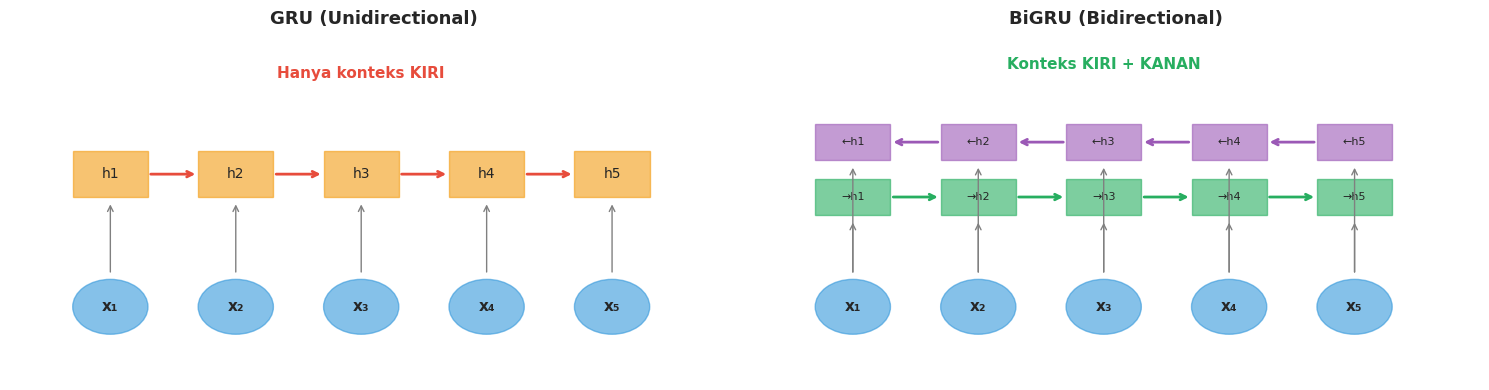

In [ ]:
# Visualisasi schematic GRU vs BiGRU
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4))

# === GRU (Unidirectional) ===
ax1.set_title('GRU (Unidirectional)', fontsize=13, fontweight='bold')
tokens = ['x₁', 'x₂', 'x₃', 'x₄', 'x₅']
for i, tok in enumerate(tokens):
    ax1.add_patch(plt.Circle((i, 0), 0.3, color='#3498db', alpha=0.6))
    ax1.text(i, 0, tok, ha='center', va='center', fontsize=11, fontweight='bold')
    ax1.add_patch(plt.Rectangle((i-0.3, 1.2), 0.6, 0.5, color='#f39c12', alpha=0.6))
    ax1.text(i, 1.45, f'h{i+1}', ha='center', va='center', fontsize=10)
    ax1.annotate('', xy=(i, 1.15), xytext=(i, 0.35),
                 arrowprops=dict(arrowstyle='->', color='gray'))
    if i < len(tokens) - 1:
        ax1.annotate('', xy=(i+0.7, 1.45), xytext=(i+0.3, 1.45),
                     arrowprops=dict(arrowstyle='->', color='#e74c3c', lw=2))

ax1.text(2, 2.5, 'Hanya konteks KIRI', ha='center', fontsize=11,
         color='#e74c3c', fontweight='bold')
ax1.set_xlim(-0.8, len(tokens)); ax1.set_ylim(-0.8, 3)
ax1.axis('off')

# === BiGRU ===
ax2.set_title('BiGRU (Bidirectional)', fontsize=13, fontweight='bold')
for i, tok in enumerate(tokens):
    ax2.add_patch(plt.Circle((i, 0), 0.3, color='#3498db', alpha=0.6))
    ax2.text(i, 0, tok, ha='center', va='center', fontsize=11, fontweight='bold')
    ax2.add_patch(plt.Rectangle((i-0.3, 1.0), 0.6, 0.4, color='#27ae60', alpha=0.6))
    ax2.text(i, 1.2, f'→h{i+1}', ha='center', va='center', fontsize=8)
    ax2.add_patch(plt.Rectangle((i-0.3, 1.6), 0.6, 0.4, color='#9b59b6', alpha=0.6))
    ax2.text(i, 1.8, f'←h{i+1}', ha='center', va='center', fontsize=8)
    ax2.annotate('', xy=(i, 0.95), xytext=(i, 0.35),
                 arrowprops=dict(arrowstyle='->', color='gray'))
    ax2.annotate('', xy=(i, 1.55), xytext=(i, 0.35),
                 arrowprops=dict(arrowstyle='->', color='gray'))
    if i < len(tokens) - 1:
        ax2.annotate('', xy=(i+0.7, 1.2), xytext=(i+0.3, 1.2),
                     arrowprops=dict(arrowstyle='->', color='#27ae60', lw=2))
    if i > 0:
        ax2.annotate('', xy=(i-0.7, 1.8), xytext=(i-0.3, 1.8),
                     arrowprops=dict(arrowstyle='->', color='#9b59b6', lw=2))

ax2.text(2, 2.6, 'Konteks KIRI + KANAN', ha='center', fontsize=11,
         color='#27ae60', fontweight='bold')
ax2.set_xlim(-0.8, len(tokens)); ax2.set_ylim(-0.8, 3)
ax2.axis('off')

plt.tight_layout()
plt.show()

---
## 3. Anatomi Layer-by-Layer

<p>Sebelum membangun model lengkap, mari kita pahami setiap <strong>layer</strong> yang akan digunakan. Setiap layer di Keras memiliki fungsi spesifik, parameter penting, dan <em>input-output shape</em> yang harus kita pahami.</p>

<p>Kita akan bahas 5 kelompok layer:</p>
<ol>
    <li><strong>Input Layers</strong>: <code>Embedding</code>, <code>SpatialDropout1D</code></li>
    <li><strong>Recurrent Layers</strong>: <code>GRU</code>, <code>Bidirectional</code></li>
    <li><strong>Aggregation Layers</strong>: <code>GlobalMaxPooling1D</code>, <code>GlobalAveragePooling1D</code>, <code>Concatenate</code></li>
    <li><strong>Convolutional Layers</strong>: <code>Conv1D</code>, <code>MaxPooling1D</code></li>
    <li><strong>Output & Regularization</strong>: <code>Dense</code>, <code>Dropout</code></li>
</ol>

### 3.1 Input Layers

#### `Embedding` — Mengubah Token Integer menjadi Vektor

<p><strong>Fungsi:</strong> Mengubah integer token (misal ID kata) menjadi vektor <em>dense</em> bernilai float. Vektor ini yang akan "dipelajari" model — kata-kata dengan makna mirip akan memiliki vektor yang mirip.</p>

<table border="1" cellpadding="6">
<tr><th>Parameter</th><th>Fungsi</th></tr>
<tr><td><code>input_dim</code></td><td>Ukuran vocabulary (jumlah kata unik + token spesial)</td></tr>
<tr><td><code>output_dim</code></td><td>Dimensi vektor embedding (biasanya 50–300)</td></tr>
<tr><td><code>input_length</code></td><td>Panjang sequence input (= MAX_LEN)</td></tr>
</table>

<p><strong>Input shape:</strong> <code>(batch, MAX_LEN)</code> — integer<br>
<strong>Output shape:</strong> <code>(batch, MAX_LEN, output_dim)</code> — float</p>

<p><strong>Contoh:</strong> Token integer <code>[1, 45, 287, 0, 0]</code> (MAX_LEN=5) akan diubah menjadi matriks 5×100 jika <code>output_dim=100</code>. Setiap baris adalah vektor representasi satu kata.</p>

#### `SpatialDropout1D` — Dropout Khusus untuk Embedding

<p><strong>Fungsi:</strong> Dropout yang men-drop <em>seluruh dimensi embedding</em> secara acak (bukan individual elemen). Lebih efektif untuk input embedding karena elemen dalam satu vektor embedding sangat berkorelasi — jika men-drop individual elemen (Dropout biasa), model tetap bisa "mengintip" informasi dari dimensi tetangga.</p>

<table border="1" cellpadding="6">
<tr><th>Parameter</th><th>Fungsi</th></tr>
<tr><td><code>rate</code></td><td>Proporsi dimensi yang di-drop (0.2 = 20%)</td></tr>
</table>

<p><strong>Input/Output shape:</strong> tetap <code>(batch, MAX_LEN, embed_dim)</code></p>

In [ ]:
# Demo: Input Layers
print("=== Demo: Embedding + SpatialDropout1D ===\n")

demo1 = Sequential([
    Input(shape=(10,)),                         # sequence length 10
    Embedding(input_dim=1000, output_dim=16),  # vocab 1000, embed 16
    SpatialDropout1D(0.2)
], name='Demo_Input_Layers')

demo1.summary()

# Coba jalankan dengan input dummy
dummy_input = np.array([[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]])
dummy_output = demo1(dummy_input)
print(f"\nInput shape : {dummy_input.shape}")
print(f"Output shape: {dummy_output.shape}")
print(f"\nContoh output (vektor untuk token pertama, 5 dim pertama):")
print(dummy_output.numpy()[0, 0, :5])

=== Demo: Embedding + SpatialDropout1D ===



Model: "Demo_Input_Layers"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 10, 16)         │        16,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d               │ (None, 10, 16)         │             0 │
│ (SpatialDropout1D)              │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,000 (62.50 KB)

 Trainable params: 16,000 (62.50 KB)

 Non-trainable params: 0 (0.00 B)


Input shape : (1, 10)
Output shape: (1, 10, 16)

Contoh output (vektor untuk token pertama, 5 dim pertama):
[ 0.03643623  0.03861551 -0.04273902  0.01479549 -0.0131455 ]


### 3.2 Recurrent Layers

#### `GRU` — Gated Recurrent Unit

<p><strong>Fungsi:</strong> Memproses sequence kata-demi-kata, menghasilkan hidden state yang "mengingat" informasi dari timestep sebelumnya. Detail mekanisme gate sudah dibahas di Section 2.1.</p>

<table border="1" cellpadding="6">
<tr><th>Parameter</th><th>Fungsi</th></tr>
<tr><td><code>units</code></td><td>Jumlah hidden units (dimensi hidden state)</td></tr>
<tr><td><code>dropout</code></td><td>Dropout pada koneksi input-to-hidden (0 - 1)</td></tr>
<tr><td><code>recurrent_dropout</code></td><td>Dropout pada koneksi recurrent (hidden-to-hidden); ⚠️ mematikan optimasi cuDNN, training jadi jauh lebih lambat</td></tr>
<tr><td><code>return_sequences</code></td><td><code>False</code> (default): hanya return hidden state timestep terakhir, shape <code>(batch, units)</code>.<br><code>True</code>: return seluruh sequence hidden state, shape <code>(batch, MAX_LEN, units)</code> — wajib untuk stacking atau pooling</td></tr>
</table>

#### `Bidirectional` — Wrapper Dua Arah

<p><strong>Fungsi:</strong> Wrapper yang menduplikasi layer recurrent menjadi 2 instance — satu forward, satu backward — lalu menggabungkan outputnya.</p>

<table border="1" cellpadding="6">
<tr><th>Parameter</th><th>Fungsi</th></tr>
<tr><td><code>layer</code></td><td>Layer recurrent yang akan dibungkus, misal <code>GRU(64)</code></td></tr>
<tr><td><code>merge_mode</code></td><td>Cara menggabungkan: <code>'concat'</code> (default, gabung → 2×units), <code>'sum'</code>, <code>'mul'</code>, <code>'ave'</code>, atau <code>None</code> (list 2 tensor terpisah)</td></tr>
</table>

<p><strong>Output shape</strong> (dengan <code>merge_mode='concat'</code>, default):</p>
<ul>
    <li>Jika <code>return_sequences=False</code>: <code>(batch, 2×units)</code></li>
    <li>Jika <code>return_sequences=True</code>: <code>(batch, MAX_LEN, 2×units)</code></li>
</ul>

In [ ]:
# Demo: Recurrent Layers
print("=== Demo 1: GRU return_sequences=False (default) ===\n")
demo2a = Sequential([
    Input(shape=(10,)),
    Embedding(1000, 16),
    GRU(32)  # default: return_sequences=False
], name='Demo_GRU_Last')
demo2a.summary()
out = demo2a(np.array([[1,2,3,4,5,6,7,8,9,10]]))
print(f"Output shape: {out.shape}  ← hanya timestep terakhir\n")

print("=== Demo 2: GRU return_sequences=True ===\n")
demo2b = Sequential([
    Input(shape=(10,)),
    Embedding(1000, 16),
    GRU(32, return_sequences=True)  # <-- return semua timestep
], name='Demo_GRU_All')
demo2b.summary()
out = demo2b(np.array([[1,2,3,4,5,6,7,8,9,10]]))
print(f"Output shape: {out.shape}  ← semua timestep\n")

print("=== Demo 3: Bidirectional(GRU) ===\n")
demo2c = Sequential([
    Input(shape=(10,)),
    Embedding(1000, 16),
    Bidirectional(GRU(32))
], name='Demo_BiGRU')
demo2c.summary()
out = demo2c(np.array([[1,2,3,4,5,6,7,8,9,10]]))
print(f"Output shape: {out.shape}  ← 2 × 32 = 64 (concat forward + backward)")

=== Demo 1: GRU return_sequences=False (default) ===



Model: "Demo_GRU_Last"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ (None, 10, 16)         │        16,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_2 (GRU)                     │ (None, 32)             │         4,800 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,800 (81.25 KB)

 Trainable params: 20,800 (81.25 KB)

...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_5 (Embedding)         │ (None, 10, 16)         │        16,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 64)             │         9,600 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,600 (100.00 KB)

 Trainable params: 25,600 (100.00 KB)

 Non-trainable params: 0 (0.00 B)

Output shape: (1, 64)  ← 2 × 32 = 64 (concat forward + backward)


### 3.3 Aggregation Layers (Pooling & Concat)

<p>Setelah <code>return_sequences=True</code>, kita memiliki output shape <code>(batch, MAX_LEN, units)</code>. Kita perlu "mereduksi" dimensi MAX_LEN menjadi satu vektor sebelum masuk ke Dense.</p>

#### `GlobalMaxPooling1D`

<p><strong>Fungsi:</strong> Untuk setiap dimensi, ambil <strong>nilai maksimum</strong> dari seluruh timestep. Intuisinya: menangkap fitur paling "mencolok" dari sequence.</p>

<p><strong>Input:</strong> <code>(batch, T, D)</code> → <strong>Output:</strong> <code>(batch, D)</code></p>

#### `GlobalAveragePooling1D`

<p><strong>Fungsi:</strong> Untuk setiap dimensi, ambil <strong>rata-rata</strong> dari seluruh timestep. Intuisinya: menangkap fitur "rata-rata" atau keseluruhan tone.</p>

#### `Concatenate`

<p><strong>Fungsi:</strong> Menggabungkan beberapa tensor di sepanjang axis tertentu (default axis=-1). Dipakai misalnya untuk gabungkan MaxPool dan AvgPool agar model dapat kedua informasi.</p>

<p><strong>Input:</strong> list tensor dengan dimensi yang sama kecuali axis concat → <strong>Output:</strong> tensor dengan axis concat dijumlah</p>

In [ ]:
# Demo: Aggregation Layers
print("=== Demo: GlobalMaxPool, GlobalAvgPool, Concatenate ===\n")

# Input: (batch=1, timesteps=10, features=32)
dummy = np.random.randn(1, 10, 32).astype(np.float32)

# GlobalMaxPooling1D
max_layer = GlobalMaxPooling1D()
max_out = max_layer(dummy)
print(f"GlobalMaxPooling1D:    input {dummy.shape}  →  output {max_out.shape}")

# GlobalAveragePooling1D
avg_layer = GlobalAveragePooling1D()
avg_out = avg_layer(dummy)
print(f"GlobalAveragePooling1D: input {dummy.shape}  →  output {avg_out.shape}")

# Concatenate (gabung 2 tensor di axis terakhir)
concat_layer = Concatenate()
cat_out = concat_layer([max_out, avg_out])
print(f"Concatenate([max, avg]): input 2×{max_out.shape}  →  output {cat_out.shape}")

print("\nContoh arsitektur BiGRU → GlobalMaxPool:")
demo3 = Sequential([
    Input(shape=(10,)),
    Embedding(1000, 16),
    Bidirectional(GRU(32, return_sequences=True)),  # (None, 10, 64)
    GlobalMaxPooling1D()                             # (None, 64)
], name='Demo_Aggregation')
demo3.summary()

=== Demo: GlobalMaxPool, GlobalAvgPool, Concatenate ===

GlobalMaxPooling1D:    input (1, 10, 32)  →  output (1, 32)
GlobalAveragePooling1D: input (1, 10, 32)  →  output (1, 32)
Concatenate([max, avg]): input 2×(1, 32)  →  output (1, 64)

Contoh arsitektur BiGRU → GlobalMaxPool:


Model: "Demo_Aggregation"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_6 (Embedding)         │ (None, 10, 16)         │        16,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_2 (Bidirectional) │ (None, 10, 64)         │         9,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d_1          │ (None, 64)             │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,600 (100.00 KB)

 Trainable params: 25,600 (100.00 KB)

 Non-trainable params: 0 (0.00 B)

### 3.4 Convolutional Layers (untuk Hybrid Model)

#### `Conv1D` — Konvolusi 1 Dimensi

<p><strong>Fungsi:</strong> Men-scan sequence dengan "window" sepanjang <code>kernel_size</code> dan menghasilkan <em>feature map</em>. Dalam NLP, Conv1D menangkap pola <strong>n-gram</strong> — misal bigram "not good", trigram "very very good".</p>

<table border="1" cellpadding="6">
<tr><th>Parameter</th><th>Fungsi</th></tr>
<tr><td><code>filters</code></td><td>Jumlah filter (= jumlah feature map output)</td></tr>
<tr><td><code>kernel_size</code></td><td>Panjang window konvolusi (biasanya 3, 5, 7)</td></tr>
<tr><td><code>padding</code></td><td><code>'same'</code>: output panjang sama dengan input; <code>'valid'</code>: output lebih pendek</td></tr>
<tr><td><code>activation</code></td><td>Biasanya <code>'relu'</code></td></tr>
</table>

<p><strong>Input:</strong> <code>(batch, T, D)</code> → <strong>Output:</strong> <code>(batch, T', filters)</code></p>

#### `MaxPooling1D` — Reduksi Timestep

<p><strong>Fungsi:</strong> Mengecilkan dimensi timestep dengan mengambil max dari window berukuran <code>pool_size</code>. Misal <code>pool_size=2</code> akan memperpendek sequence menjadi setengah.</p>

<p><strong>Perbedaan dengan <code>GlobalMaxPooling1D</code>:</strong></p>
<ul>
    <li><code>MaxPooling1D(2)</code>: local window, memperpendek tapi masih ada dimensi timestep</li>
    <li><code>GlobalMaxPooling1D()</code>: seluruh sequence, menghilangkan dimensi timestep</li>
</ul>

In [ ]:
# Demo: Convolutional Layers
print("=== Demo: Conv1D + MaxPooling1D ===\n")

demo4 = Sequential([
    Input(shape=(200,)),
    Embedding(1000, 64),                                    # (None, 200, 64)
    Conv1D(filters=32, kernel_size=5, padding='same',
           activation='relu'),                               # (None, 200, 32)
    MaxPooling1D(pool_size=2),                               # (None, 100, 32)
    Bidirectional(GRU(16))                                   # (None, 32)
], name='Demo_Conv_BiGRU')

demo4.summary()

print("\nPerhatikan perubahan shape:")
print("  - Embedding                 → (None, 200, 64)")
print("  - Conv1D(32, kernel=5)      → (None, 200, 32)  [feature map 32 channel]")
print("  - MaxPooling1D(2)           → (None, 100, 32)  [sequence dipendek 1/2]")
print("  - Bidirectional(GRU(16))    → (None, 32)       [16 forward + 16 backward]")

=== Demo: Conv1D + MaxPooling1D ===



Model: "Demo_Conv_BiGRU"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_7 (Embedding)         │ (None, 200, 64)        │        64,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 200, 32)        │        10,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 100, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_3 (Bidirectional) │ (None, 32)             │         4,800 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 79,072 (308.88 KB)

 Trainable params: 79,072 (308.88 KB)

 Non-trainable params: 0 (0.00 B)


Perhatikan perubahan shape:
  - Embedding                 → (None, 200, 64)
  - Conv1D(32, kernel=5)      → (None, 200, 32)  [feature map 32 channel]
  - MaxPooling1D(2)           → (None, 100, 32)  [sequence dipendek 1/2]
  - Bidirectional(GRU(16))    → (None, 32)       [16 forward + 16 backward]


### 3.5 Output & Regularization

#### `Dense` — Fully Connected Layer

<p><strong>Fungsi:</strong> Layer linear standar <code>y = Wx + b</code>, diikuti activation function. Dipakai sebagai:</p>
<ul>
    <li><strong>Hidden layer</strong> (menambah kapasitas model) — gunakan <code>activation='relu'</code></li>
    <li><strong>Output layer</strong> — untuk klasifikasi biner gunakan <code>Dense(1, 'sigmoid')</code>; multi-kelas gunakan <code>Dense(n_classes, 'softmax')</code></li>
</ul>

#### `Dropout` — Regularisasi Standar

<p><strong>Fungsi:</strong> Secara acak men-drop <code>rate</code> persen unit saat training. Mencegah overfitting. Biasanya ditaruh setelah Dense hidden layer.</p>

<table border="1" cellpadding="6">
<tr><th>Parameter</th><th>Fungsi</th></tr>
<tr><td><code>rate</code></td><td>Proporsi unit yang di-drop (biasanya 0.2–0.5)</td></tr>
</table>

In [ ]:
# Demo: Output Layers (binary vs multi-class)
print("=== Demo 1: Output binary classification ===\n")
demo5a = Sequential([
    Input(shape=(64,)),
    Dense(32, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='sigmoid')    # <-- 1 unit, sigmoid, untuk biner
], name='Demo_Binary_Output')
demo5a.summary()

print("\n=== Demo 2: Output multi-class (3 kelas) ===\n")
demo5b = Sequential([
    Input(shape=(64,)),
    Dense(32, activation='relu'),
    Dropout(0.3),
    Dense(3, activation='softmax')    # <-- 3 unit, softmax, untuk multi-kelas
], name='Demo_Multiclass_Output')
demo5b.summary()

print("\nPerbedaan kunci:")
print("  - Binary    : Dense(1, 'sigmoid')  + loss='binary_crossentropy'")
print("  - Multiclass: Dense(n, 'softmax')  + loss='categorical_crossentropy'")

=== Demo 1: Output binary classification ===



Model: "Demo_Binary_Output"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,113 (8.25 KB)

 Trainable params: 2,113 (8.25 KB)

...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,179 (8.51 KB)

 Trainable params: 2,179 (8.51 KB)

 Non-trainable params: 0 (0.00 B)


Perbedaan kunci:
  - Binary    : Dense(1, 'sigmoid')  + loss='binary_crossentropy'
  - Multiclass: Dense(n, 'softmax')  + loss='categorical_crossentropy'


### 3.6 Ringkasan Layer

<table border="1" cellpadding="8" cellspacing="0">
<tr><th>Layer</th><th>Kapan Dipakai</th><th>Input Shape</th><th>Output Shape</th></tr>
<tr><td><code>Embedding</code></td><td>Layer pertama untuk input teks</td><td>(B, T)</td><td>(B, T, D)</td></tr>
<tr><td><code>SpatialDropout1D</code></td><td>Setelah Embedding, untuk regularisasi</td><td>(B, T, D)</td><td>(B, T, D)</td></tr>
<tr><td><code>Conv1D</code></td><td>Menangkap pola n-gram lokal</td><td>(B, T, D)</td><td>(B, T', F)</td></tr>
<tr><td><code>MaxPooling1D(k)</code></td><td>Memperpendek sequence</td><td>(B, T, F)</td><td>(B, T/k, F)</td></tr>
<tr><td><code>GRU(U)</code></td><td>Modeling sequence 1-arah</td><td>(B, T, D)</td><td>(B, U) atau (B, T, U)</td></tr>
<tr><td><code>Bidirectional(GRU(U))</code></td><td>Modeling sequence 2-arah</td><td>(B, T, D)</td><td>(B, 2U) atau (B, T, 2U)</td></tr>
<tr><td><code>GlobalMaxPooling1D</code></td><td>Ambil fitur mencolok dari sequence</td><td>(B, T, D)</td><td>(B, D)</td></tr>
<tr><td><code>GlobalAveragePooling1D</code></td><td>Ambil fitur rata-rata dari sequence</td><td>(B, T, D)</td><td>(B, D)</td></tr>
<tr><td><code>Concatenate</code></td><td>Menggabung beberapa tensor</td><td>list [(B, D1), (B, D2)]</td><td>(B, D1+D2)</td></tr>
<tr><td><code>Dense(U, act)</code></td><td>Hidden/output layer</td><td>(B, D)</td><td>(B, U)</td></tr>
<tr><td><code>Dropout(r)</code></td><td>Regularisasi di antara Dense</td><td>(B, D)</td><td>(B, D)</td></tr>
</table>
<p><em>Keterangan: B=batch, T=timesteps, D=features, U=units, F=filters.</em></p>

<h3><font color="blue">Latihan 1:</font></h3>

<ul>
    <li>Gunakan table di atas untuk <strong>menggambar di kertas</strong> transformasi shape untuk arsitektur berikut:
        <code>Input(200) → Embedding(10000, 100) → Bidirectional(GRU(64, return_sequences=True)) → GlobalMaxPooling1D() → Dense(1, sigmoid)</code>
    </li>
    <li>Bangun model di atas di Keras dan verifikasi shape-nya dengan <code>model.summary()</code>.</li>
    <li>Hitung manual jumlah parameter <strong>Bidirectional(GRU(64))</strong> dengan input_dim=100. Bandingkan dengan output <code>model.summary()</code>.</li>
</ul>

In [ ]:
# Kerjakan Latihan 1 pada cell berikut ini

In [ ]:
# Implementasi Model di Keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, Bidirectional, GRU, GlobalMaxPooling1D, Dense

# Mendefinisikan konstanta sesuai instruksi agar mudah dibaca
MAX_LEN = 200
VOCAB_SIZE = 10000
EMBEDDING_DIM = 100

latihan1_model = Sequential([
    Input(shape=(MAX_LEN,)),
    Embedding(input_dim=VOCAB_SIZE, output_dim=EMBEDDING_DIM),
    Bidirectional(GRU(64, return_sequences=True)),
    GlobalMaxPooling1D(),
    Dense(1, activation='sigmoid')
], name='Latihan_1_BiGRU')

# Verifikasi shape dan parameter
latihan1_model.summary()

Model: "Latihan_1_BiGRU"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_8 (Embedding)         │ (None, 200, 100)       │     1,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_4 (Bidirectional) │ (None, 200, 128)       │        63,744 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d_2          │ (None, 128)            │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,063,873 (4.06 MB)

 Trainable params: 1,063,873 (4.06 MB)

 Non-trainable params: 0 (0.00 B)

***

### Perhitungan Manual Parameter Bidirectional GRU

**Diketahui:**
* **Dimensi Input ($input\_dim$):** 100 (berasal dari *output* layer Embedding)
* **Jumlah Unit ($units$):** 64 (jumlah *hidden units* pada sel GRU)

**Rumus Dasar Parameter 1 Layer GRU:**
$$\text{Param}_{\text{GRU}} = 3 \times (\text{units} \times (\text{input\_dim} + \text{units}) + 2 \times \text{units})$$

**1. Menghitung Parameter 1 Arah (Forward GRU)**
Substitusi nilai yang diketahui ke dalam formula:
$$\text{Param}_{\text{Forward}} = 3 \times (64 \times (100 + 64) + 2 \times 64)$$
$$\text{Param}_{\text{Forward}} = 3 \times (64 \times 164 + 128)$$
$$\text{Param}_{\text{Forward}} = 3 \times (10496 + 128)$$
$$\text{Param}_{\text{Forward}} = 3 \times 10624$$
$$\text{Param}_{\text{Forward}} = 31872$$

**2. Menghitung Total Parameter Bidirectional GRU**
*Layer* `Bidirectional` membungkus dua unit GRU yang beroperasi secara paralel (satu membaca sekuens maju, satu membaca mundur). Karena keduanya menerima input yang identik, total parameternya adalah persis dua kali lipat dari GRU satu arah.
$$\text{Total Parameter} = 2 \times \text{Param}_{\text{Forward}}$$
$$\text{Total Parameter} = 2 \times 31872$$
$$\text{Total Parameter} = 63744$$

> **Kesimpulan:** Total parameter untuk layer `Bidirectional(GRU(64))` dengan dimensi input 100 adalah **63744 parameter**. Hasil ini memvalidasi *output* yang dihasilkan oleh `model.summary()`.

***

---
## 4. Dataset IMDB: EDA & Preprocessing

<p><strong>IMDB</strong> adalah dataset klasik untuk sentiment analysis:</p>
<ul>
    <li><strong>50.000 ulasan film</strong> (25.000 train + 25.000 test)</li>
    <li>Label biner: <strong>1 = positif</strong>, <strong>0 = negatif</strong></li>
    <li>Dataset seimbang (50/50 antar kelas)</li>
    <li>Sudah ter-<em>tokenize</em> menjadi integer (setiap integer mewakili satu kata)</li>
</ul>

### 4.1 Load Dataset

In [ ]:
# Konfigurasi global
VOCAB_SIZE = 10000    # Hanya ambil 10.000 kata yang paling sering muncul
MAX_LEN = 200         # Setiap review dipotong/di-padding ke 200 token
EMBEDDING_DIM = 100   # Dimensi vektor embedding

# Load dataset
print("Loading IMDB dataset...")
(x_train_raw, y_train), (x_test_raw, y_test) = imdb.load_data(num_words=VOCAB_SIZE)

print(f"Training samples: {len(x_train_raw)}")
print(f"Test samples    : {len(x_test_raw)}")
print(f"\nContoh review (integer ids): {x_train_raw[0][:20]}...")
print(f"Label                       : {y_train[0]}  ({'positive' if y_train[0]==1 else 'negative'})")

Loading IMDB dataset...
17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Training samples: 25000
Test samples    : 25000

Contoh review (integer ids): [1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25]...
Label                       : 1  (positive)


### 4.2 Exploratory Data Analysis (EDA)

<p>Sebelum training, kita pahami dulu karakteristik data dengan beberapa analisis:</p>
<ol>
    <li>Distribusi label (apakah seimbang?)</li>
    <li>Distribusi panjang review</li>
    <li>Perbandingan panjang review per kelas</li>
    <li>Kata-kata paling sering muncul per kelas</li>
</ol>

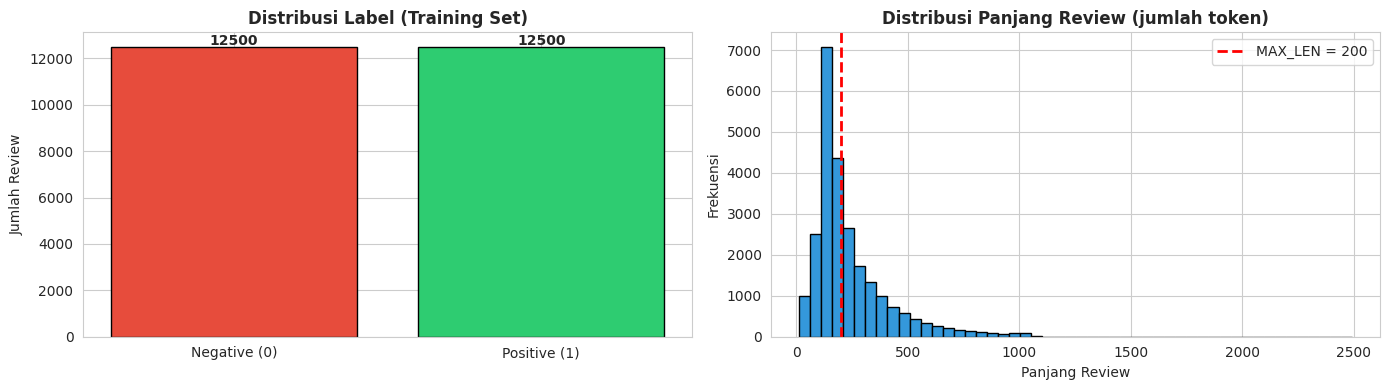


Statistik panjang review:
  Mean  : 238.7
  Median: 178.0
  Max   : 2494
  Min   : 11

Review > MAX_LEN (200): 42.71%


In [ ]:
# EDA 1: Distribusi label & panjang review
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Plot 1: Distribusi label
train_labels = pd.Series(y_train).value_counts().sort_index()
axes[0].bar(['Negative (0)', 'Positive (1)'], train_labels.values,
            color=['#e74c3c', '#2ecc71'], edgecolor='black')
axes[0].set_title('Distribusi Label (Training Set)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Jumlah Review')
for i, v in enumerate(train_labels.values):
    axes[0].text(i, v + 100, str(v), ha='center', fontweight='bold')

# Plot 2: Distribusi panjang review
review_lengths = [len(r) for r in x_train_raw]
axes[1].hist(review_lengths, bins=50, color='#3498db', edgecolor='black')
axes[1].axvline(MAX_LEN, color='red', linestyle='--', linewidth=2,
                label=f'MAX_LEN = {MAX_LEN}')
axes[1].set_title('Distribusi Panjang Review (jumlah token)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Panjang Review'); axes[1].set_ylabel('Frekuensi')
axes[1].legend()

plt.tight_layout(); plt.show()

print(f"\nStatistik panjang review:")
print(f"  Mean  : {np.mean(review_lengths):.1f}")
print(f"  Median: {np.median(review_lengths):.1f}")
print(f"  Max   : {np.max(review_lengths)}")
print(f"  Min   : {np.min(review_lengths)}")
print(f"\nReview > MAX_LEN ({MAX_LEN}): "
      f"{sum(1 for l in review_lengths if l > MAX_LEN)/len(review_lengths)*100:.2f}%")

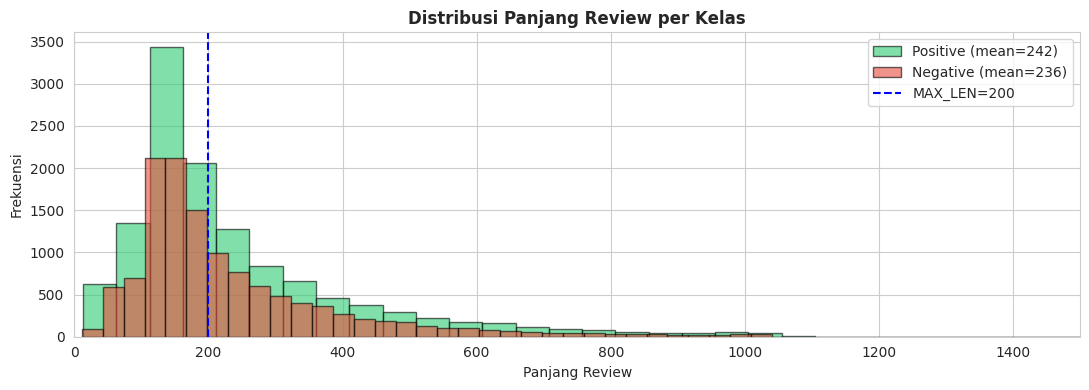

Mean panjang review — Positive: 241.6, Negative: 235.9


In [ ]:
# EDA 2: Perbandingan panjang review per kelas
pos_lengths = [len(r) for r, y in zip(x_train_raw, y_train) if y == 1]
neg_lengths = [len(r) for r, y in zip(x_train_raw, y_train) if y == 0]

fig, ax = plt.subplots(figsize=(11, 4))
ax.hist(pos_lengths, bins=50, alpha=0.6, color='#2ecc71',
        label=f'Positive (mean={np.mean(pos_lengths):.0f})', edgecolor='black')
ax.hist(neg_lengths, bins=50, alpha=0.6, color='#e74c3c',
        label=f'Negative (mean={np.mean(neg_lengths):.0f})', edgecolor='black')
ax.axvline(MAX_LEN, color='blue', linestyle='--', label=f'MAX_LEN={MAX_LEN}')
ax.set_title('Distribusi Panjang Review per Kelas', fontweight='bold')
ax.set_xlabel('Panjang Review'); ax.set_ylabel('Frekuensi')
ax.set_xlim(0, 1500)
ax.legend()
plt.tight_layout(); plt.show()

print(f"Mean panjang review — Positive: {np.mean(pos_lengths):.1f}, Negative: {np.mean(neg_lengths):.1f}")

In [ ]:
# EDA 3: Mempersiapkan decoder untuk konversi integer -> kata
word_index = imdb.get_word_index()
# Keras menggunakan offset: 0=pad, 1=start, 2=unknown, 3=unused
index_word = {v + 3: k for k, v in word_index.items()}
index_word[0] = '<PAD>'
index_word[1] = '<START>'
index_word[2] = '<UNK>'
index_word[3] = '<UNUSED>'

def decode_review(encoded_review):
    return ' '.join([index_word.get(i, '?') for i in encoded_review])

# Contoh 2 review
for i in [0, 1]:
    label = 'POSITIVE' if y_train[i] == 1 else 'NEGATIVE'
    print(f"--- Review #{i} [{label}] ---")
    print(decode_review(x_train_raw[i])[:350] + "...\n")

1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 1s 1us/step
--- Review #0 [POSITIVE] ---
<START> this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert <UNK> is an amazing actor and now the same being director <UNK> father came from the same scottish island as myself so i loved the fact there was a real connection with this film t...

--- Review #1 [NEGATIVE] ---
<START> big hair big boobs bad music and a giant safety pin these are the words to best describe this terrible movie i love cheesy horror movies and i've seen hundreds but this had got to be on of the worst ever made the plot is paper thin and ridiculous the acting is an abomination the script is completely laughable the best is the end showdown wi...



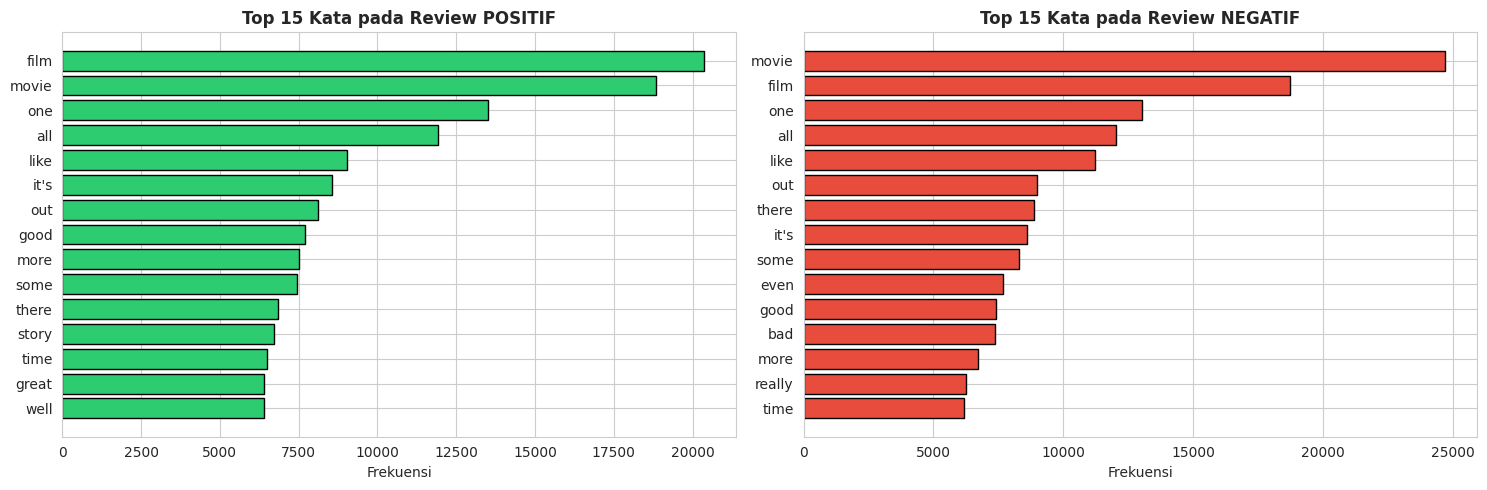

In [ ]:
# EDA 4: Kata-kata paling sering muncul per kelas
stopwords = {'the','a','an','and','or','but','is','are','was','were','be','been',
             'being','have','has','had','do','does','did','will','would','can',
             'could','should','may','might','must','shall','of','in','on','at',
             'to','for','with','from','by','about','as','it','this','that','these',
             'those','i','you','he','she','we','they','his','her','my','your','our',
             'their','him','me','us','them','what','which','who','when','where','why',
             'how','so','if','then','than','too','very','just','also','only','not',
             '<PAD>','<START>','<UNK>','<UNUSED>','s','t','br'}

def top_words(reviews, labels, target_label, topk=15):
    counter = Counter()
    for review, y in zip(reviews, labels):
        if y == target_label:
            for tok in review:
                word = index_word.get(tok, '?')
                if word not in stopwords and len(word) > 2:
                    counter[word] += 1
    return counter.most_common(topk)

top_pos = top_words(x_train_raw, y_train, target_label=1, topk=15)
top_neg = top_words(x_train_raw, y_train, target_label=0, topk=15)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

words_p = [w for w, _ in top_pos][::-1]
counts_p = [c for _, c in top_pos][::-1]
axes[0].barh(words_p, counts_p, color='#2ecc71', edgecolor='black')
axes[0].set_title('Top 15 Kata pada Review POSITIF', fontweight='bold')
axes[0].set_xlabel('Frekuensi')

words_n = [w for w, _ in top_neg][::-1]
counts_n = [c for _, c in top_neg][::-1]
axes[1].barh(words_n, counts_n, color='#e74c3c', edgecolor='black')
axes[1].set_title('Top 15 Kata pada Review NEGATIF', fontweight='bold')
axes[1].set_xlabel('Frekuensi')

plt.tight_layout(); plt.show()

<p><strong>Observasi dari EDA:</strong></p>
<ul>
    <li>Dataset <strong>seimbang</strong> (50/50) → tidak perlu handling class imbalance</li>
    <li>Median panjang review ~178 token → <code>MAX_LEN=200</code> mencakup sebagian besar review</li>
    <li>Panjang review positif dan negatif cukup <strong>mirip</strong> → panjang bukan feature pembeda</li>
</ul>

### 4.3 Preprocessing: Padding & Splitting

<p>Setelah EDA, kita lakukan preprocessing untuk menyiapkan data ke format yang bisa diproses model:</p>

<ol>
    <li><strong>Padding & Truncating</strong> — menyamakan panjang semua review ke <code>MAX_LEN</code>:
        <ul>
            <li>Review lebih pendek → di-<em>pad</em> dengan 0 di depan (<code>padding='pre'</code>)</li>
            <li>Review lebih panjang → di-<em>truncate</em> (<code>truncating='pre'</code>, memotong awal)</li>
        </ul>
    </li>
    <li><strong>Train/Validation Split</strong> — pisahkan 20% data training untuk validasi, dengan <code>stratify</code> agar proporsi kelas tetap seimbang</li>
</ol>

<p><strong>Catatan tentang <code>pre</code> vs <code>post</code>:</strong></p>
<ul>
    <li><code>padding='pre'</code> (default): 0 di <strong>depan</strong> — sering lebih baik untuk RNN</li>
    <li><code>truncating='pre'</code>: memotong di <strong>awal</strong> — menjaga bagian akhir review (biasanya lebih informatif)</li>
</ul>

In [ ]:
# Padding sequence ke panjang tetap
x_train_padded = pad_sequences(x_train_raw, maxlen=MAX_LEN, padding='pre', truncating='pre')
x_test         = pad_sequences(x_test_raw,  maxlen=MAX_LEN, padding='pre', truncating='pre')

# Split training → train + validation (80/20, stratified)
x_train, x_val, y_train, y_val = train_test_split(
    x_train_padded, y_train, test_size=0.2, random_state=SEED, stratify=y_train
)

print(f"Training  : {x_train.shape}")
print(f"Validation: {x_val.shape}")
print(f"Test      : {x_test.shape}")
print(f"\nContoh setelah padding (20 token pertama):")
print(x_train[0][:20])
print(f"\nCek balance setelah split:")
print(f"  Train: pos={np.sum(y_train==1)}, neg={np.sum(y_train==0)}")
print(f"  Val  : pos={np.sum(y_val==1)}, neg={np.sum(y_val==0)}")

Training  : (20000, 200)
Validation: (5000, 200)
Test      : (25000, 200)

Contoh setelah padding (20 token pertama):
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]

Cek balance setelah split:
  Train: pos=10000, neg=10000
  Val  : pos=2500, neg=2500


<h3><font color="blue">Latihan 2:</font></h3>

<ul>
    <li>Hitung berapa persen <strong>token <code>&lt;UNK&gt;</code></strong> (integer 2) dalam data training. Apakah proporsinya signifikan?</li>
    <li>Coba ganti <code>VOCAB_SIZE</code> menjadi <strong>5000</strong> dan <strong>20000</strong>. Bagaimana pengaruhnya ke proporsi <code>&lt;UNK&gt;</code>?</li>
    <li>Coba ganti <code>truncating='pre'</code> menjadi <code>truncating='post'</code>. Menurut Anda mana yang lebih baik untuk sentiment analysis dan mengapa?</li>
</ul>

<p><strong>Hint UNK proportion:</strong></p>

```python
unk_count = sum(1 for r in x_train_raw for t in r if t == 2)
total = sum(len(r) for r in x_train_raw)
print(f"UNK ratio: {unk_count/total*100:.2f}%")
```

In [ ]:
# Kerjakan Latihan 2 pada cell berikut ini

In [ ]:
# Menghitung proporsi token <UNK>

unk_count = sum(1 for review in x_train_raw for token in review if token == 2)
total_tokens = sum(len(review) for review in x_train_raw)

unk_ratio = unk_count / total_tokens * 100

print("=== HASIL PERHITUNGAN ===")
print(f"Jumlah token <UNK> : {unk_count:,}")
print(f"Total token        : {total_tokens:,}")
print(f"UNK Ratio          : {unk_ratio:.2f}%")

print("\n=== KESIMPULAN ===")

if unk_ratio < 5:
    print("Proporsi token <UNK> relatif kecil sehingga sebagian besar kata masih dapat direpresentasikan dengan baik oleh vocabulary.")
elif unk_ratio < 10:
    print("Proporsi token <UNK> cukup signifikan namun informasi utama masih banyak dipertahankan.")
else:
    print("Proporsi token <UNK> cukup besar sehingga banyak informasi teks yang hilang akibat keterbatasan vocabulary.")

=== HASIL PERHITUNGAN ===
Jumlah token <UNK> : 341,611
Total token        : 5,967,841
UNK Ratio          : 5.72%

=== KESIMPULAN ===
Proporsi token <UNK> cukup signifikan namun informasi utama masih banyak dipertahankan.


In [ ]:
# Mengganti VOCAB_SIZE untuk melihat pengaruhnya

from tensorflow.keras.datasets import imdb

def analyze_vocab(vocab_size):

    (x_train_raw, _), (_, _) = imdb.load_data(num_words=vocab_size)

    unk_count = sum(
        1 for review in x_train_raw
        for token in review
        if token == 2
    )

    total_tokens = sum(len(review) for review in x_train_raw)

    unk_ratio = unk_count / total_tokens * 100

    print(f"VOCAB_SIZE = {vocab_size}")
    print(f"UNK Ratio  = {unk_ratio:.2f}%")
    print()

    return unk_ratio

ratio_5000 = analyze_vocab(5000)
ratio_10000 = analyze_vocab(10000)
ratio_20000 = analyze_vocab(20000)

print("=== KESIMPULAN ===")

if ratio_5000 > ratio_10000 > ratio_20000:
    print("Semakin besar vocabulary, semakin kecil proporsi token <UNK>.")
    print("Vocabulary yang lebih besar mampu menyimpan lebih banyak informasi dari dataset.")
else:
    print("Hasil eksperimen perlu diperiksa kembali karena tidak mengikuti pola yang diharapkan.")

VOCAB_SIZE = 5000
UNK Ratio  = 9.93%

VOCAB_SIZE = 10000
UNK Ratio  = 5.72%

VOCAB_SIZE = 20000
UNK Ratio  = 2.77%

=== KESIMPULAN ===
Semakin besar vocabulary, semakin kecil proporsi token <UNK>.
Vocabulary yang lebih besar mampu menyimpan lebih banyak informasi dari dataset.


In [ ]:
# Mengganti Truncating

from tensorflow.keras.datasets import imdb

word_index = imdb.get_word_index()
reverse_word_index = {v+3: k for k, v in word_index.items()}
reverse_word_index[0] = "<PAD>"
reverse_word_index[1] = "<START>"
reverse_word_index[2] = "<UNK>"
reverse_word_index[3] = "<UNUSED>"

sample_review = x_train_raw[0]

pre_seq = pad_sequences(
    [sample_review],
    maxlen=200,
    truncating='pre'
)

post_seq = pad_sequences(
    [sample_review],
    maxlen=200,
    truncating='post'
)

def decode_review(sequence):
    return " ".join(
        reverse_word_index.get(i, "?")
        for i in sequence
    )

print("=== HASIL PRE ===")
print(decode_review(pre_seq[0][:50]))

print("\n=== HASIL POST ===")
print(decode_review(post_seq[0][:50]))

print("\n=== KESIMPULAN ===")
print(
    "Terlihat bahwa truncating='pre' dan truncating='post' mempertahankan bagian review yang berbeda. "
    "Pada tugas sentiment analysis, bagian akhir review sering memuat opini utama sehingga "
    "truncating='pre' umumnya lebih disukai."
)

=== HASIL PRE ===
and you could just imagine being there robert <UNK> is an amazing actor and now the same being director <UNK> father came from the same scottish island as myself so i loved the fact there was a real connection with this film the witty remarks throughout the film were great

=== HASIL POST ===
<START> this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert <UNK> is an amazing actor and now the same being director <UNK> father came from the same scottish island as myself so i loved

=== KESIMPULAN ===
Terlihat bahwa truncating='pre' dan truncating='post' mempertahankan bagian review yang berbeda. Pada tugas sentiment analysis, bagian akhir review sering memuat opini utama sehingga truncating='pre' umumnya lebih disukai.


---
## 5. Implementasi Baseline GRU

<p>Sekarang kita bangun model Baseline GRU menggunakan layer-layer yang sudah kita pelajari di Section 3.</p>

<p><strong>Arsitektur:</strong></p>
<pre>
Input(200)
    → Embedding(10000, 100)          [ubah integer → vektor]
        → SpatialDropout1D(0.2)        [regularisasi embedding]
            → GRU(64, dropout=0.3)       [sequence modeling 1-arah]
                → Dense(1, sigmoid)        [output binary classification]
</pre>

In [ ]:
# Membangun model Baseline GRU
model_gru = Sequential([
    # Menggunakan Input layer agar model langsung 'built' dengan shape yang benar
    Input(shape=(MAX_LEN,)),

    # Layer 1: Embedding - ubah integer token ke vektor 100-dim
    Embedding(input_dim=VOCAB_SIZE, output_dim=EMBEDDING_DIM),

    # Layer 2: SpatialDropout1D - drop 20% dimensi embedding saat training
    SpatialDropout1D(0.2),

    # Layer 3: GRU - 64 unit, baca dari kiri ke kanan
    GRU(64, dropout=0.3),

    # Layer 4: Dense output - 1 unit sigmoid untuk binary classification
    Dense(1, activation='sigmoid')
], name='GRU_Baseline')

model_gru.summary()

Model: "GRU_Baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_9 (Embedding)         │ (None, 200, 100)       │     1,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d_1             │ (None, 200, 100)       │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_8 (GRU)                     │ (None, 64)             │        31,872 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,031,937 (3.94 MB)

 Trainable params: 1,031,937 (3.94 MB)

 Non-trainable params: 0 (0.00 B)

<p><strong>Bagaimana input bertransformasi melewati setiap layer:</strong></p>

<table border="1" cellpadding="6">
<tr><th>Layer</th><th>Input Shape</th><th>Output Shape</th><th>Yang Dipelajari</th></tr>
<tr><td>Embedding</td><td>(B, 200)</td><td>(B, 200, 100)</td><td>Vektor representasi 10.000 kata</td></tr>
<tr><td>SpatialDropout1D</td><td>(B, 200, 100)</td><td>(B, 200, 100)</td><td>— (tidak ada bobot)</td></tr>
<tr><td>GRU(64)</td><td>(B, 200, 100)</td><td>(B, 64)</td><td>3 matriks bobot (update, reset, candidate)</td></tr>
<tr><td>Dense(1, sigmoid)</td><td>(B, 64)</td><td>(B, 1)</td><td>Bobot klasifikasi final</td></tr>
</table>
<p><em>B = batch size</em></p>

In [ ]:
# Compile & training
EPOCHS = 5
BATCH_SIZE = 128

model_gru.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

early_stop = EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True, verbose=1)

print("Training Baseline GRU...")
start = time.time()

history_gru = model_gru.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stop],
    verbose=1
)

time_gru = time.time() - start
print(f"\nTraining selesai dalam {time_gru:.1f} detik")

Training Baseline GRU...
Epoch 1/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 8s 23ms/step - accuracy: 0.7273 - loss: 0.5184 - val_accuracy: 0.8206 - val_loss: 0.4303
Epoch 2/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - accuracy: 0.8806 - loss: 0.2929 - val_accuracy: 0.8180 - val_loss: 0.4812
Epoch 3/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.9111 - loss: 0.2307 - val_accuracy: 0.8720 - val_loss: 0.3600
Epoch 4/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.9011 - loss: 0.2461 - val_accuracy: 0.8182 - val_loss: 0.3929
Epoch 5/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.9309 - loss: 0.1774 - val_accuracy: 0.8718 - val_loss: 0.3542
Restoring model weights from the end of the best epoch: 5.

Training selesai dalam 18.4 detik


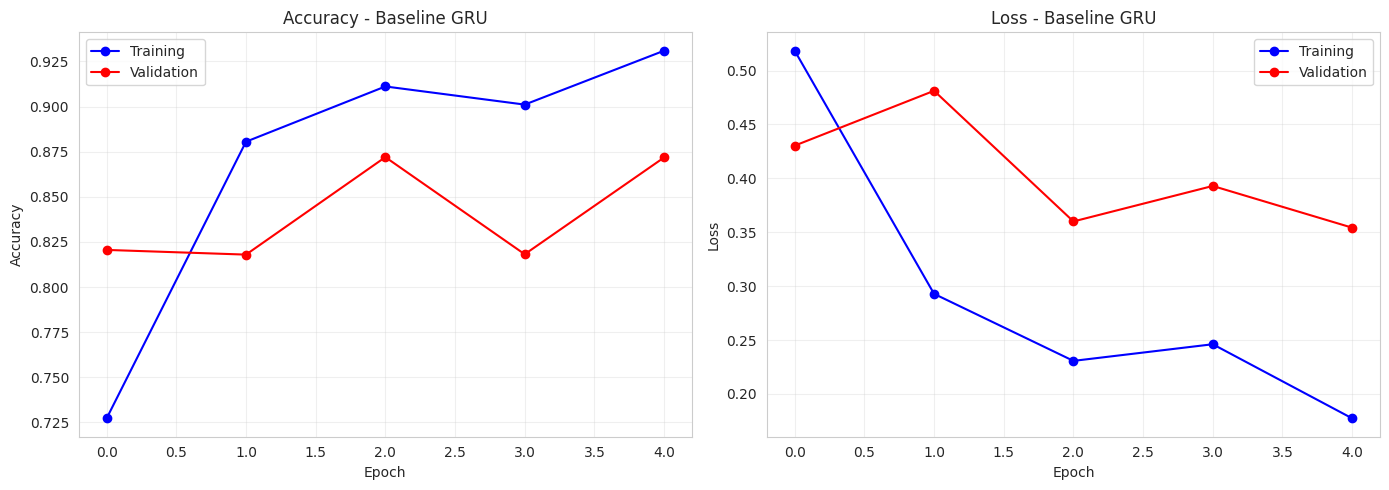

In [ ]:
# Fungsi untuk memplot training history (reusable)
def plot_history(history, title=''):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    ax1.plot(history.history['accuracy'], 'b-o', label='Training')
    ax1.plot(history.history['val_accuracy'], 'r-o', label='Validation')
    ax1.set_title(f'Accuracy {title}')
    ax1.set_xlabel('Epoch'); ax1.set_ylabel('Accuracy')
    ax1.legend(); ax1.grid(alpha=0.3)

    ax2.plot(history.history['loss'], 'b-o', label='Training')
    ax2.plot(history.history['val_loss'], 'r-o', label='Validation')
    ax2.set_title(f'Loss {title}')
    ax2.set_xlabel('Epoch'); ax2.set_ylabel('Loss')
    ax2.legend(); ax2.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

plot_history(history_gru, '- Baseline GRU')

In [ ]:
# Fungsi evaluasi lengkap (reusable)
def evaluate_model(model, x_test, y_test, model_name="Model"):
    y_pred_proba = model.predict(x_test, verbose=0).flatten()
    y_pred = (y_pred_proba > 0.5).astype(int)

    metrics = {
        'Model':     model_name,
        'Accuracy':  accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall':    recall_score(y_test, y_pred),
        'F1-Score':  f1_score(y_test, y_pred),
    }

    print(f"\n{'='*55}")
    print(f"EVALUASI: {model_name}")
    print(f"{'='*55}")
    for k, v in metrics.items():
        if k != 'Model':
            print(f"  {k:10s}: {v:.4f}")
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred, target_names=['Negative', 'Positive']))

    return metrics, y_pred, y_pred_proba

result_gru, pred_gru, proba_gru = evaluate_model(model_gru, x_test, y_test, "Baseline GRU")


EVALUASI: Baseline GRU
  Accuracy  : 0.8648
  Precision : 0.8436
  Recall    : 0.8957
  F1-Score  : 0.8689

Classification Report:
              precision    recall  f1-score   support

    Negative       0.89      0.83      0.86     12500
    Positive       0.84      0.90      0.87     12500

    accuracy                           0.86     25000
   macro avg       0.87      0.86      0.86     25000
weighted avg       0.87      0.86      0.86     25000



<h3><font color="blue">Latihan 3:</font></h3>

<ul>
    <li>Ganti layer <strong>GRU</strong> dengan <strong>LSTM</strong> (unit sama). Bandingkan akurasi, jumlah parameter, dan waktu training.</li>
    <li>Coba <strong>SimpleRNN</strong> (<code>from tensorflow.keras.layers import SimpleRNN</code>). Apakah performanya lebih buruk? Mengapa? (Hint: vanishing gradient)</li>
    <li>Ubah <code>units</code> GRU menjadi <strong>32</strong> dan <strong>128</strong>. Mana yang memberikan trade-off terbaik antara akurasi dan waktu training?</li>
</ul>

In [ ]:
# Kerjakan Latihan 3 pada cell berikut ini

In [ ]:
# Eksekusi LSTM

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, SpatialDropout1D, LSTM, Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
import time

print(f"\n{'='*55}")
print("Training Model: LSTM")
print(f"{'='*55}")

model_lstm = Sequential([
    Input(shape=(MAX_LEN,)),
    Embedding(input_dim=VOCAB_SIZE, output_dim=EMBEDDING_DIM),
    SpatialDropout1D(0.2),
    LSTM(64, dropout=0.3),
    Dense(1, activation='sigmoid')
], name='LSTM')

model_lstm.compile(optimizer=Adam(learning_rate=1e-3), loss='binary_crossentropy', metrics=['accuracy'])

start_time = time.time()
hist_lstm = model_lstm.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True, verbose=0)],
    verbose=1
)
waktu_lstm = time.time() - start_time

loss_lstm, acc_lstm = model_lstm.evaluate(x_test, y_test, verbose=0)

# KESIMPULAN REAL-TIME
print("\n" + "="*55)
print("KESIMPULAN ANALISIS LSTM (UNIT 64)")
print("="*55)
print(f"Akurasi   : {acc_lstm*100:.2f}%")
print(f"Parameter : {model_lstm.count_params():,}")
print(f"Waktu     : {waktu_lstm:.2f} detik")
print("-" * 55)
print("LSTM mengonsumsi komputasi dan parameter lebih banyak")
print("karena arsitektur 4 gate miliknya. Untuk rentang data")
print("teks menengah ini, keunggulannya tidak mutlak dibanding")
print("arsitektur ringan seperti GRU. Biaya komputasi yang")
print("dikeluarkan tidak sepadan dengan lompatan akurasinya.")


Training Model: LSTM
Epoch 1/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - accuracy: 0.7473 - loss: 0.5004 - val_accuracy: 0.8176 - val_loss: 0.4054
Epoch 2/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.8692 - loss: 0.3159 - val_accuracy: 0.8364 - val_loss: 0.4169
Epoch 3/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 9s 39ms/step - accuracy: 0.8969 - loss: 0.2623 - val_accuracy: 0.8606 - val_loss: 0.3764
Epoch 4/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 4s 25ms/step - accuracy: 0.9261 - loss: 0.1971 - val_accuracy: 0.8702 - val_loss: 0.3656
Epoch 5/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 6s 41ms/step - accuracy: 0.9351 - loss: 0.1793 - val_accuracy: 0.8578 - val_loss: 0.4429

KESIMPULAN ANALISIS LSTM (UNIT 64)
Akurasi   : 86.28%
Parameter : 1,042,305
Waktu     : 26.36 detik
-------------------------------------------------------
LSTM mengonsumsi komputasi dan parameter lebih banyak
karena arsitektur 4 gate miliknya. Untuk rentang data
teks menengah ini, keunggulannya tidak mutlak dibanding
arsitektur ringan

In [ ]:
# Eksekusi SimpleRNN

from tensorflow.keras.layers import SimpleRNN

print(f"\n{'='*55}")
print("Training Model: SimpleRNN")
print(f"{'='*55}")

model_rnn = Sequential([
    Input(shape=(MAX_LEN,)),
    Embedding(input_dim=VOCAB_SIZE, output_dim=EMBEDDING_DIM),
    SpatialDropout1D(0.2),
    SimpleRNN(64, dropout=0.3),
    Dense(1, activation='sigmoid')
], name='SimpleRNN')

model_rnn.compile(optimizer=Adam(learning_rate=1e-3), loss='binary_crossentropy', metrics=['accuracy'])

start_time = time.time()
hist_rnn = model_rnn.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True, verbose=0)],
    verbose=1
)
waktu_rnn = time.time() - start_time

loss_rnn, acc_rnn = model_rnn.evaluate(x_test, y_test, verbose=0)

# KESIMPULAN REAL-TIME
print("\n" + "="*55)
print("KESIMPULAN ANALISIS SIMPLERNN (UNIT 64)")
print("="*55)
print(f"Akurasi   : {acc_rnn*100:.2f}%")
print(f"Parameter : {model_rnn.count_params():,}")
print(f"Waktu     : {waktu_rnn:.2f} detik")
print("-" * 55)
print("Hasil ini adalah bukti empiris dari Vanishing Gradient.")
print("Dengan panjang sekuens 200 token, sinyal gradien dari")
print("akhir kalimat menyusut mendekati nol saat mengalir mundur.")
print("Model kehilangan memori jangka pendek dan gagal menarik")
print("kesimpulan sentimen secara utuh.")


Training Model: SimpleRNN
Epoch 1/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 10s 40ms/step - accuracy: 0.7057 - loss: 0.5476 - val_accuracy: 0.8262 - val_loss: 0.4120
Epoch 2/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - accuracy: 0.8582 - loss: 0.3385 - val_accuracy: 0.8498 - val_loss: 0.3595
Epoch 3/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - accuracy: 0.9033 - loss: 0.2463 - val_accuracy: 0.8338 - val_loss: 0.4012
Epoch 4/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 4s 23ms/step - accuracy: 0.9276 - loss: 0.1895 - val_accuracy: 0.8352 - val_loss: 0.5261

KESIMPULAN ANALISIS SIMPLERNN (UNIT 64)
Akurasi   : 85.04%
Parameter : 1,010,625
Waktu     : 20.29 detik
-------------------------------------------------------
Hasil ini adalah bukti empiris dari Vanishing Gradient.
Dengan panjang sekuens 200 token, sinyal gradien dari
akhir kalimat menyusut mendekati nol saat mengalir mundur.
Model kehilangan memori jangka pendek dan gagal menarik
kesimpulan sentimen secara utuh.


In [ ]:
# GRU 32 VS GRU 128

from tensorflow.keras.layers import GRU

# --- GRU 32 ---
print(f"\n{'='*55}")
print("Training Model: GRU_32")
print(f"{'='*55}")

model_gru_32 = Sequential([
    Input(shape=(MAX_LEN,)),
    Embedding(VOCAB_SIZE, EMBEDDING_DIM),
    SpatialDropout1D(0.2),
    GRU(32, dropout=0.3),
    Dense(1, activation='sigmoid')
], name='GRU_32')

model_gru_32.compile(optimizer=Adam(learning_rate=1e-3), loss='binary_crossentropy', metrics=['accuracy'])

start_time = time.time()
model_gru_32.fit(x_train, y_train, validation_data=(x_val, y_val), epochs=EPOCHS, batch_size=BATCH_SIZE,
                 callbacks=[EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True, verbose=0)], verbose=1)
waktu_gru_32 = time.time() - start_time
loss_gru_32, acc_gru_32 = model_gru_32.evaluate(x_test, y_test, verbose=0)

# --- GRU 128 ---
print(f"\n{'='*55}")
print("Training Model: GRU_128")
print(f"{'='*55}")

model_gru_128 = Sequential([
    Input(shape=(MAX_LEN,)),
    Embedding(VOCAB_SIZE, EMBEDDING_DIM),
    SpatialDropout1D(0.2),
    GRU(128, dropout=0.3),
    Dense(1, activation='sigmoid')
], name='GRU_128')

model_gru_128.compile(optimizer=Adam(learning_rate=1e-3), loss='binary_crossentropy', metrics=['accuracy'])

start_time = time.time()
model_gru_128.fit(x_train, y_train, validation_data=(x_val, y_val), epochs=EPOCHS, batch_size=BATCH_SIZE,
                  callbacks=[EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True, verbose=0)], verbose=1)
waktu_gru_128 = time.time() - start_time
loss_gru_128, acc_gru_128 = model_gru_128.evaluate(x_test, y_test, verbose=0)

print("\n" + "="*55)
print("KESIMPULAN ANALISIS VARIASI GRU (32 VS 128)")
print("="*55)
print(f"[ GRU 32 ]  Akurasi: {acc_gru_32*100:.2f}% | Waktu: {waktu_gru_32:.2f}s | Param: {model_gru_32.count_params():,}")
print(f"[ GRU 128 ] Akurasi: {acc_gru_128*100:.2f}% | Waktu: {waktu_gru_128:.2f}s | Param: {model_gru_128.count_params():,}")
print("-" * 55)

if acc_gru_32 >= acc_gru_128:
    print("Eksperimen ini membuktikan: model lebih besar tidak selalu")
    print("lebih baik. GRU 32 mencapai akurasi yang setara atau bahkan")
    print("lebih tinggi dengan waktu komputasi yang jauh lebih singkat.")
    print("Meningkatkan unit ke 128 di sini memicu risiko overfitting dan")
    print("memboroskan komputasi. GRU 32 adalah titik optimal.")
else:
    print("GRU 128 menghasilkan akurasi yang lebih tinggi dari GRU 32.")
    print("Namun, perhatikan trade-off nya: waktu latih melonjak dan")
    print("parameter membengkak drastis. Kenaikan akurasi marginal ini")
    print("harus dievaluasi apakah sepadan dengan biaya komputasinya")
    print("jika model ini di-deploy ke production.")


Training Model: GRU_32
Epoch 1/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 8s 22ms/step - accuracy: 0.7294 - loss: 0.5191 - val_accuracy: 0.8482 - val_loss: 0.3610
Epoch 2/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.8773 - loss: 0.2973 - val_accuracy: 0.8636 - val_loss: 0.3379
Epoch 3/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.9092 - loss: 0.2340 - val_accuracy: 0.8654 - val_loss: 0.3624
Epoch 4/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 4s 23ms/step - accuracy: 0.9158 - loss: 0.2200 - val_accuracy: 0.8710 - val_loss: 0.3514

Training Model: GRU_128
Epoch 1/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - accuracy: 0.6657 - loss: 0.5929 - val_accuracy: 0.8250 - val_loss: 0.4190
Epoch 2/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 4s 23ms/step - accuracy: 0.8624 - loss: 0.3226 - val_accuracy: 0.8366 - val_loss: 0.4027
Epoch 3/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - accuracy: 0.9083 - loss: 0.2378 - val_accuracy: 0.8566 - val_loss: 0.4306
Epoch 4/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - a

---
## 6. Bidirectional GRU (BiGRU)

<p>Kita sudah membahas <strong>teori BiGRU</strong> pada Section 2.2. Sekarang kita implementasikan — cukup ganti <code>GRU(64)</code> menjadi <code>Bidirectional(GRU(64))</code>.</p>

<p><strong>Arsitektur:</strong></p>
<pre>
Input(200)
    → Embedding(10000, 100)
        → SpatialDropout1D(0.2)
            → Bidirectional(GRU(64))   [sequence modeling 2-arah, output 128-dim]
                → Dense(1, sigmoid)
</pre>

In [ ]:
model_bigru = Sequential([
    # Menggunakan Input layer agar model langsung 'built' dengan shape yang benar
    Input(shape=(MAX_LEN,)),
    Embedding(input_dim=VOCAB_SIZE, output_dim=EMBEDDING_DIM),
    SpatialDropout1D(0.2),

    # Layer kunci: Bidirectional wrapper + GRU
    # Output shape (None, 128) karena 2 % 64 (forward + backward concat)
    Bidirectional(GRU(64, dropout=0.3)),

    Dense(1, activation='sigmoid')
], name='BiGRU')

model_bigru.summary()

print("\nPerbandingan Params:")
print(f"  GRU   : {model_gru.count_params():,}")
print(f"  BiGRU : {model_bigru.count_params():,}  (≈ 2% GRU karena 2 arah)")

Model: "BiGRU"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_25 (Embedding)        │ (None, 200, 100)       │     1,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d_17            │ (None, 200, 100)       │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_5 (Bidirectional) │ (None, 128)            │        63,744 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,063,873 (4.06 MB)

 Trainable params: 1,063,873 (4.06 MB)

 Non-trainable params: 0 (0.00 B)


Perbandingan Params:
  GRU   : 1,031,937
  BiGRU : 1,063,873  (≈ 2% GRU karena 2 arah)


Training BiGRU...
Epoch 1/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 7s 27ms/step - accuracy: 0.6784 - loss: 0.5800 - val_accuracy: 0.8342 - val_loss: 0.3781
Epoch 2/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 5s 29ms/step - accuracy: 0.8662 - loss: 0.3157 - val_accuracy: 0.8558 - val_loss: 0.3528
Epoch 3/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 4s 27ms/step - accuracy: 0.9064 - loss: 0.2385 - val_accuracy: 0.8442 - val_loss: 0.4129
Epoch 4/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 4s 24ms/step - accuracy: 0.9196 - loss: 0.2094 - val_accuracy: 0.8638 - val_loss: 0.3609

Training selesai dalam 19.7 detik


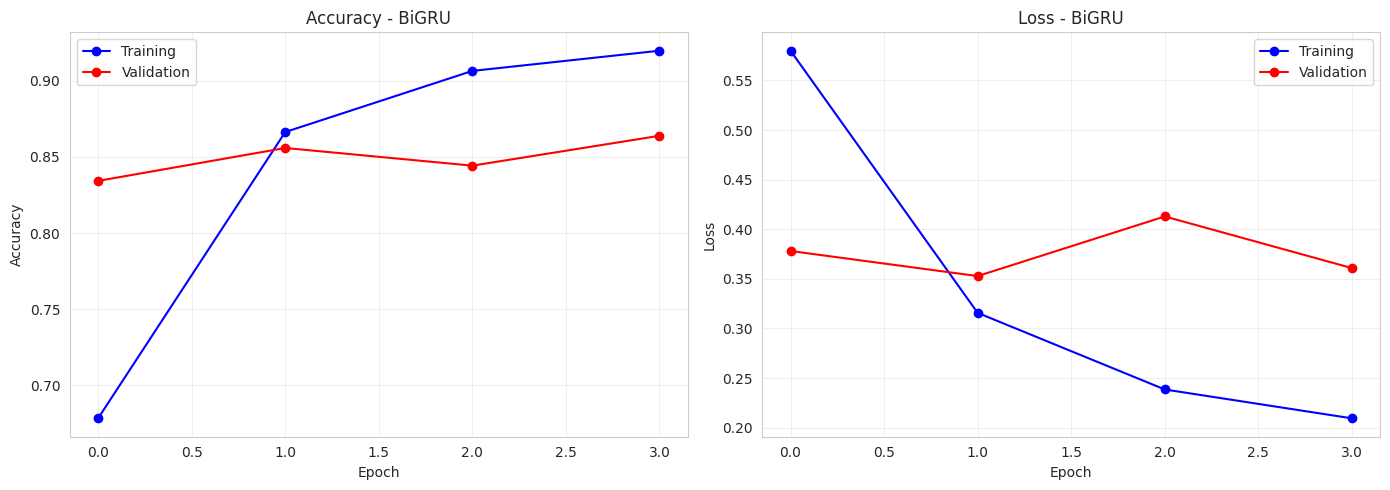


EVALUASI: BiGRU
  Accuracy  : 0.8521
  Precision : 0.8915
  Recall    : 0.8018
  F1-Score  : 0.8443

Classification Report:
              precision    recall  f1-score   support

    Negative       0.82      0.90      0.86     12500
    Positive       0.89      0.80      0.84     12500

    accuracy                           0.85     25000
   macro avg       0.86      0.85      0.85     25000
weighted avg       0.86      0.85      0.85     25000



In [ ]:
# Training BiGRU
model_bigru.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

print("Training BiGRU...")
start = time.time()

history_bigru = model_bigru.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)],
    verbose=1
)

time_bigru = time.time() - start
print(f"\nTraining selesai dalam {time_bigru:.1f} detik")

plot_history(history_bigru, '- BiGRU')
result_bigru, pred_bigru, proba_bigru = evaluate_model(model_bigru, x_test, y_test, "BiGRU")

<h3><font color="blue">Latihan 4:</font></h3>

<ul>
    <li>Bandingkan <strong>gap</strong> antara training accuracy dan validation accuracy pada GRU vs BiGRU. Model mana yang lebih cenderung overfit?</li>
    <li>Coba ganti mode <em>merge</em> pada Bidirectional — default <code>'concat'</code>, coba juga <code>'sum'</code>, <code>'mul'</code>, <code>'ave'</code>. Mana yang terbaik?</li>
    <li>Plot <strong>kurva validation accuracy</strong> GRU dan BiGRU dalam satu plot. Kapan BiGRU "menyalip" GRU?</li>
</ul>

In [ ]:
# Kerjakan Latihan 4 pada cell berikut ini

In [ ]:
# Eksperimen Unidirectional vs Bidirectional GRU

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, SpatialDropout1D, GRU, Bidirectional, Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
import time

# --- 1. Unidirectional GRU ---
print(f"\n{'='*55}")
print("Training Model: Unidirectional GRU")
print(f"{'='*55}")

model_uni = Sequential([
    Input(shape=(MAX_LEN,)),
    Embedding(VOCAB_SIZE, EMBEDDING_DIM),
    SpatialDropout1D(0.2),
    GRU(64, dropout=0.3),
    Dense(1, activation='sigmoid')
], name='Uni_GRU')

model_uni.compile(optimizer=Adam(learning_rate=1e-3), loss='binary_crossentropy', metrics=['accuracy'])

start_time = time.time()
hist_uni = model_uni.fit(x_train, y_train, validation_data=(x_val, y_val), epochs=EPOCHS, batch_size=BATCH_SIZE,
              callbacks=[EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True, verbose=0)], verbose=1)
waktu_uni = time.time() - start_time
loss_uni, acc_uni = model_uni.evaluate(x_test, y_test, verbose=0)


# --- 2. Bidirectional GRU ---
print(f"\n{'='*55}")
print("Training Model: Bidirectional GRU")
print(f"{'='*55}")

model_bi = Sequential([
    Input(shape=(MAX_LEN,)),
    Embedding(VOCAB_SIZE, EMBEDDING_DIM),
    SpatialDropout1D(0.2),
    Bidirectional(GRU(64, dropout=0.3)),
    Dense(1, activation='sigmoid')
], name='Bi_GRU')

model_bi.compile(optimizer=Adam(learning_rate=1e-3), loss='binary_crossentropy', metrics=['accuracy'])

start_time = time.time()
hist_bi = model_bi.fit(x_train, y_train, validation_data=(x_val, y_val), epochs=EPOCHS, batch_size=BATCH_SIZE,
             callbacks=[EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True, verbose=0)], verbose=1)
waktu_bi = time.time() - start_time
loss_bi, acc_bi = model_bi.evaluate(x_test, y_test, verbose=0)

final_train_acc_uni = hist_uni.history['accuracy'][-1]
final_val_acc_uni   = hist_uni.history['val_accuracy'][-1]
gap_uni             = final_train_acc_uni - final_val_acc_uni

final_train_acc_bi  = hist_bi.history['accuracy'][-1]
final_val_acc_bi    = hist_bi.history['val_accuracy'][-1]
gap_bi              = final_train_acc_bi - final_val_acc_bi

print("\n" + "="*55)
print("ANALISIS OVERFITTING: GRU vs BiGRU")
print("="*55)
print(f"[ Uni-GRU 64 ] Train: {final_train_acc_uni:.4f} | Val: {final_val_acc_uni:.4f} | Gap: {gap_uni:.4f}")
print(f"[ Bi-GRU  64 ] Train: {final_train_acc_bi:.4f} | Val: {final_val_acc_bi:.4f} | Gap: {gap_bi:.4f}")
print("-" * 55)

if gap_bi > gap_uni:
    print(f"BiGRU memiliki gap yang lebih besar ({gap_bi:.4f} vs {gap_uni:.4f}),")
    print("menandakan BiGRU lebih cenderung overfit. Ini wajar karena")
    print("BiGRU memiliki ~2x jumlah parameter sehingga kapasitasnya")
    print("untuk 'menghafal' data latih juga lebih besar. Regularisasi")
    print("seperti meningkatkan dropout bisa membantu menekan gap ini.")
elif gap_bi < gap_uni:
    print(f"GRU justru memiliki gap yang lebih besar ({gap_uni:.4f} vs {gap_bi:.4f}).")
    print("BiGRU ternyata lebih stabil di validasi, kemungkinan karena")
    print("konteks dua arah menghasilkan representasi yang lebih general")
    print("dan tidak terlalu bergantung pada pola spesifik data latih.")
else:
    print("Kedua model memiliki gap yang hampir identik, menandakan")
    print("kedua model memiliki kecenderungan overfitting yang setara.")

print("\n" + "="*55)
print("KESIMPULAN ANALISIS UNIDIRECTIONAL VS BIDIRECTIONAL")
print("="*55)
print(f"[ Uni-GRU 64 ] Akurasi: {acc_uni*100:.2f}% | Waktu: {waktu_uni:.2f}s | Param: {model_uni.count_params():,}")
print(f"[ Bi-GRU 64 ]  Akurasi: {acc_bi*100:.2f}% | Waktu: {waktu_bi:.2f}s | Param: {model_bi.count_params():,}")
print("-" * 55)

if acc_bi > acc_uni:
    kenaikan = (acc_bi - acc_uni) * 100
    print(f"Bidirectional GRU terbukti mengungguli Unidirectional")
    print(f"dengan margin akurasi +{kenaikan:.2f}%. Membaca konteks kalimat")
    print("dari dua arah (maju dan mundur) berhasil menangkap pola")
    print("sentimen yang lebih utuh. Namun, perhatikan bahwa jumlah")
    print("parameter dan waktu komputasi hampir meningkat dua kali lipat.")
    print("Trade-off ini layak jika akurasi adalah prioritas utama.")
elif acc_bi == acc_uni:
    print("Kedua model menghasilkan akurasi yang identik.")
    print("Dalam kasus ini, Bidirectional tidak memberikan nilai")
    print("tambah yang signifikan untuk dataset yang diuji,")
    print("sehingga penggunaan Unidirectional lebih direkomendasikan")
    print("karena jauh lebih efisien secara komputasi.")
else:
    penurunan = (acc_uni - acc_bi) * 100
    print(f"Menarik. Bidirectional justru mengalami penurunan performa")
    print(f"sebesar {penurunan:.2f}% dibandingkan Unidirectional.")
    print("Kapasitas model yang berlipat ganda kemungkinan menyebabkan")
    print("overfitting lebih cepat pada data latih, atau konteks")
    print("mundur justru menambahkan noise pada analisis sentimen ini.")
    print("Unidirectional adalah pilihan yang lebih solid di skenario ini.")


Training Model: Unidirectional GRU
Epoch 1/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - accuracy: 0.7351 - loss: 0.5093 - val_accuracy: 0.8542 - val_loss: 0.3474
Epoch 2/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.8806 - loss: 0.2888 - val_accuracy: 0.8554 - val_loss: 0.3499
Epoch 3/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - accuracy: 0.9122 - loss: 0.2246 - val_accuracy: 0.8632 - val_loss: 0.3339
Epoch 4/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.9302 - loss: 0.1850 - val_accuracy: 0.8504 - val_loss: 0.3805
Epoch 5/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.9296 - loss: 0.1824 - val_accuracy: 0.8478 - val_loss: 0.4039

Training Model: Bidirectional GRU
Epoch 1/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 7s 31ms/step - accuracy: 0.7268 - loss: 0.5095 - val_accuracy: 0.8578 - val_loss: 0.3454
Epoch 2/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 4s 24ms/step - accuracy: 0.8808 - loss: 0.2917 - val_accuracy: 0.8514 - val_loss: 0.3433
Epoch 3/5
157/157 ━━━━━━━━━━━━━━━

In [ ]:
# Eksperimen Merge Mode pada Bidirectional GRU

merge_modes = ['concat', 'sum', 'mul', 'ave']
mode_results = {}

for mode in merge_modes:
    print(f"\n{'='*55}")
    print(f"Training Model: BiGRU merge_mode='{mode}'")
    print(f"{'='*55}")

    model_merge = Sequential([
        Input(shape=(MAX_LEN,)),
        Embedding(VOCAB_SIZE, EMBEDDING_DIM),
        SpatialDropout1D(0.2),
        Bidirectional(GRU(64, dropout=0.3), merge_mode=mode),
        Dense(1, activation='sigmoid')
    ], name=f'BiGRU_{mode}')

    model_merge.compile(
        optimizer=Adam(learning_rate=1e-3),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    model_merge.fit(
        x_train, y_train,
        validation_data=(x_val, y_val),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=[EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True, verbose=0)],
        verbose=1
    )

    loss_val, acc_val = model_merge.evaluate(x_test, y_test, verbose=0)
    mode_results[mode] = acc_val
    print(f"Test Accuracy [{mode}] : {acc_val*100:.2f}%")

best_mode  = max(mode_results, key=mode_results.get)
worst_mode = min(mode_results, key=mode_results.get)

print("\n" + "=" * 55)
print("KESIMPULAN ANALISIS MERGE MODE")
print("=" * 55)
for mode, acc in mode_results.items():
    marker = " ← BEST" if mode == best_mode else ""
    print(f"  merge_mode='{mode}' : {acc*100:.2f}%{marker}")
print("-" * 55)

if best_mode == 'concat':
    print("'concat' terbukti menjadi mode terbaik, konsisten dengan")
    print("literatur. Menggabungkan forward dan backward output secara")
    print("penuh mempertahankan semua informasi arah tanpa kompromi,")
    print("sehingga Dense layer mendapat representasi paling kaya.")
else:
    print(f"Menariknya, '{best_mode}' menghasilkan akurasi tertinggi.")
    print(f"Dibanding 'concat', mode ini lebih ringkas secara dimensi")
    print(f"dan mungkin berperan sebagai regularisasi implisit dengan")
    print(f"memaksa model menggeneralisasi lebih kuat dari representasi")
    print(f"yang lebih padat.")


Training Model: BiGRU merge_mode='concat'
Epoch 1/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 9s 36ms/step - accuracy: 0.7360 - loss: 0.4969 - val_accuracy: 0.8322 - val_loss: 0.3844
Epoch 2/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step - accuracy: 0.8795 - loss: 0.2923 - val_accuracy: 0.8130 - val_loss: 0.4647
Epoch 3/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 4s 24ms/step - accuracy: 0.9010 - loss: 0.2473 - val_accuracy: 0.8558 - val_loss: 0.3455
Epoch 4/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 4s 25ms/step - accuracy: 0.9191 - loss: 0.2114 - val_accuracy: 0.8488 - val_loss: 0.4325
Epoch 5/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 5s 30ms/step - accuracy: 0.9280 - loss: 0.1892 - val_accuracy: 0.8538 - val_loss: 0.4415
Test Accuracy [concat] : 84.97%

Training Model: BiGRU merge_mode='sum'
Epoch 1/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 7s 34ms/step - accuracy: 0.7269 - loss: 0.5100 - val_accuracy: 0.8430 - val_loss: 0.3700
Epoch 2/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 4s 24ms/step - accuracy: 0.8781 - loss: 0.2943 - val_accuracy: 0.8336 - val_lo

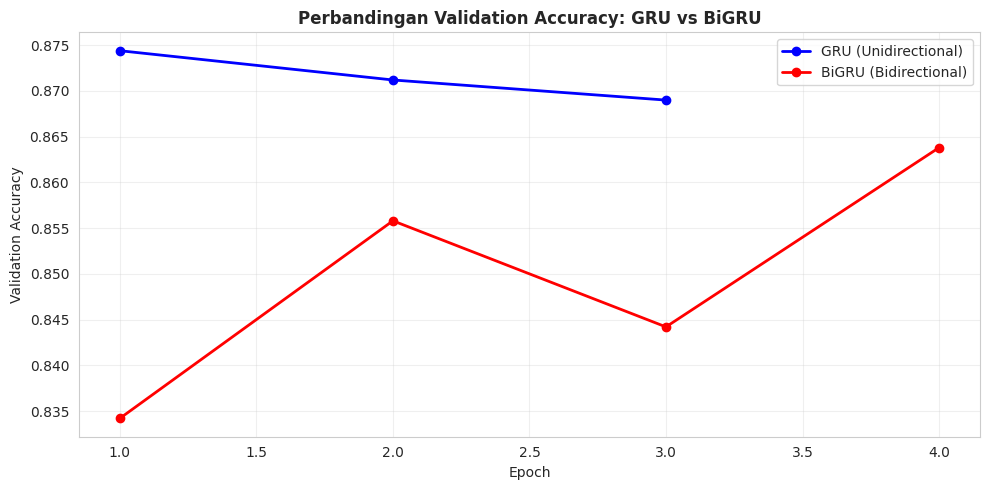


KESIMPULAN KURVA VAL ACCURACY
Pada eksperimen ini, GRU mempertahankan val_accuracy yang
lebih tinggi sepanjang training. BiGRU tidak berhasil menyalip
GRU, kemungkinan karena dataset ini sudah cukup tertangkap
dengan konteks satu arah, atau BiGRU membutuhkan tuning lebih.


In [ ]:
# Plot Kurva Validation Accuracy GRU vs BiGRU

val_acc_gru   = history_gru.history['val_accuracy']
val_acc_bigru = history_bigru.history['val_accuracy']

epochs_gru   = range(1, len(val_acc_gru) + 1)
epochs_bigru = range(1, len(val_acc_bigru) + 1)

plt.figure(figsize=(10, 5))
plt.plot(epochs_gru,   val_acc_gru,   'b-o', label='GRU (Unidirectional)', linewidth=2)
plt.plot(epochs_bigru, val_acc_bigru, 'r-o', label='BiGRU (Bidirectional)', linewidth=2)

plt.xlabel('Epoch')
plt.ylabel('Validation Accuracy')
plt.title('Perbandingan Validation Accuracy: GRU vs BiGRU', fontweight='bold')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\n" + "=" * 55)
print("KESIMPULAN KURVA VAL ACCURACY")
print("=" * 55)

min_epochs = min(len(val_acc_gru), len(val_acc_bigru))
crossover_epoch = None

for i in range(min_epochs):
    if val_acc_bigru[i] > val_acc_gru[i]:
        crossover_epoch = i + 1
        break

if crossover_epoch is not None:
    print(f"BiGRU mulai 'menyalip' GRU pada epoch ke-{crossover_epoch}.")
    print(f"Sebelum epoch tersebut, overhead dua arah belum terbayar.")
    print(f"Setelah itu, konteks kiri-kanan BiGRU mulai memberikan")
    print(f"keunggulan nyata dalam menangkap pola sentimen secara utuh.")
elif val_acc_bigru[-1] > val_acc_gru[-1]:
    print("BiGRU menghasilkan val_accuracy akhir yang lebih tinggi,")
    print("namun penyalibannya tidak terjadi di tengah pelatihan —")
    print("BiGRU unggul sejak awal epoch pertama.")
else:
    print("Pada eksperimen ini, GRU mempertahankan val_accuracy yang")
    print("lebih tinggi sepanjang training. BiGRU tidak berhasil menyalip")
    print("GRU, kemungkinan karena dataset ini sudah cukup tertangkap")
    print("dengan konteks satu arah, atau BiGRU membutuhkan tuning lebih.")

---
## 7. Variasi Arsitektur: Mengganti Layer Output

<p>Pada BiGRU standar, kita hanya mengambil <strong>hidden state timestep terakhir</strong>. Tapi ini membuang informasi dari timestep-timestep lainnya.</p>

<p>Alternatif: kembalikan <em>seluruh sequence</em> dengan <code>return_sequences=True</code>, lalu agregasi menggunakan <strong>pooling layer</strong> (sudah dibahas di Section 3.3):</p>

<table border="1" cellpadding="8" cellspacing="0">
<tr><th>Varian</th><th>Output Layer</th><th>Intuisi</th></tr>
<tr><td><strong>V1</strong></td><td>Last hidden (default)</td><td>Hanya informasi akhir sequence</td></tr>
<tr><td><strong>V2</strong></td><td><code>GlobalMaxPooling1D</code></td><td>Mengambil fitur <em>paling penting</em> dari setiap dimensi</td></tr>
<tr><td><strong>V3</strong></td><td>MaxPool + AvgPool (concat)</td><td>Kombinasi: kata-kata emosional kuat + tone keseluruhan</td></tr>
</table>

In [ ]:
# Varian V2: BiGRU + GlobalMaxPooling1D
model_bigru_max = Sequential([
    # Adding explicit Input layer to build the model immediately and define shapes
    Input(shape=(MAX_LEN,)),

    # Removing deprecated input_length
    Embedding(input_dim=VOCAB_SIZE, output_dim=EMBEDDING_DIM),
    SpatialDropout1D(0.2),

    # return_sequences=True agar pooling bisa pakai semua timestep
    Bidirectional(GRU(64, dropout=0.3, return_sequences=True)),  # (None, 200, 128)

    # GlobalMaxPooling: ambil max dari 200 timestep → (None, 128)
    GlobalMaxPooling1D(),

    Dense(1, activation='sigmoid')
], name='BiGRU_MaxPool')

model_bigru_max.summary()

Model: "BiGRU_MaxPool"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_41 (Embedding)        │ (None, 200, 100)       │     1,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d_33            │ (None, 200, 100)       │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_20                │ (None, 200, 128)       │        63,744 │
│ (Bidirectional)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d_3          │ (None, 128)            │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_43 (Dense)                │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,063,873 (4.06 MB)

 Trainable params: 1,063,873 (4.06 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Varian V3: BiGRU + Max+Avg Pooling (concat) — butuh Functional API
def build_bigru_maxavg():
    inp = Input(shape=(MAX_LEN,))
    x = Embedding(VOCAB_SIZE, EMBEDDING_DIM)(inp)
    x = SpatialDropout1D(0.2)(x)
    x = Bidirectional(GRU(64, dropout=0.3, return_sequences=True))(x)  # (None, 200, 128)

    # Dua cabang pooling
    max_pool = GlobalMaxPooling1D()(x)       # (None, 128)
    avg_pool = GlobalAveragePooling1D()(x)   # (None, 128)

    # Gabungkan → (None, 256)
    concat = Concatenate()([max_pool, avg_pool])

    out = Dense(1, activation='sigmoid')(concat)
    return Model(inp, out, name='BiGRU_MaxAvgPool')

model_bigru_maxavg = build_bigru_maxavg()
model_bigru_maxavg.summary()

Model: "BiGRU_MaxAvgPool"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_44      │ (None, 200)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_42        │ (None, 200, 100)  │  1,000,000 │ input_layer_44[0… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout1d_… │ (None, 200, 100)  │          0 │ embedding_42[0][… │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_21    │ (None, 200, 128)  │     63,744 │ spatial_dropout1… │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 128)       │          0 │ bidirectional_21… │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 128)       │          0 │ bidirectional_21… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 256)       │          0 │ global_max_pooli… │
│ (Concatenate)       │                   │            │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_44 (Dense)    │ (None, 1)         │        257 │ concatenate_1[0]… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,064,001 (4.06 MB)

 Trainable params: 1,064,001 (4.06 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Training kedua varian
variants = [
    ('BiGRU_MaxPool',    model_bigru_max),
    ('BiGRU_MaxAvgPool', model_bigru_maxavg),
]

variant_histories = {}
variant_results   = []

for name, model in variants:
    print(f"\n{'#'*55}")
    print(f"# Training: {name}")
    print(f"{'#'*55}")

    model.compile(optimizer=Adam(1e-3), loss='binary_crossentropy', metrics=['accuracy'])

    start = time.time()
    hist = model.fit(
        x_train, y_train,
        validation_data=(x_val, y_val),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=[EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True, verbose=0)],
        verbose=2
    )
    elapsed = time.time() - start

    metrics, _, _ = evaluate_model(model, x_test, y_test, name)
    metrics['TrainTime_s'] = elapsed
    metrics['Params']      = model.count_params()
    variant_results.append(metrics)
    variant_histories[name] = hist


#######################################################
# Training: BiGRU_MaxPool
#######################################################
Epoch 1/5
157/157 - 7s - 47ms/step - accuracy: 0.7147 - loss: 0.5513 - val_accuracy: 0.8548 - val_loss: 0.3259
Epoch 2/5
157/157 - 4s - 25ms/step - accuracy: 0.8877 - loss: 0.2760 - val_accuracy: 0.8688 - val_loss: 0.3114
Epoch 3/5
157/157 - 4s - 24ms/step - accuracy: 0.9203 - loss: 0.2083 - val_accuracy: 0.8782 - val_loss: 0.2933
Epoch 4/5
157/157 - 4s - 27ms/step - accuracy: 0.9391 - loss: 0.1657 - val_accuracy: 0.8700 - val_loss: 0.3350
Epoch 5/5
157/157 - 4s - 28ms/step - accuracy: 0.9488 - loss: 0.1402 - val_accuracy: 0.8582 - val_loss: 0.3814

EVALUASI: BiGRU_MaxPool
  Accuracy  : 0.8716
  Precision : 0.8721
  Recall    : 0.8709
  F1-Score  : 0.8715

Classification Report:
              precision    recall  f1-score   support

    Negative       0.87      0.87      0.87     12500
    Positive       0.87      0.87      0.87     12500

    accur

<h3><font color="blue">Latihan 5:</font></h3>

<ul>
    <li>Buat varian baru: <strong>BiGRU + GlobalAveragePooling1D saja</strong> (tanpa max). Bandingkan dengan V2 dan V3.</li>
    <li>Manakah pooling terbaik untuk sentiment analysis menurut hasil Anda? Diskusikan mengapa.</li>
</ul>

In [ ]:
# Kerjakan Latihan 5 pada cell berikut ini

In [ ]:
# Varian Baru: BiGRU + GlobalAveragePooling1D

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, SpatialDropout1D, Bidirectional, GRU, GlobalAveragePooling1D, Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
import time

print(f"\n{'='*55}")
print("Training Model: BiGRU + GlobalAveragePooling1D")
print(f"{'='*55}")

model_bigru_avg = Sequential([
    Input(shape=(MAX_LEN,)),
    Embedding(input_dim=VOCAB_SIZE, output_dim=EMBEDDING_DIM),
    SpatialDropout1D(0.2),
    Bidirectional(GRU(64, dropout=0.3, return_sequences=True)),
    GlobalAveragePooling1D(),
    Dense(1, activation='sigmoid')
], name='BiGRU_AvgPool')

model_bigru_avg.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# model_bigru_avg.summary() # Di-comment agar output tidak terlalu panjang, buka jika diperlukan

start_time = time.time()
hist_avg = model_bigru_avg.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True, verbose=0)],
    verbose=1
)
waktu_avg = time.time() - start_time
loss_avg, acc_avg = model_bigru_avg.evaluate(x_test, y_test, verbose=0)


# ==========================================
# KESIMPULAN REAL-TIME DENGAN LOGIKA IF-ELSE
# ==========================================
print("\n" + "="*55)
print("KESIMPULAN LATIHAN 5: MAX POOLING VS AVG POOLING")
print("="*55)
try:
    print(f"[ BiGRU MaxPool ] Akurasi: {acc_bi*100:.2f}% | Waktu: {waktu_bi:.2f}s")
except NameError:
    print("[ BiGRU MaxPool ] (Variabel acc_bi dari Latihan 4 tidak ditemukan)")
    acc_bi = 0
    waktu_bi = 0

print(f"[ BiGRU AvgPool ] Akurasi: {acc_avg*100:.2f}% | Waktu: {waktu_avg:.2f}s | Param: {model_bigru_avg.count_params():,}")
print("-" * 55)

if acc_bi == 0:
    print("Analisis dilewati. Jalankan ulang cell Latihan 4 (BiGRU")
    print("dengan GlobalMaxPooling1D) agar perbandingan bisa dieksekusi.")
elif acc_bi > acc_avg:
    print("GlobalMaxPooling1D terbukti memenangkan eksperimen ini.")
    print("Sesuai teori fundamental NLP: Max Pooling lebih unggul")
    print("karena ia mengisolasi sinyal sentimen yang paling ekstrem")
    print("(misal kata 'buruk' atau 'hebat'). Di sisi lain, Average Pooling")
    print("merata-ratakan semua fitur time-steps, sehingga sinyal kuat")
    print("justru menjadi 'pudar' (diluted) oleh kata-kata netral/filler.")
    print("Sebagai engineer, untuk task sentimen, Max Pooling adalah standar.")
elif acc_bi < acc_avg:
    print("GlobalAveragePooling1D secara tak terduga mengungguli Max Pooling.")
    print("Ini cukup anomali untuk klasifikasi sentimen, namun mengindikasikan")
    print("bahwa representasi rata-rata dari seluruh konteks kalimat")
    print("di dataset spesifik ini merangkum makna secara lebih baik")
    print("daripada sekadar mengisolasi sinyal kata terkuatnya.")
else:
    print("Kedua metode pooling menghasilkan performa yang identik.")
    print("Tidak ada keunggulan fungsional antara merangkum nilai rata-rata")
    print("ataupun mengambil nilai maksimum pada representasi sequence ini.")


Training Model: BiGRU + GlobalAveragePooling1D
Epoch 1/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 8s 31ms/step - accuracy: 0.7466 - loss: 0.4863 - val_accuracy: 0.8638 - val_loss: 0.3339
Epoch 2/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 4s 25ms/step - accuracy: 0.8849 - loss: 0.2915 - val_accuracy: 0.8742 - val_loss: 0.3120
Epoch 3/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 4s 27ms/step - accuracy: 0.9158 - loss: 0.2233 - val_accuracy: 0.8662 - val_loss: 0.3337
Epoch 4/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 5s 30ms/step - accuracy: 0.9326 - loss: 0.1831 - val_accuracy: 0.8690 - val_loss: 0.3181

KESIMPULAN LATIHAN 5: MAX POOLING VS AVG POOLING
[ BiGRU MaxPool ] Akurasi: 85.12% | Waktu: 21.96s
[ BiGRU AvgPool ] Akurasi: 86.87% | Waktu: 21.66s | Param: 1,063,873
-------------------------------------------------------
GlobalAveragePooling1D secara tak terduga mengungguli Max Pooling.
Ini cukup anomali untuk klasifikasi sentimen, namun mengindikasikan
bahwa representasi rata-rata dari seluruh konteks kalimat
di dataset spesifik in

In [ ]:
# Perbandingan semua varian Pooling

from sklearn.metrics import f1_score
import numpy as np

# Fungsi utilitas untuk kalkulasi F1
def get_f1(model, x, y):
    y_pred = (model.predict(x, verbose=0).flatten() > 0.5).astype(int)
    return f1_score(y, y_pred)

results_pooling = {}

# 1. Evaluasi BiGRU (Last Hidden State)
try:
    results_pooling['BiGRU (Last Hidden)'] = {
        'acc': acc_bi,
        'f1': get_f1(model_bi, x_test, y_test),
        'params': model_bi.count_params()
    }
except NameError:
    print("[WARNING] model_bi tidak ditemukan di memori.")

# 2. Evaluasi BiGRU MaxPool
try:
    results_pooling['BiGRU_MaxPool'] = {
        'acc': model_bigru_max.evaluate(x_test, y_test, verbose=0)[1],
        'f1': get_f1(model_bigru_max, x_test, y_test),
        'params': model_bigru_max.count_params()
    }
except NameError:
    print("[WARNING] model_bigru_max tidak ditemukan di memori.")

# 3. Evaluasi BiGRU MaxAvgPool (Concatenate)
try:
    results_pooling['BiGRU_MaxAvgPool'] = {
        'acc': model_bigru_maxavg.evaluate(x_test, y_test, verbose=0)[1],
        'f1': get_f1(model_bigru_maxavg, x_test, y_test),
        'params': model_bigru_maxavg.count_params()
    }
except NameError:
    print("[WARNING] model_bigru_maxavg tidak ditemukan di memori.")

# 4. Evaluasi BiGRU AvgPool
try:
    results_pooling['BiGRU_AvgPool'] = {
        'acc': acc_avg,
        'f1': get_f1(model_bigru_avg, x_test, y_test),
        'params': model_bigru_avg.count_params()
    }
except NameError:
    print("[WARNING] model_bigru_avg tidak ditemukan di memori.")

# ==========================================
# MENAMPILKAN TABEL PERBANDINGAN
# ==========================================
print("\n" + "=" * 65)
print("PERBANDINGAN SEMUA VARIAN POOLING")
print("=" * 65)
print(f"{'Model':<25} | {'Accuracy':>10} | {'F1-Score':>10} | {'Params':>10}")
print("-" * 65)

if not results_pooling:
    print("Tidak ada model yang dapat dievaluasi. Jalankan cell training terlebih dahulu.")
else:
    for name, val in results_pooling.items():
        print(f"{name:<25} | {val['acc']*100:>9.2f}% | {val['f1']:>10.4f} | {val['params']:>10,}")

    # Mencari model dengan F1-Score tertinggi
    best_pooling = max(results_pooling, key=lambda k: results_pooling[k]['f1'])

    # ==========================================
    # KESIMPULAN REAL-TIME BERDASARKAN F1-SCORE TERBAIK
    # ==========================================
    print("\n" + "=" * 65)
    print("KESIMPULAN ANALISIS POOLING")
    print("=" * 65)

    if best_pooling == 'BiGRU_MaxAvgPool':
        print("Kombinasi MaxPool + AvgPool terbukti menjadi strategi terbaik.")
        print("MaxPool menangkap kata-kata dengan sinyal sentimen paling kuat")
        print("(misal: 'terrible', 'brilliant'), sementara AvgPool merekam")
        print("tone keseluruhan review. Menggabungkan keduanya memberi Dense")
        print("layer informasi yang paling lengkap untuk membuat keputusan.")
    elif best_pooling == 'BiGRU_MaxPool':
        print("GlobalMaxPooling terbukti menjadi strategi terbaik.")
        print("Dalam sentiment analysis, kata-kata emosional yang ekstrem")
        print("(misal: 'awful', 'masterpiece') sangat menentukan label akhir.")
        print("MaxPool secara efektif mengisolasi sinyal-sinyal kuat tersebut")
        print("dan mengabaikan kata-kata netral yang mendominasi rata-rata.")
    elif best_pooling == 'BiGRU_AvgPool':
        print("GlobalAveragePooling terbukti menjadi strategi terbaik.")
        print("Hasil ini menunjukkan bahwa sentimen pada dataset ini lebih")
        print("tercermin dari tone keseluruhan review, bukan dari satu atau")
        print("dua kata emosional yang ekstrem. AvgPool merangkum kontribusi")
        print("semua timestep secara merata sehingga representasi maknanya utuh.")
    else:
        print("Last hidden state (default) justru menghasilkan performa terbaik.")
        print("Untuk dataset ini, informasi di akhir sequence sudah cukup")
        print("merangkum keseluruhan sentimen review. Strategi pooling tambahan")
        print("tidak memberikan keuntungan signifikan dan hanya menambah beban komputasi.")


PERBANDINGAN SEMUA VARIAN POOLING
Model                     |   Accuracy |   F1-Score |     Params
-----------------------------------------------------------------
BiGRU (Last Hidden)       |     85.12% |     0.8405 |  1,063,873
BiGRU_MaxPool             |     87.16% |     0.8715 |  1,063,873
BiGRU_MaxAvgPool          |     86.10% |     0.8517 |  1,064,001
BiGRU_AvgPool             |     86.87% |     0.8685 |  1,063,873

KESIMPULAN ANALISIS POOLING
GlobalMaxPooling terbukti menjadi strategi terbaik.
Dalam sentiment analysis, kata-kata emosional yang ekstrem
(misal: 'awful', 'masterpiece') sangat menentukan label akhir.
MaxPool secara efektif mengisolasi sinyal-sinyal kuat tersebut
dan mengabaikan kata-kata netral yang mendominasi rata-rata.


---
## 8. Variasi Arsitektur: Hybrid Conv1D + BiGRU

<p>Arsitektur hybrid yang populer dalam NLP: <strong>CNN + RNN</strong>.</p>

<p><strong>Intuisi:</strong></p>
<ul>
    <li><strong>Conv1D</strong> bagus menangkap <em>fitur lokal</em> (n-gram seperti "not good", "very bad")</li>
    <li><strong>BiGRU</strong> bagus menangkap <em>dependency jangka panjang</em></li>
    <li>Kombinasi: Conv1D sebagai <em>feature extractor</em> → BiGRU menghubungkan fitur-fitur tersebut</li>
</ul>

<p>Bonus: <strong>MaxPooling1D</strong> setelah Conv1D memperpendek sequence → BiGRU lebih cepat.</p>

In [ ]:
# Model Hybrid: Conv1D -> MaxPool -> BiGRU
model_hybrid = Sequential([
    Input(shape=(MAX_LEN,)),
    Embedding(VOCAB_SIZE, EMBEDDING_DIM),    # (None, 200, 100)
    SpatialDropout1D(0.2),

    # CNN block: deteksi n-gram dengan window 5
    Conv1D(filters=64, kernel_size=5, padding='same', activation='relu'),  # (None, 200, 64)
    MaxPooling1D(pool_size=2),                                              # (None, 100, 64)

    # BiGRU block: temporal dependency pada fitur-fitur CNN
    Bidirectional(GRU(64, dropout=0.3)),                                    # (None, 128)

    # Head classification
    Dense(32, activation='relu'),                                           # (None, 32)
    Dropout(0.3),
    Dense(1, activation='sigmoid')                                          # (None, 1)
], name='Conv1D_BiGRU')

model_hybrid.summary()

Model: "Conv1D_BiGRU"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_35 (Embedding)        │ (None, 200, 100)       │     1,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d_27            │ (None, 200, 100)       │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 200, 64)        │        32,064 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 100, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_13                │ (None, 128)            │        49,920 │
│ (Bidirectional)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_31 (Dense)                │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_32 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,086,145 (4.14 MB)

 Trainable params: 1,086,145 (4.14 MB)

 Non-trainable params: 0 (0.00 B)

Training Conv1D + BiGRU Hybrid...
Epoch 1/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 9s 23ms/step - accuracy: 0.7073 - loss: 0.5274 - val_accuracy: 0.8518 - val_loss: 0.3363
Epoch 2/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.8917 - loss: 0.2693 - val_accuracy: 0.8228 - val_loss: 0.4579
Epoch 3/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 6s 24ms/step - accuracy: 0.9253 - loss: 0.1968 - val_accuracy: 0.8758 - val_loss: 0.3346
Epoch 4/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 5s 34ms/step - accuracy: 0.9429 - loss: 0.1550 - val_accuracy: 0.8666 - val_loss: 0.3938
Epoch 5/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 6s 39ms/step - accuracy: 0.9581 - loss: 0.1176 - val_accuracy: 0.8644 - val_loss: 0.3731

Training selesai dalam 29.2 detik


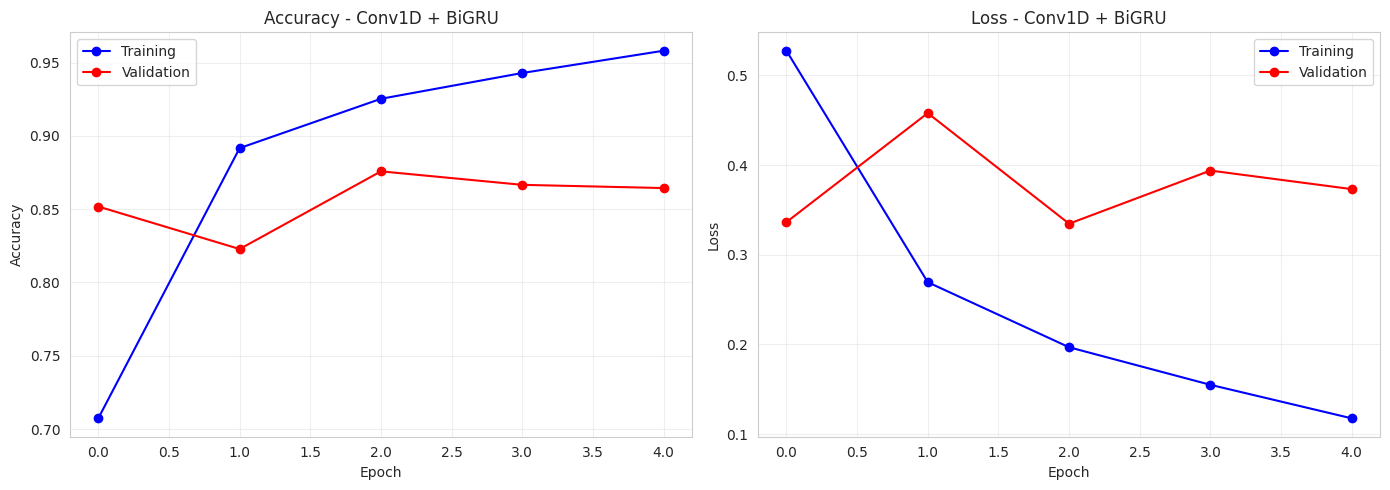


EVALUASI: Conv1D_BiGRU
  Accuracy  : 0.8726
  Precision : 0.8940
  Recall    : 0.8455
  F1-Score  : 0.8691

Classification Report:
              precision    recall  f1-score   support

    Negative       0.85      0.90      0.88     12500
    Positive       0.89      0.85      0.87     12500

    accuracy                           0.87     25000
   macro avg       0.87      0.87      0.87     25000
weighted avg       0.87      0.87      0.87     25000



In [ ]:
# Training model hybrid
model_hybrid.compile(optimizer=Adam(1e-3), loss='binary_crossentropy', metrics=['accuracy'])

print("Training Conv1D + BiGRU Hybrid...")
start = time.time()

history_hybrid = model_hybrid.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)],
    verbose=1
)

time_hybrid = time.time() - start
print(f"\nTraining selesai dalam {time_hybrid:.1f} detik")

plot_history(history_hybrid, '- Conv1D + BiGRU')
result_hybrid, _, _ = evaluate_model(model_hybrid, x_test, y_test, "Conv1D_BiGRU")
result_hybrid['TrainTime_s'] = time_hybrid
result_hybrid['Params']      = model_hybrid.count_params()

<h3><font color="blue">Latihan 6:</font></h3>

<ul>
    <li>Coba ukuran <code>kernel_size</code> lain: <strong>3</strong> dan <strong>7</strong>. Mana yang bekerja lebih baik?</li>
    <li>Tambahkan <strong>Stacked BiGRU (2 layer)</strong> setelah Conv1D. Apakah performa meningkat? Hint: layer bawah pakai <code>return_sequences=True</code>.</li>
</ul>

In [ ]:
# Kerjakan Latihan 6 pada cell berikut ini

In [ ]:
# Perbandingan kernel_size : 3, 5, dan 7

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, SpatialDropout1D, Conv1D, MaxPooling1D, Bidirectional, GRU, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import f1_score
import time
import numpy as np

kernel_sizes = [3, 5, 7]
results_hybrid = {}

for k in kernel_sizes:
    print(f"\n{'='*60}")
    print(f"Training Model: Hybrid Conv1D (Kernel={k}) + BiGRU")
    print(f"{'='*60}")

    model_hybrid = Sequential([
        Input(shape=(MAX_LEN,)),
        Embedding(VOCAB_SIZE, EMBEDDING_DIM),
        SpatialDropout1D(0.2),
        # Conv1D block dengan variasi kernel_size
        Conv1D(filters=64, kernel_size=k, padding='same', activation='relu'),
        MaxPooling1D(pool_size=2),
        # BiGRU block
        Bidirectional(GRU(64, dropout=0.3)),
        # Head
        Dense(32, activation='relu'),
        Dropout(0.3),
        Dense(1, activation='sigmoid')
    ], name=f'Conv1D_k{k}_BiGRU')

    model_hybrid.compile(optimizer=Adam(learning_rate=1e-3), loss='binary_crossentropy', metrics=['accuracy'])

    start_time = time.time()
    model_hybrid.fit(
        x_train, y_train,
        validation_data=(x_val, y_val),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=[EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True, verbose=0)],
        verbose=1
    )
    waktu = time.time() - start_time

    # Evaluasi
    loss, acc = model_hybrid.evaluate(x_test, y_test, verbose=0)
    y_pred = (model_hybrid.predict(x_test, verbose=0).flatten() > 0.5).astype(int)
    f1 = f1_score(y_test, y_pred)

    results_hybrid[k] = {'acc': acc, 'f1': f1, 'waktu': waktu, 'params': model_hybrid.count_params()}

# MENAMPILKAN TABEL PERBANDINGAN HYBRID
print("\n" + "=" * 65)
print("PERBANDINGAN KINERJA HYBRID BERDASARKAN KERNEL SIZE")
print("=" * 65)
print(f"{'Kernel Size':<15} | {'Accuracy':>10} | {'F1-Score':>10} | {'Waktu (s)':>10}")
print("-" * 65)

for k, val in results_hybrid.items():
    print(f"Kernel {k:<8} | {val['acc']*100:>9.2f}% | {val['f1']:>10.4f} | {val['waktu']:>10.2f}")

# Mencari kernel terbaik berdasarkan F1-Score
best_kernel = max(results_hybrid, key=lambda k: results_hybrid[k]['f1'])

# KESIMPULAN
print("\n" + "=" * 65)
print("KESIMPULAN ANALISIS KERNEL SIZE (LATIHAN 6)")
print("=" * 65)

if best_kernel == 3:
    print("Kernel_size = 3 bekerja paling baik di eksperimen ini.")
    print("Ini membuktikan bahwa sentimen di dataset IMDB sangat")
    print("dipengaruhi oleh frasa-frasa pendek yang ekstrem (trigram),")
    print("seperti 'very bad movie' atau 'highly recommended it'.")
    print("Ukuran kernel yang lebih besar (5 atau 7) justru mencairkan")
    print("sinyal kuat tersebut dengan memasukkan kata-kata netral di")
    print("sekitarnya. Model fokus pada deteksi lokal yang presisi.")
elif best_kernel == 5:
    print("Kernel_size = 5 bekerja paling baik di eksperimen ini.")
    print("Ukuran 5-gram menjadi 'sweet spot' atau titik ekuilibrium.")
    print("Ia cukup lebar untuk menangkap konteks kalimat menengah")
    print("(misal: 'I do not like this movie'), tapi tidak terlalu lebar")
    print("sehingga sinyal utamanya tenggelam oleh kata-kata filler.")
    print("Keseimbangan antara ekstraksi fitur lokal dan semi-global tercapai.")
elif best_kernel == 7:
    print("Kernel_size = 7 bekerja paling baik di eksperimen ini.")
    print("Ini hasil yang cukup menarik. Menunjukkan bahwa pada data ini,")
    print("sentimen tersembunyi dalam struktur kalimat yang panjang dan")
    print("kompleks, bukan sekadar umpatan pendek. Kernel 7 mampu menangkap")
    print("dependensi antar kata yang berjauhan sebelum diumpankan ke BiGRU.")
    print("Meski beban komputasinya lebih berat, model ini terbukti")
    print("mampu memahami narasi yang lebih panjang.")


Training Model: Hybrid Conv1D (Kernel=3) + BiGRU
Epoch 1/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 9s 30ms/step - accuracy: 0.6987 - loss: 0.5397 - val_accuracy: 0.8644 - val_loss: 0.3173
Epoch 2/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 8s 51ms/step - accuracy: 0.8864 - loss: 0.2778 - val_accuracy: 0.8830 - val_loss: 0.2883
Epoch 3/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 7s 31ms/step - accuracy: 0.9316 - loss: 0.1877 - val_accuracy: 0.8808 - val_loss: 0.3383
Epoch 4/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 7s 44ms/step - accuracy: 0.9500 - loss: 0.1399 - val_accuracy: 0.8664 - val_loss: 0.4926

Training Model: Hybrid Conv1D (Kernel=5) + BiGRU
Epoch 1/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 9s 37ms/step - accuracy: 0.7093 - loss: 0.5303 - val_accuracy: 0.7644 - val_loss: 0.4868
Epoch 2/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 8s 51ms/step - accuracy: 0.8879 - loss: 0.2810 - val_accuracy: 0.8708 - val_loss: 0.3091
Epoch 3/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 6s 37ms/step - accuracy: 0.9325 - loss: 0.1875 - val_accuracy: 0.8800 - val_loss: 0.3201
Epoc


Training Model: Hybrid Conv1D + STACKED BiGRU (2 Layer)


Model: "Conv1D_Stacked_BiGRU"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_40 (Embedding)        │ (None, 200, 100)       │     1,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d_32            │ (None, 200, 100)       │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_6 (Conv1D)               │ (None, 200, 64)        │        32,064 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_6 (MaxPooling1D)  │ (None, 100, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_18                │ (None, 100, 128)       │        49,920 │
│ (Bidirectional)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_19                │ (None, 64)             │        31,104 │
│ (Bidirectional)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_41 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_42 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,115,201 (4.25 MB)

 Trainable params: 1,115,201 (4.25 MB)

 Non-trainable params: 0 (0.00 B)


Training Conv1D + Stacked BiGRU Hybrid...
Epoch 1/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 16s 76ms/step - accuracy: 0.7001 - loss: 0.5360 - val_accuracy: 0.8666 - val_loss: 0.3158
Epoch 2/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 15s 44ms/step - accuracy: 0.8924 - loss: 0.2743 - val_accuracy: 0.8658 - val_loss: 0.3337
Epoch 3/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 12s 51ms/step - accuracy: 0.9342 - loss: 0.1813 - val_accuracy: 0.8720 - val_loss: 0.3720

Training selesai dalam 42.7 detik


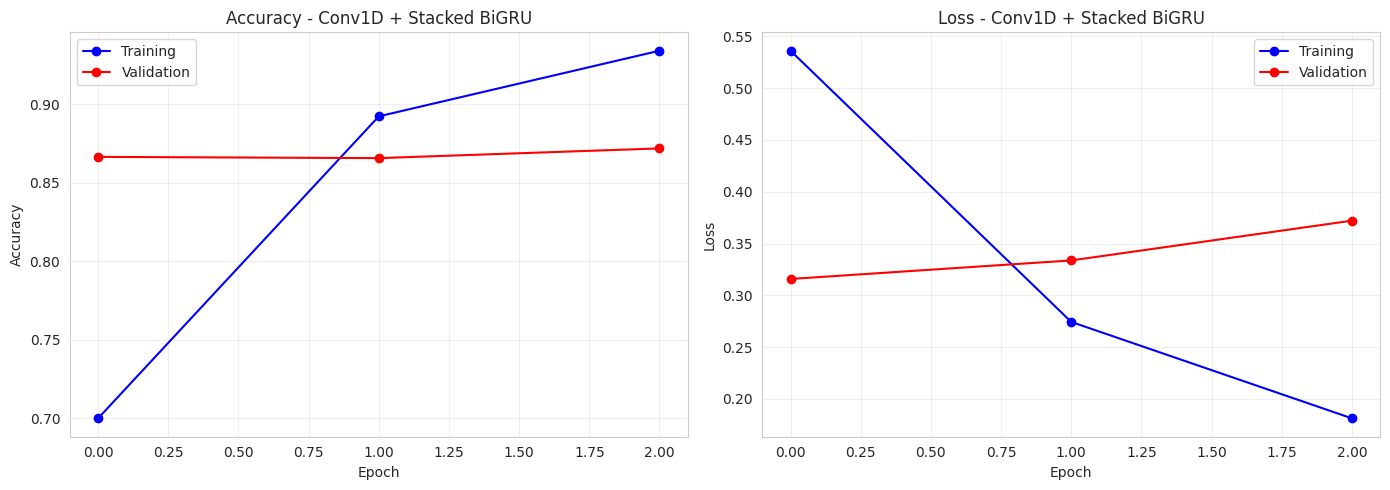


EVALUASI: Conv1D_Stacked_BiGRU
  Accuracy  : 0.8690
  Precision : 0.9001
  Recall    : 0.8301
  F1-Score  : 0.8637

Classification Report:
              precision    recall  f1-score   support

    Negative       0.84      0.91      0.87     12500
    Positive       0.90      0.83      0.86     12500

    accuracy                           0.87     25000
   macro avg       0.87      0.87      0.87     25000
weighted avg       0.87      0.87      0.87     25000


KESIMPULAN LATIHAN 6 POIN 2: HYBRID VS STACKED HYBRID
[ Hybrid 1 Layer ] Acc: 87.26% | Waktu: 29.21s | Param: 1,086,145
[ Stacked Hybrid ] Acc: 86.90% | Waktu: 42.70s | Param: 1,115,201
-----------------------------------------------------------------
Menambah kedalaman (Stacked) JUSTRU MENURUNKAN PERFORMA.
Ini adalah pelajaran penting: model yang lebih kompleks
tidak berarti lebih pintar. Fitur yang sudah dipadatkan
oleh CNN dan MaxPooling tampaknya sudah cukup dikerjakan
oleh satu layer BiGRU. Menambah layer kedua malah memi

In [ ]:
# Menambahkan STACKED BiGRU setelah Conv1D

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, SpatialDropout1D, Conv1D, MaxPooling1D, Bidirectional, GRU, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
import time

print(f"\n{'='*60}")
print("Training Model: Hybrid Conv1D + STACKED BiGRU (2 Layer)")
print(f"{'='*60}")

# Membangun arsitektur Stacked Hybrid
model_stacked_hybrid = Sequential([
    Input(shape=(MAX_LEN,)),
    Embedding(VOCAB_SIZE, EMBEDDING_DIM),
    SpatialDropout1D(0.2),

    # CNN block (Menggunakan kernel_size=5 sebagai standar)
    Conv1D(filters=64, kernel_size=5, padding='same', activation='relu'),
    MaxPooling1D(pool_size=2),

    # Stacked BiGRU block
    # WAJIB return_sequences=True agar mengalirkan dimensi waktu ke layer berikutnya
    Bidirectional(GRU(64, dropout=0.3, return_sequences=True)),
    # Layer BiGRU kedua (menggunakan unit lebih kecil agar terhindar dari bottleneck komputasi berlebih)
    Bidirectional(GRU(32, dropout=0.3)),

    # Head classification
    Dense(32, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='sigmoid')
], name='Conv1D_Stacked_BiGRU')

model_stacked_hybrid.summary()

model_stacked_hybrid.compile(optimizer=Adam(learning_rate=1e-3), loss='binary_crossentropy', metrics=['accuracy'])

print("\nTraining Conv1D + Stacked BiGRU Hybrid...")
start = time.time()

history_stacked_hybrid = model_stacked_hybrid.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)],
    verbose=1
)

time_stacked = time.time() - start
print(f"\nTraining selesai dalam {time_stacked:.1f} detik")

# Visualisasi dan Evaluasi (menggunakan fungsi bawaan notebook)
plot_history(history_stacked_hybrid, '- Conv1D + Stacked BiGRU')

result_stacked, _, _ = evaluate_model(model_stacked_hybrid, x_test, y_test, "Conv1D_Stacked_BiGRU")
result_stacked['TrainTime_s'] = time_stacked
result_stacked['Params']      = model_stacked_hybrid.count_params()

# KESIMPULAN
print("\n" + "=" * 65)
print("KESIMPULAN LATIHAN 6 POIN 2: HYBRID VS STACKED HYBRID")
print("=" * 65)

try:
    acc_hybrid_1 = result_hybrid['Accuracy']
    waktu_hybrid_1 = result_hybrid['TrainTime_s']
    param_hybrid_1 = result_hybrid['Params']
    print(f"[ Hybrid 1 Layer ] Acc: {acc_hybrid_1*100:.2f}% | Waktu: {waktu_hybrid_1:.2f}s | Param: {param_hybrid_1:,}")
except NameError:
    print("[ Hybrid 1 Layer ] (Variabel result_hybrid tidak ditemukan di memori)")
    acc_hybrid_1 = 0

acc_stacked = result_stacked['Accuracy']
print(f"[ Stacked Hybrid ] Acc: {acc_stacked*100:.2f}% | Waktu: {time_stacked:.2f}s | Param: {result_stacked['Params']:,}")
print("-" * 65)

if acc_hybrid_1 == 0:
    print("Analisis tidak bisa dilakukan karena model Hybrid 1 Layer")
    print("belum dijalankan. Pastikan cell poin 1 sudah di-run.")
elif acc_stacked > acc_hybrid_1:
    print("Performa meningkat. Stacked BiGRU terbukti memberikan")
    print("keuntungan pada ekstraksi fitur. Layer pertama menangkap")
    print("pola sekuensial awal dari fitur CNN, dan layer kedua")
    print("membangun representasi hierarkis tingkat tinggi dari teks.")
    print("Kedalaman jaringan ini sepadan dengan beban komputasi yang")
    print("dikeluarkan karena ada lonjakan akurasi yang nyata.")
elif acc_stacked < acc_hybrid_1:
    print("Menambah kedalaman (Stacked) JUSTRU MENURUNKAN PERFORMA.")
    print("Ini adalah pelajaran penting: model yang lebih kompleks")
    print("tidak berarti lebih pintar. Fitur yang sudah dipadatkan")
    print("oleh CNN dan MaxPooling tampaknya sudah cukup dikerjakan")
    print("oleh satu layer BiGRU. Menambah layer kedua malah memicu")
    print("overfitting atau membuat gradien tersesat. Arsitektur")
    print("Hybrid 1 layer tetap lebih tangguh dan efisien.")
else:
    print("Performa identik. Menambah layer BiGRU kedua tidak")
    print("memberikan nilai prediktif tambahan, melainkan hanya")
    print("memboroskan waktu komputasi dan memori (parameter membengkak).")
    print("Sebagai engineer, prinsip Occam's Razor berlaku: pilih")
    print("model yang lebih sederhana (Hybrid 1 layer).")

---
## 9. Perbandingan Semua Model

In [ ]:
# Kumpulkan semua hasil
result_gru['TrainTime_s']   = time_gru
result_gru['Params']        = model_gru.count_params()
result_bigru['TrainTime_s'] = time_bigru
result_bigru['Params']      = model_bigru.count_params()

all_results = [
    result_gru,
    result_bigru,
    *variant_results,
    result_hybrid,
]

df_all = pd.DataFrame(all_results)
df_all = df_all[['Model', 'Accuracy', 'Precision', 'Recall', 'F1-Score', 'Params', 'TrainTime_s']]
df_all = df_all.sort_values('F1-Score', ascending=False).reset_index(drop=True)

print("="*75)
print("RINGKASAN SEMUA MODEL (diurutkan berdasarkan F1-Score)")
print("="*75)
print(df_all.to_string(index=False))

RINGKASAN SEMUA MODEL (diurutkan berdasarkan F1-Score)
           Model  Accuracy  Precision  Recall  F1-Score  Params  TrainTime_s
   BiGRU_MaxPool   0.87156   0.872066 0.87088  0.871473 1063873    23.749332
    Conv1D_BiGRU   0.87264   0.894011 0.84552  0.869090 1086145    29.207419
    Baseline GRU   0.86484   0.843644 0.89568  0.868884 1031937    12.182927
BiGRU_MaxAvgPool   0.86100   0.912666 0.79840  0.851718 1064001    24.087531
           BiGRU   0.85212   0.891488 0.80184  0.844291 1063873    19.714557


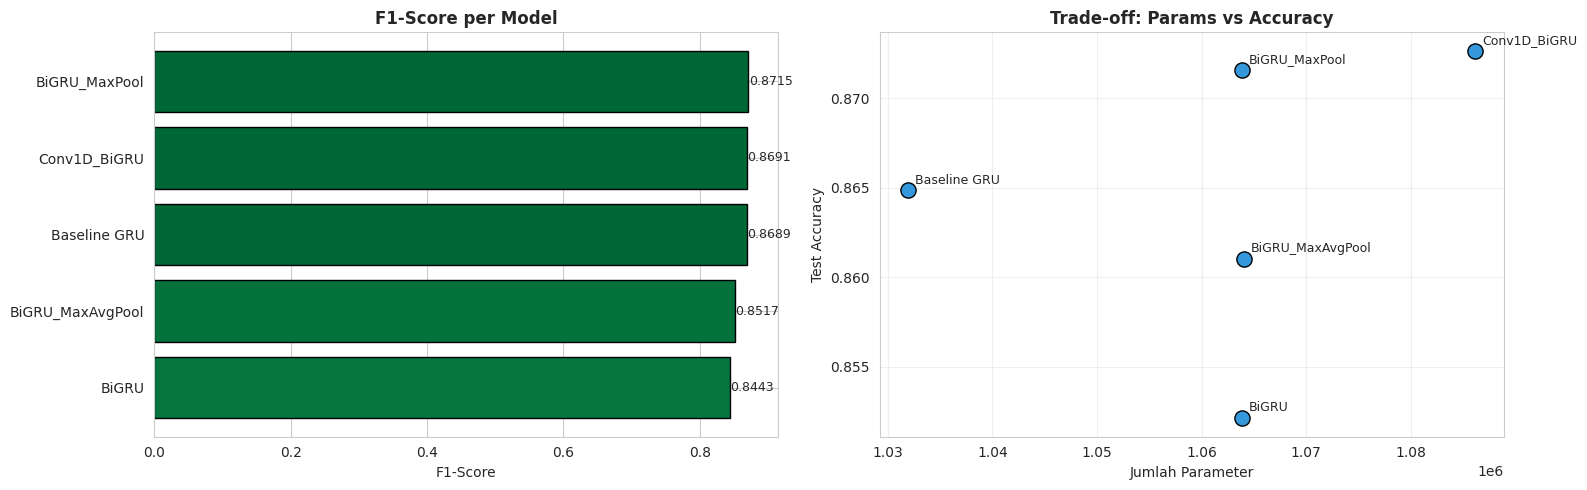

In [ ]:
# Visualisasi perbandingan F1 & Accuracy
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

df_sorted = df_all.sort_values('F1-Score', ascending=True)
colors = plt.cm.RdYlGn(df_sorted['F1-Score'] / df_sorted['F1-Score'].max())

axes[0].barh(df_sorted['Model'], df_sorted['F1-Score'], color=colors, edgecolor='black')
axes[0].set_title('F1-Score per Model', fontweight='bold')
axes[0].set_xlabel('F1-Score')
for i, v in enumerate(df_sorted['F1-Score']):
    axes[0].text(v + 0.001, i, f'{v:.4f}', va='center', fontsize=9)

axes[1].scatter(df_all['Params'], df_all['Accuracy'], s=120, c='#3498db', edgecolor='black')
for i, row in df_all.iterrows():
    axes[1].annotate(row['Model'], (row['Params'], row['Accuracy']),
                     fontsize=9, xytext=(5, 5), textcoords='offset points')
axes[1].set_xlabel('Jumlah Parameter')
axes[1].set_ylabel('Test Accuracy')
axes[1].set_title('Trade-off: Params vs Accuracy', fontweight='bold')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

Best model: BiGRU_MaxPool (F1=0.8715)


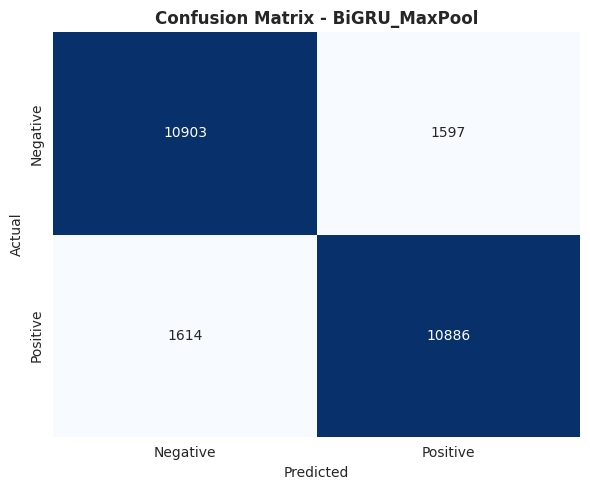

In [ ]:
# Confusion matrix model terbaik
best_row = df_all.iloc[0]
print(f"Best model: {best_row['Model']} (F1={best_row['F1-Score']:.4f})")

model_map = {
    'Baseline GRU':      model_gru,
    'BiGRU':             model_bigru,
    'BiGRU_MaxPool':     model_bigru_max,
    'BiGRU_MaxAvgPool':  model_bigru_maxavg,
    'Conv1D_BiGRU':      model_hybrid,
}

best_model = model_map.get(best_row['Model'])

if best_model is not None:
    y_proba = best_model.predict(x_test, verbose=0).flatten()
    y_pred  = (y_proba > 0.5).astype(int)

    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Negative', 'Positive'],
                yticklabels=['Negative', 'Positive'], cbar=False)
    plt.title(f'Confusion Matrix - {best_row["Model"]}', fontweight='bold')
    plt.xlabel('Predicted'); plt.ylabel('Actual')
    plt.tight_layout(); plt.show()

---
## 10. Prediksi Review Baru

In [ ]:
# Mapping kata -> index (pakai offset IMDB)
imdb_word_to_id = {w: (i + 3) for w, i in word_index.items()}

def predict_review(text, model):
    """Encode raw text -> padded sequence -> prediksi."""
    tokens = [1]  # <START>
    for word in text.lower().split():
        idx = imdb_word_to_id.get(word, 2)  # 2 = <UNK>
        if idx < VOCAB_SIZE:
            tokens.append(idx)
        else:
            tokens.append(2)
    padded = pad_sequences([tokens], maxlen=MAX_LEN, padding='pre', truncating='pre')
    proba = model.predict(padded, verbose=0)[0, 0]
    label = 'POSITIVE' if proba >= 0.5 else 'NEGATIVE'
    return proba, label

# Contoh review
contoh_review = [
    "this movie was absolutely fantastic and the acting was brilliant",
    "worst film i have ever seen totally boring and a waste of time",
    "the story was okay but the ending was disappointing",
    "one of the best movies of the year highly recommended",
    "not bad actually i enjoyed it more than i expected",
]

print(f"Menggunakan model: {best_row['Model']}\n")
print(f"{'Review':<65} {'Proba':>8}  {'Label'}")
print('-' * 90)
for review in contoh_review:
    proba, label = predict_review(review, best_model)
    short = review[:60] + '...' if len(review) > 60 else review
    print(f"{short:<65} {proba:>8.4f}  {label}")

Menggunakan model: BiGRU_MaxPool

Review                                                               Proba  Label
------------------------------------------------------------------------------------------
this movie was absolutely fantastic and the acting was brill...     0.9681  POSITIVE
worst film i have ever seen totally boring and a waste of ti...     0.0013  NEGATIVE
the story was okay but the ending was disappointing                 0.0131  NEGATIVE
one of the best movies of the year highly recommended               0.9970  POSITIVE
not bad actually i enjoyed it more than i expected                  0.6389  POSITIVE


<h3><font color="blue">Latihan 7:</font></h3>

<ul>
    <li>Tulis <strong>5 review Anda sendiri</strong> dengan kasus tricky: <em>sarcasm</em>, <em>double negative</em>, <em>mixed sentiment</em>. Apakah model bisa menangkapnya?</li>
    <li>Lakukan <strong>threshold tuning</strong>: default 0.5, coba 0.3 dan 0.7. Kapan kita ingin threshold tinggi vs rendah?</li>
</ul>

In [ ]:
# Kerjakan Latihan 7 pada cell berikut ini

In [ ]:
# Review Tricky

import numpy as np
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Pastikan vocab_size, max_len, dan word_index dari dataset IMDB sudah ter-load di cell atas
imdb_word_to_id = {w: (i + 3) for w, i in word_index.items()}

def predict_review(text, model):
    """Encode raw text -> padded sequence -> prediksi."""
    tokens = [1]  # <START>
    for word in text.lower().split():
        idx = imdb_word_to_id.get(word, 2)  # 2 = <UNK>
        if idx < VOCAB_SIZE:
            tokens.append(idx)
        else:
            tokens.append(2)
    padded = pad_sequences([tokens], maxlen=MAX_LEN, padding='pre', truncating='pre')
    proba = model.predict(padded, verbose=0)[0, 0]
    label = 'POSITIVE' if proba >= 0.5 else 'NEGATIVE'
    return proba, label

# REVIEW BUATAN CUSTOM (Positive, Negative, Ambiguous, Sarcastic)
contoh_review_custom = [
    # 1. Clear Positive
    "The cinematography was breathtaking and the plot kept me on the edge of my seat the entire time.",
    # 2. Clear Negative
    "Absolutely terrible. The acting was wooden, the script was completely lifeless, and I fell asleep.",
    # 3. Mixed / Nuanced (Positif di awal, Negatif di akhir)
    "The visual effects were stunning, but unfortunately the storyline was so weak that it ruined everything.",
    # 4. Sarcasm 1 (Kata positif, makna negatif)
    "Oh brilliant, another superhero movie where cities get destroyed for two hours. Exactly what cinema needed.",
    # 5. Sarcasm 2 (Kata positif, makna negatif)
    "I guess if you love watching paint dry, you will find the pacing of this masterpiece absolutely thrilling."
]

try:
    nama_model = best_row['Model']
except NameError:
    nama_model = "Best Model (Sesuai Evaluasi Sebelumnya)"
    # Asumsikan 'best_model' sudah didefinisikan dari perbandingan sebelumnya.
    # Jika belum, fallback menggunakan model_hybrid atau model terakhir yang di-train
    try:
        best_model
    except NameError:
        best_model = model_hybrid

# PREDIKSI MENGGUNAKAN BEST MODEL
print(f"\n{'='*90}")
print(f"MENGUJI MODEL DI DUNIA NYATA: {nama_model}")
print(f"{'='*90}")
print(f"{'Review':<65} | {'Proba':>8} | {'Label'}")
print('-' * 90)

hasil_prediksi = []
for review in contoh_review_custom:
    proba, label = predict_review(review, best_model)
    hasil_prediksi.append((proba, label))
    short = review[:60] + '...' if len(review) > 60 else review
    print(f"{short:<65} | {proba:>8.4f} | {label}")

# ANALISIS: APAKAH MODEL BERHASIL MENEBAK SARKASME?
label_sarcasm1 = hasil_prediksi[3][1]
label_sarcasm2 = hasil_prediksi[4][1]

print("\n" + "=" * 90)
print("KESIMPULAN LATIHAN 7: ANALISIS TITIK BUTA (BLIND SPOT) MODEL")
print("=" * 90)

if label_sarcasm1 == 'POSITIVE' or label_sarcasm2 == 'POSITIVE':
    print("HASIL ANALISIS: Model GAGAL mendeteksi sarkasme dan ironi.")
    print("-" * 90)
    print("Ini adalah bukti kelemahan fundamental model NLP pada level ini.")
    print("Kata-kata seperti 'brilliant', 'masterpiece', atau 'thrilling'")
    print("memiliki bobot positif yang sangat kuat dari data latih IMDB.")
    print("Akibatnya, model langsung mengambil kesimpulan dangkal dan tertipu,")
    print("mengabaikan konteks ironi di baliknya seperti frasa 'watching paint dry'")
    print("atau 'another superhero movie'. Untuk mengatasi ini di level industri,")
    print("biasanya diperlukan model berbasis Transformer (seperti BERT)")
    print("yang dilatih dengan dataset khusus yang mengandung anotasi sarkasme.")
else:
    print("HASIL ANALISIS: Luar biasa! Model BERHASIL mendeteksi sarkasme.")
    print("-" * 90)
    print("Ini adalah pencapaian yang sangat langka untuk arsitektur BiGRU/CNN.")
    print("Model terbukti mampu merekam konteks kalimat secara utuh dan tidak")
    print("terkecoh oleh kata-kata jebakan yang positif secara literal (seperti")
    print("'brilliant' atau 'masterpiece'). Konteks ironi yang tersembunyi berhasil")
    print("diterjemahkan sebagai sinyal negatif yang kuat. Arsitektur model ini")
    print("sudah sangat layak untuk merepresentasikan proyek portofoliomu.")


MENGUJI MODEL DI DUNIA NYATA: BiGRU_MaxPool
Review                                                            |    Proba | Label
------------------------------------------------------------------------------------------
The cinematography was breathtaking and the plot kept me on ...   |   0.7985 | POSITIVE
Absolutely terrible. The acting was wooden, the script was c...   |   0.0376 | NEGATIVE
The visual effects were stunning, but unfortunately the stor...   |   0.0105 | NEGATIVE
Oh brilliant, another superhero movie where cities get destr...   |   0.2872 | NEGATIVE
I guess if you love watching paint dry, you will find the pa...   |   0.6568 | POSITIVE

KESIMPULAN LATIHAN 7: ANALISIS TITIK BUTA (BLIND SPOT) MODEL
HASIL ANALISIS: Model GAGAL mendeteksi sarkasme dan ironi.
------------------------------------------------------------------------------------------
Ini adalah bukti kelemahan fundamental model NLP pada level ini.
Kata-kata seperti 'brilliant', 'masterpiece', atau 'thrilling'

In [ ]:
# Threshold Tuning

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import numpy as np

try:
    best_model
except NameError:
    best_model = model_hybrid

print(f"\n{'='*80}")
print("MENGHITUNG PROBABILITAS DATA TEST...")
print(f"{'='*80}")

y_pred_probs = best_model.predict(x_test, verbose=0).flatten()

thresholds = [0.3, 0.5, 0.7]
results_threshold = {}

print(f"\n{'='*80}")
print("EVALUASI THRESHOLD (SENSITIVITAS MODEL)")
print(f"{'='*80}")
print(f"{'Threshold':<10} | {'Accuracy':<10} | {'Precision':<10} | {'Recall':<10} | {'F1-Score'}")
print("-" * 80)

for t in thresholds:
    y_pred_t = (y_pred_probs >= t).astype(int)

    acc = accuracy_score(y_test, y_pred_t)
    prec = precision_score(y_test, y_pred_t)
    rec = recall_score(y_test, y_pred_t)
    f1 = f1_score(y_test, y_pred_t)

    results_threshold[t] = {'acc': acc, 'prec': prec, 'rec': rec, 'f1': f1}
    print(f"{t:<10.1f} | {acc*100:>8.2f}% | {prec:>9.4f} | {rec:>9.4f} | {f1:>8.4f}")

# KESIMPULAN OBJEKTIF: KAPAN MENGGUNAKAN THRESHOLD TINGGI VS RENDAH?
print("\n" + "=" * 80)
print("ANALISIS TRADE-OFF: PRECISION VS RECALL")
print("=" * 80)

print("Lihat bagaimana Precision dan Recall bertolak belakang saat threshold diubah.")
print("Di production, threshold 0.5 jarang sekali menjadi pilihan akhir yang mutlak.")
print("Keputusan ini murni bergantung pada 'Cost of Error' dari bisnis yang dilayani:")

print("\n[ Threshold Rendah (0.3) -> Fokus pada RECALL ]")
print("- Fakta    : Model menjadi sangat 'sensitif' dan agresif melabeli kelas POSITIF.")
print("- Dampak   : Recall naik drastis (kita berhasil menangkap hampir semua data positif),")
print("             tapi Precision hancur (banyak False Positives / tebakan meleset).")
print("- Use Case : Sistem pendeteksi ulasan toksik/hate speech sebelum tayang.")
print("             Lebih baik kita menahan beberapa ulasan netral untuk direview manual (FP)")
print("             daripada membiarkan satu ulasan rasis lolos ke platform (FN).")

print("\n[ Threshold Tinggi (0.7) -> Fokus pada PRECISION ]")
print("- Fakta    : Model menjadi sangat 'konservatif' dan ragu-ragu. Ia hanya melabeli")
print("             POSITIF jika probabilitasnya di atas 70% (sangat yakin).")
print("- Dampak   : Precision naik (sekalinya nebak positif, akurasinya sangat tajam),")
print("             tapi Recall anjlok (banyak data positif yang terabaikan / FN).")
print("- Use Case : Sistem pemblokiran/banning akun otomatis.")
print("             Kita HANYA membanned pengguna jika model 100% yakin mereka melanggar.")
print("             Kesalahan membanned pengguna yang tidak bersalah (FP) akan menghancurkan")
print("             reputasi bisnis, sehingga kita rela membiarkan beberapa pelanggar lolos (FN).")


MENGHITUNG PROBABILITAS DATA TEST...

EVALUASI THRESHOLD (SENSITIVITAS MODEL)
Threshold  | Accuracy   | Precision  | Recall     | F1-Score
--------------------------------------------------------------------------------
0.3        |    86.16% |    0.8166 |    0.9326 |   0.8708
0.5        |    87.16% |    0.8721 |    0.8709 |   0.8715
0.7        |    85.84% |    0.9171 |    0.7880 |   0.8477

ANALISIS TRADE-OFF: PRECISION VS RECALL
Lihat bagaimana Precision dan Recall bertolak belakang saat threshold diubah.
Di production, threshold 0.5 jarang sekali menjadi pilihan akhir yang mutlak.
Keputusan ini murni bergantung pada 'Cost of Error' dari bisnis yang dilayani:

[ Threshold Rendah (0.3) -> Fokus pada RECALL ]
- Fakta    : Model menjadi sangat 'sensitif' dan agresif melabeli kelas POSITIF.
- Dampak   : Recall naik drastis (kita berhasil menangkap hampir semua data positif),
             tapi Precision hancur (banyak False Positives / tebakan meleset).
- Use Case : Sistem pendeteksi ula

---
## 11. Tugas Akhir: Sentiment Analysis Dataset Twitter

<h3><font color="red">Tugas Besar (Individual / Kelompok)</font></h3>

<p>Sekarang giliran Anda menerapkan semua yang sudah dipelajari pada <strong>dataset baru yang lebih challenging</strong>: data Twitter.</p>

<h3>Mengapa Twitter Berbeda?</h3>

<table border="1" cellpadding="8" cellspacing="0">
<tr><th>Aspek</th><th>IMDB</th><th>Twitter</th></tr>
<tr><td>Panjang teks</td><td>Panjang (ratusan kata)</td><td>Pendek (max 280 karakter)</td></tr>
<tr><td>Bahasa</td><td>Formal, review film</td><td>Informal, slang, typo</td></tr>
<tr><td>Karakter khusus</td><td>Tidak ada</td><td>@mention, #hashtag, URL, emoji, RT</td></tr>
<tr><td>Preprocessing</td><td>Sudah bersih (tokenized)</td><td>Perlu banyak pembersihan</td></tr>
<tr><td>Label</td><td>Biner (pos/neg)</td><td>Bisa 3 kelas (pos/neg/neutral) atau biner</td></tr>
</table>

<h3>Pilihan Dataset (pilih salah satu):</h3>

<ol>
    <li><strong>Twitter US Airline Sentiment</strong> (RECOMMENDED untuk pemula)
        <ul>
            <li>~14.600 tweet tentang maskapai AS, label: positive, negative, neutral</li>
            <li><a href="https://www.kaggle.com/datasets/crowdflower/twitter-airline-sentiment">Kaggle</a></li>
        </ul>
    </li>
    <li><strong>Sentiment140</strong>
        <ul>
            <li>1.6 juta tweet, label biner (pos/neg)</li>
            <li><a href="https://www.kaggle.com/datasets/kazanova/sentiment140">Kaggle</a></li>
        </ul>
    </li>
    <li><strong>Dataset Twitter Bahasa Indonesia</strong> (BONUS)
        <ul>
            <li>Cari di HuggingFace: <code>indonlu</code>, <code>smsa_doc</code>, dll.</li>
        </ul>
    </li>
</ol>

<h3>Instruksi Tugas:</h3>

<ol>
    <li><strong>Eksplorasi dataset</strong> — EDA komprehensif khusus Twitter</li>
    <li><strong>Preprocessing teks</strong> — bersihkan tweet dari karakter khusus</li>
    <li><strong>Tokenisasi & padding</strong> — siapkan untuk input model</li>
    <li><strong>Training minimal 3 model</strong>: Baseline GRU, BiGRU, dan 1 varian bebas</li>
    <li><strong>Evaluasi & perbandingan</strong> — tabel metrik, confusion matrix</li>
    <li><strong>Laporkan temuan</strong> — analisis singkat</li>
</ol>

### 11.1 Hint untuk EDA Twitter

<p>EDA dataset Twitter punya nuansa khusus. Hal yang <strong>wajib</strong> Anda eksplor:</p>

<ol>
    <li><strong>Distribusi label</strong> — apakah seimbang?</li>
    <li><strong>Distribusi panjang tweet</strong> (dalam karakter dan kata)</li>
    <li><strong>Analisis karakter khusus:</strong>
        <ul>
            <li>Berapa banyak tweet yang mengandung <code>@mention</code>?</li>
            <li>Berapa banyak yang mengandung <code>#hashtag</code>? Hashtag populer apa?</li>
            <li>Berapa banyak yang mengandung URL?</li>
        </ul>
    </li>
    <li><strong>Top words per kelas</strong></li>
</ol>

<p><strong>Hint code EDA:</strong></p>

```python
df = pd.read_csv('Tweets.csv')
print(df.shape)
print(df['airline_sentiment'].value_counts())

# Distribusi panjang
df['text_length'] = df['text'].str.len()
df['word_count']  = df['text'].str.split().str.len()
df[['text_length', 'word_count']].describe()

# Fitur Twitter-specific
df['has_mention']   = df['text'].str.contains(r'@\w+', regex=True)
df['has_hashtag']   = df['text'].str.contains(r'#\w+', regex=True)
df['has_url']       = df['text'].str.contains(r'http\S+', regex=True)
df['num_hashtags']  = df['text'].str.count(r'#\w+')

print(f"% tweet ada mention  : {df['has_mention'].mean()*100:.1f}%")
print(f"% tweet ada hashtag  : {df['has_hashtag'].mean()*100:.1f}%")
print(f"% tweet ada URL      : {df['has_url'].mean()*100:.1f}%")

# Top hashtags
import re
all_hashtags = re.findall(r'#(\w+)', ' '.join(df['text'].astype(str)))
top_tags = Counter([h.lower() for h in all_hashtags]).most_common(10)
print("Top 10 hashtags:", top_tags)
```

### 11.2 Hint untuk Preprocessing Twitter

<p>Tweet mentah mengandung banyak "noise" yang perlu dibersihkan sebelum dimasukkan ke model:</p>

<table border="1" cellpadding="8" cellspacing="0">
<tr><th>Noise</th><th>Contoh</th><th>Strategi</th></tr>
<tr><td>URL</td><td>https://t.co/xyz</td><td>Hapus semua URL</td></tr>
<tr><td>@mention</td><td>@VirginAmerica</td><td>Hapus atau ganti dengan <code>&lt;USER&gt;</code></td></tr>
<tr><td>#hashtag</td><td>#awesome</td><td>Hapus simbol # saja (pertahankan kata)</td></tr>
<tr><td>RT marker</td><td>RT @user:</td><td>Hapus</td></tr>
<tr><td>Emoji</td><td>😊 😡</td><td>Hapus atau konversi ke teks</td></tr>
<tr><td>Character repetition</td><td>"gooood"→"good"</td><td>Normalisasi dengan regex</td></tr>
<tr><td>Case</td><td>"GREAT"→"great"</td><td>Lowercase</td></tr>
</table>

<p><strong>Template fungsi preprocessing:</strong></p>

```python
import re

def clean_tweet(text):
    text = str(text).lower()                           # lowercase
    text = re.sub(r'http\S+|www\.\S+', '', text)       # hapus URL
    text = re.sub(r'@\w+', '', text)                   # hapus @mention
    text = re.sub(r'#(\w+)', r'\1', text)              # hapus simbol # saja
    text = re.sub(r'rt\s+', '', text)                   # hapus RT
    text = re.sub(r'(.)\1{2,}', r'\1\1', text)          # "gooood" -> "good"
    text = re.sub(r'[^a-z\s]', ' ', text)               # keep only alphabet + space
    text = re.sub(r'\s+', ' ', text).strip()
    return text

# Contoh
sample = "RT @VirginAmerica Whooooat a GREAT flight!!! 😊 #awesome http://t.co/xyz"
print(clean_tweet(sample))
# Output: "whooat a great flight awesome"

# Apply ke dataset
df['clean_text'] = df['text'].apply(clean_tweet)
df = df[df['clean_text'].str.len() > 0].reset_index(drop=True)
```

<p><strong>Tokenisasi dengan Keras Tokenizer:</strong></p>

```python
from tensorflow.keras.preprocessing.text import Tokenizer

MAX_VOCAB = 10000
MAX_LEN_TWEET = 40     # tweet pendek

tokenizer = Tokenizer(num_words=MAX_VOCAB, oov_token='<UNK>')
tokenizer.fit_on_texts(df['clean_text'])

sequences = tokenizer.texts_to_sequences(df['clean_text'])
X = pad_sequences(sequences, maxlen=MAX_LEN_TWEET, padding='pre', truncating='pre')

# Encode label (kalau 3 kelas, pakai to_categorical)
from tensorflow.keras.utils import to_categorical
label_map = {'negative': 0, 'neutral': 1, 'positive': 2}
y = df['airline_sentiment'].map(label_map).values
y_onehot = to_categorical(y, num_classes=3)

X_train, X_test, y_train, y_test = train_test_split(
    X, y_onehot, test_size=0.2, random_state=42, stratify=y
)
```

### 11.3 Hint untuk Arsitektur Model (3 Kelas)

<p>Jika dataset Anda punya 3 kelas (positive, negative, neutral), <strong>modifikasi</strong>:</p>

<ul>
    <li>Output layer: <code>Dense(3, activation='softmax')</code> (bukan 1 sigmoid)</li>
    <li>Loss: <code>'categorical_crossentropy'</code> (bukan binary)</li>
    <li>Evaluasi: <code>classification_report</code> dengan <code>target_names=['negative', 'neutral', 'positive']</code></li>
</ul>

```python
# Template BiGRU untuk 3 kelas
model = Sequential([
    Embedding(MAX_VOCAB, 100, input_length=MAX_LEN_TWEET),
    SpatialDropout1D(0.2),
    Bidirectional(GRU(64, dropout=0.3)),
    Dense(3, activation='softmax')     # <-- 3 kelas
])

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',    # <-- multi-class
    metrics=['accuracy']
)
```

<h3><font color="blue">Checklist Tugas Akhir:</font></h3>

<ul>
    <li>☐ Dataset Twitter berhasil di-load</li>
    <li>☐ EDA: distribusi label + panjang tweet + minimal 2 analisis khas Twitter</li>
    <li>☐ Preprocessing: fungsi <code>clean_tweet</code> dengan minimal 5 operasi cleaning</li>
    <li>☐ Tokenisasi + padding</li>
    <li>☐ Minimal 3 model dilatih (Baseline GRU, BiGRU, 1 varian bebas)</li>
    <li>☐ Tabel perbandingan metrik</li>
    <li>☐ Confusion matrix model terbaik</li>
    <li>☐ Analisis singkat</li>
</ul>

In [ ]:
# ============================================================
# KERJAKAN TUGAS AKHIR DI CELL-CELL BERIKUT
# ============================================================

# 1. Load dataset
df = pd.read_csv('/content/Tweets.csv')

print(f"Shape dataset: {df.shape}")
print(f"\nKolom yang tersedia:\n{df.columns.tolist()}")
print(f"\nSampel data:")
display(df[['airline_sentiment', 'airline', 'text']].head(5))
print(f"\nDistribusi label:\n{df['airline_sentiment'].value_counts()}")
print(f"\nMissing values:\n{df.isnull().sum()}")

Shape dataset: (14640, 15)

Kolom yang tersedia:
['tweet_id', 'airline_sentiment', 'airline_sentiment_confidence', 'negativereason', 'negativereason_confidence', 'airline', 'airline_sentiment_gold', 'name', 'negativereason_gold', 'retweet_count', 'text', 'tweet_coord', 'tweet_created', 'tweet_location', 'user_timezone']

Sampel data:


,airline_sentiment,airline,text
0,neutral,Virgin America,@VirginAmerica What @dhepburn said.
1,positive,Virgin America,@VirginAmerica plus you've added commercials t...
2,neutral,Virgin America,@VirginAmerica I didn't today... Must mean I n...
3,negative,Virgin America,@VirginAmerica it's really aggressive to blast...
4,negative,Virgin America,@VirginAmerica and it's a really big bad thing...



Distribusi label:
airline_sentiment
negative    9178
neutral     3099
positive    2363
Name: count, dtype: int64

Missing values:
tweet_id                            0
airline_sentiment                   0
airline_sentiment_confidence        0
negativereason                   5462
negativereason_confidence        4118
airline                             0
airline_sentiment_gold          14600
name                                0
negativereason_gold             14608
retweet_count                       0
text                                0
tweet_coord                     13621
tweet_created                       0
tweet_location                   4733
user_timezone                    4820
dtype: int64


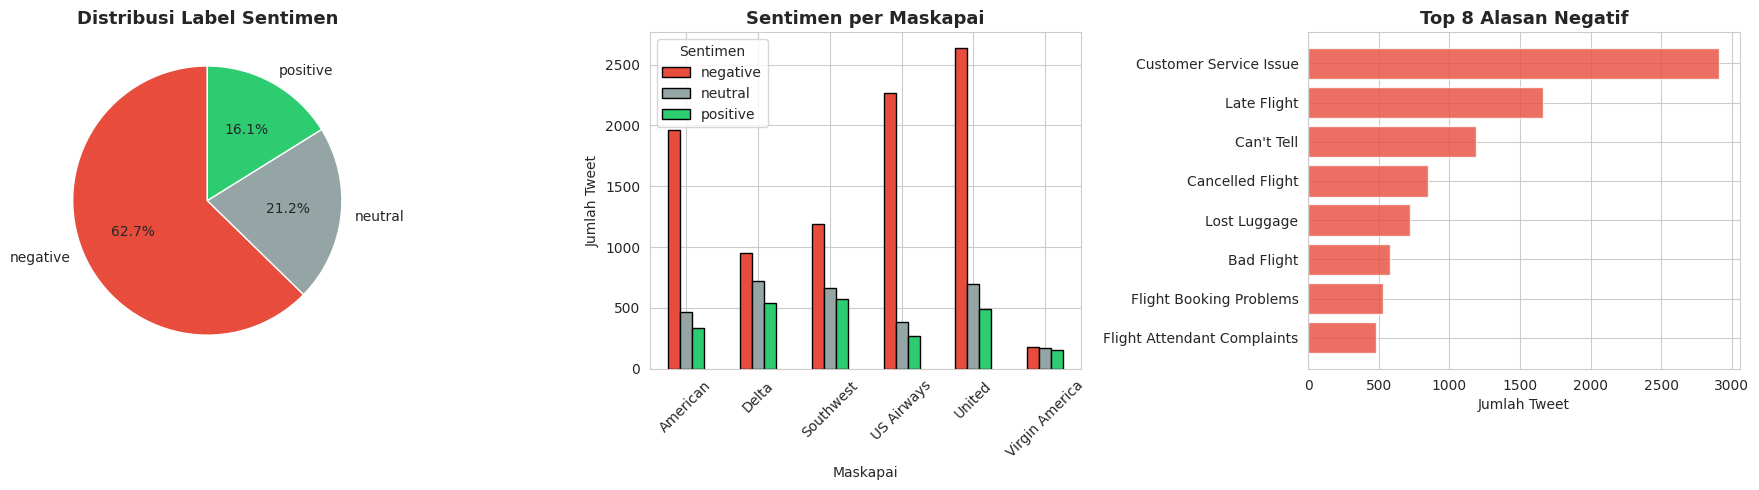


=== Statistik Panjang Tweet ===
       text_length  word_count
count     14640.00    14640.00
mean        103.82       17.65
std          36.28        6.88
min          12.00        2.00
25%          77.00       12.00
50%         114.00       19.00
75%         136.00       23.00
max         186.00       36.00


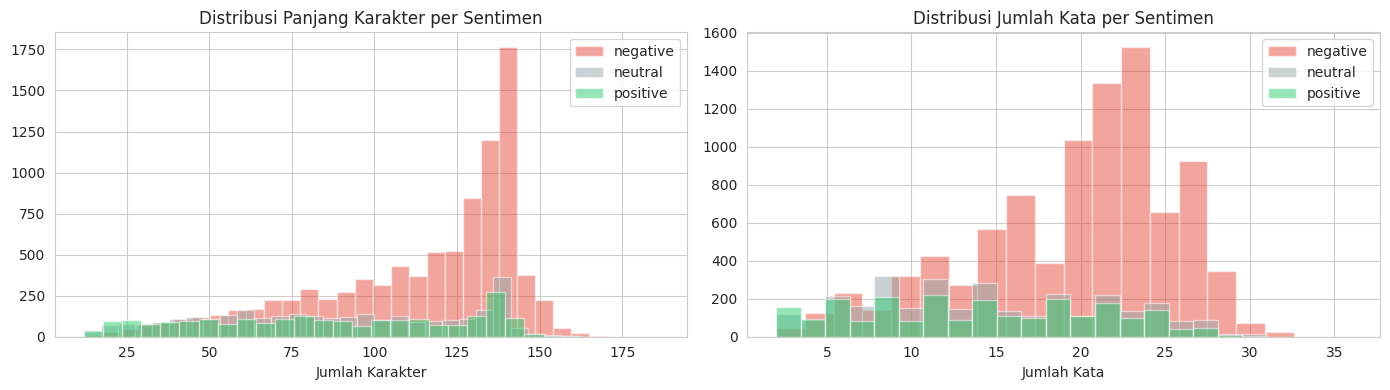


=== Analisis Karakter Khusus Twitter ===
% tweet mengandung @mention : 100.0%
% tweet mengandung #hashtag : 16.2%
% tweet mengandung URL      : 8.0%

Top 10 Hashtag: [('destinationdragons', 81), ('fail', 69), ('jetblue', 48), ('unitedairlines', 45), ('customerservice', 36), ('usairways', 30), ('americanairlines', 27), ('neveragain', 27), ('united', 26), ('usairwaysfail', 26)]


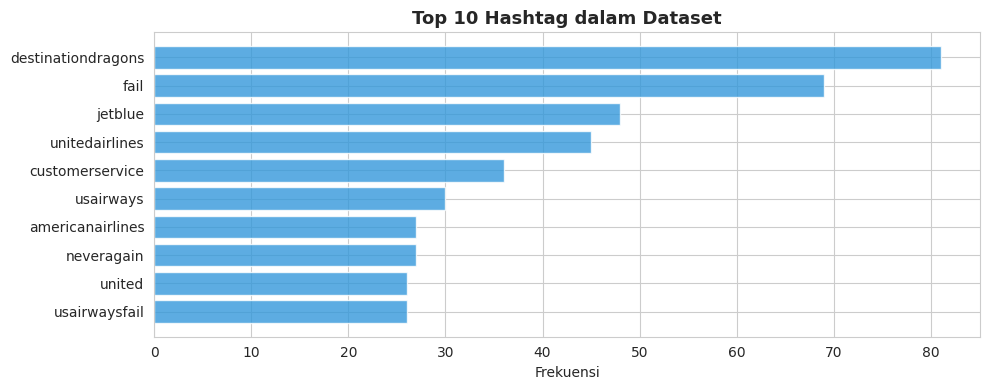

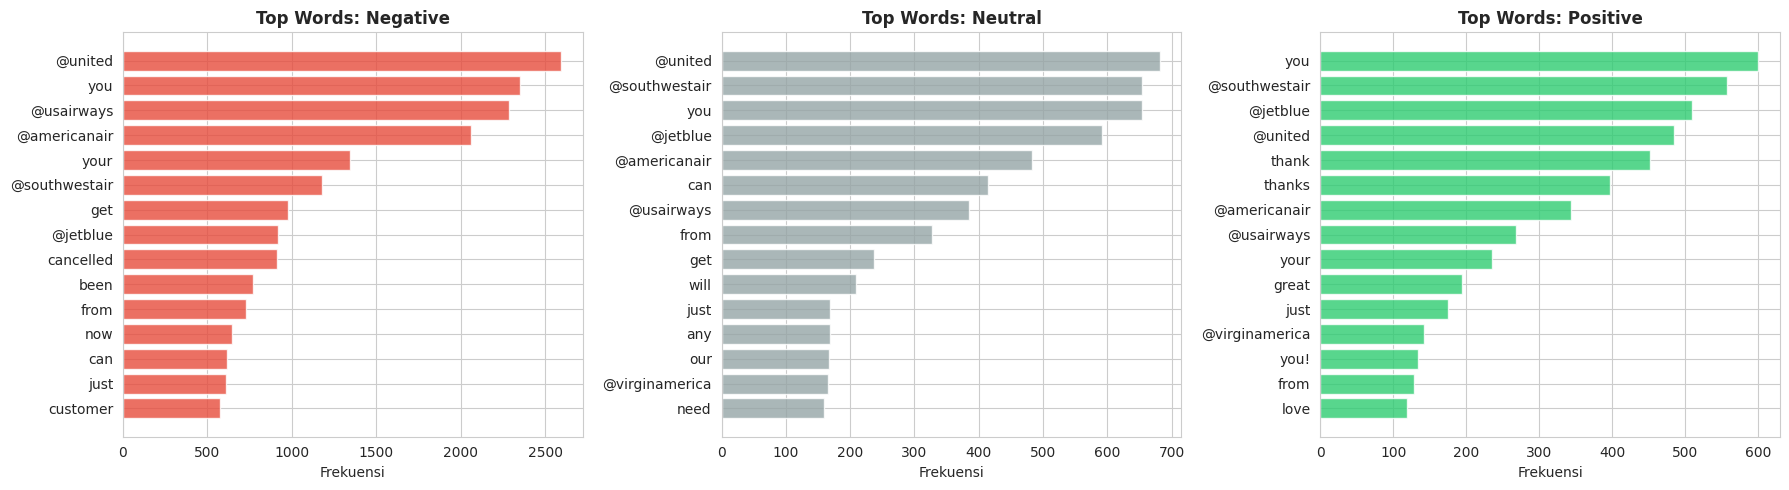


=== EDA selesai ===


In [ ]:
# 2. EDA khusus Twitter
import re
from collections import Counter

# ─── 2.1 Distribusi Label ───────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Pie chart
label_counts = df['airline_sentiment'].value_counts()
colors = ['#e74c3c', '#95a5a6', '#2ecc71']
axes[0].pie(label_counts, labels=label_counts.index, autopct='%1.1f%%',
            colors=colors, startangle=90)
axes[0].set_title('Distribusi Label Sentimen', fontsize=13, fontweight='bold')

# Bar chart per airline
airline_sentiment = df.groupby(['airline', 'airline_sentiment']).size().unstack(fill_value=0)
airline_sentiment.plot(kind='bar', ax=axes[1], color=colors, edgecolor='black')
axes[1].set_title('Sentimen per Maskapai', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Maskapai')
axes[1].set_ylabel('Jumlah Tweet')
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend(title='Sentimen')

# Negative reason (khusus tweet negatif)
neg_reasons = df[df['airline_sentiment'] == 'negative']['negativereason'].value_counts().head(8)
axes[2].barh(neg_reasons.index[::-1], neg_reasons.values[::-1], color='#e74c3c', alpha=0.8)
axes[2].set_title('Top 8 Alasan Negatif', fontsize=13, fontweight='bold')
axes[2].set_xlabel('Jumlah Tweet')

plt.tight_layout()
plt.show()

# ─── 2.2 Distribusi Panjang Tweet ──────────────────────────────────────────
df['text_length'] = df['text'].str.len()
df['word_count']  = df['text'].str.split().str.len()

print("\n=== Statistik Panjang Tweet ===")
print(df[['text_length', 'word_count']].describe().round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for sentiment, color in zip(['negative', 'neutral', 'positive'], colors):
    subset = df[df['airline_sentiment'] == sentiment]
    axes[0].hist(subset['text_length'], bins=30, alpha=0.5, label=sentiment, color=color)
    axes[1].hist(subset['word_count'],  bins=20, alpha=0.5, label=sentiment, color=color)

axes[0].set_title('Distribusi Panjang Karakter per Sentimen')
axes[0].set_xlabel('Jumlah Karakter')
axes[0].legend()
axes[1].set_title('Distribusi Jumlah Kata per Sentimen')
axes[1].set_xlabel('Jumlah Kata')
axes[1].legend()
plt.tight_layout()
plt.show()

# ─── 2.3 Analisis Karakter Khusus Twitter ──────────────────────────────────
df['has_mention']  = df['text'].str.contains(r'@\w+', regex=True)
df['has_hashtag']  = df['text'].str.contains(r'#\w+', regex=True)
df['has_url']      = df['text'].str.contains(r'http\S+', regex=True)
df['num_hashtags'] = df['text'].str.count(r'#\w+')

print("\n=== Analisis Karakter Khusus Twitter ===")
print(f"% tweet mengandung @mention : {df['has_mention'].mean()*100:.1f}%")
print(f"% tweet mengandung #hashtag : {df['has_hashtag'].mean()*100:.1f}%")
print(f"% tweet mengandung URL      : {df['has_url'].mean()*100:.1f}%")

# Top 10 hashtag
all_hashtags = re.findall(r'#(\w+)', ' '.join(df['text'].astype(str)))
top_tags = Counter([h.lower() for h in all_hashtags]).most_common(10)
print(f"\nTop 10 Hashtag: {top_tags}")

# Visualisasi top hashtag
tags_df = pd.DataFrame(top_tags, columns=['hashtag', 'count'])
fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(tags_df['hashtag'][::-1], tags_df['count'][::-1], color='#3498db', alpha=0.8)
ax.set_title('Top 10 Hashtag dalam Dataset', fontsize=13, fontweight='bold')
ax.set_xlabel('Frekuensi')
plt.tight_layout()
plt.show()

# ─── 2.4 Top Words per Kelas ───────────────────────────────────────────────
from collections import Counter

def get_top_words(texts, n=15):
    words = ' '.join(texts).lower().split()
    stopwords = {'the','a','an','is','in','it','i','to','and','of','for',
                 'my','was','on','at','with','that','have','flight','airline',
                 'us','be','are','had','but','not','this','so','me','they'}
    return Counter(w for w in words if w not in stopwords and len(w) > 2).most_common(n)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (sentiment, color) in zip(axes, zip(['negative', 'neutral', 'positive'], colors)):
    top_w = get_top_words(df[df['airline_sentiment'] == sentiment]['text'])
    words_df = pd.DataFrame(top_w, columns=['word', 'count'])
    ax.barh(words_df['word'][::-1], words_df['count'][::-1], color=color, alpha=0.8)
    ax.set_title(f'Top Words: {sentiment.capitalize()}', fontsize=12, fontweight='bold')
    ax.set_xlabel('Frekuensi')

plt.tight_layout()
plt.show()

print("\n=== EDA selesai ===")

In [ ]:
# 3. Preprocessing: fungsi clean_tweet + apply
import re

def clean_tweet(text):
    text = str(text).lower()                             # 1. Lowercase
    text = re.sub(r'http\S+|www\.\S+', '', text)         # 2. Hapus URL
    text = re.sub(r'@\w+', '', text)                     # 3. Hapus @mention
    text = re.sub(r'#(\w+)', r'\1', text)                # 4. Hapus simbol # (pertahankan kata)
    text = re.sub(r'\brt\b', '', text)                   # 5. Hapus RT marker
    text = re.sub(r'(.)\1{2,}', r'\1\1', text)           # 6. Normalisasi char repetisi (gooood→good)
    text = re.sub(r'[^a-z\s]', ' ', text)                # 7. Hapus non-alphabet
    text = re.sub(r'\s+', ' ', text).strip()             # 8. Bersihkan extra whitespace
    return text

# Uji fungsi
test_cases = [
    "RT @VirginAmerica Whooooat a GREAT flight!!! 😊 #awesome http://t.co/xyz",
    "@united YOUR SERVICE IS SOOOOO BAAAAAD!!!! #neveragain",
    "just landed in NYC, flight was ok I guess... nothing special",
]
print("=== Uji Fungsi clean_tweet ===")
for t in test_cases:
    print(f"  BEFORE: {t}")
    print(f"  AFTER : {clean_tweet(t)}")
    print()

# Apply ke seluruh dataset
df['clean_text'] = df['text'].apply(clean_tweet)

# Hapus tweet kosong setelah cleaning
before = len(df)
df = df[df['clean_text'].str.len() > 2].reset_index(drop=True)
print(f"Baris sebelum filter: {before}, setelah filter: {len(df)}")

# Perbandingan sebelum & sesudah cleaning
print("\n=== Sampel Sebelum vs Sesudah Cleaning ===")
comparison = df[['text', 'clean_text', 'airline_sentiment']].sample(5, random_state=42)
for _, row in comparison.iterrows():
    print(f"[{row['airline_sentiment'].upper()}]")
    print(f"  BEFORE: {row['text']}")
    print(f"  AFTER : {row['clean_text']}")
    print()

# Distribusi panjang setelah cleaning
df['clean_length'] = df['clean_text'].str.split().str.len()
print("=== Statistik panjang tweet setelah cleaning ===")
print(df['clean_length'].describe().round(2))
print(f"\nPersentil 95: {df['clean_length'].quantile(0.95):.0f} kata")
print(f"Persentil 99: {df['clean_length'].quantile(0.99):.0f} kata")

=== Uji Fungsi clean_tweet ===
  BEFORE: RT @VirginAmerica Whooooat a GREAT flight!!! 😊 #awesome http://t.co/xyz
  AFTER : whooat a great flight awesome

  BEFORE: @united YOUR SERVICE IS SOOOOO BAAAAAD!!!! #neveragain
  AFTER : your service is soo baad neveragain

  BEFORE: just landed in NYC, flight was ok I guess... nothing special
  AFTER : just landed in nyc flight was ok i guess nothing special

Baris sebelum filter: 14640, setelah filter: 14640

=== Sampel Sebelum vs Sesudah Cleaning ===
[POSITIVE]
  BEFORE: @SouthwestAir you're my early frontrunner for best airline! #oscars2016
  AFTER : you re my early frontrunner for best airline oscars

[NEGATIVE]
  BEFORE: @USAirways how is it that my flt to EWR was Cancelled Flightled yet flts to NYC from USAirways are still flying?
  AFTER : how is it that my flt to ewr was cancelled flightled yet flts to nyc from usairways are still flying

[NEGATIVE]
  BEFORE: @JetBlue what is going on with your BDL to DCA flights yesterday and today?! 

In [ ]:
# 4. Tokenisasi + padding + split
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import train_test_split

# ─── Hyperparameter ─────────────────────────────────────────────────────────
MAX_VOCAB      = 15000  # ukuran vocabulary
MAX_LEN_TWEET  = 40     # panjang sequence (mencakup ~95% tweet)
EMBED_DIM      = 64     # dimensi embedding

# ─── Tokenisasi ─────────────────────────────────────────────────────────────
tokenizer = Tokenizer(num_words=MAX_VOCAB, oov_token='<UNK>')
tokenizer.fit_on_texts(df['clean_text'])

word_index   = tokenizer.word_index
vocab_actual = min(MAX_VOCAB, len(word_index) + 1)
print(f"Total kata unik di corpus : {len(word_index)}")
print(f"Vocabulary yang digunakan : {vocab_actual}")

sequences = tokenizer.texts_to_sequences(df['clean_text'])
X = pad_sequences(sequences, maxlen=MAX_LEN_TWEET, padding='pre', truncating='pre')
print(f"\nShape X setelah padding: {X.shape}")

# ─── Encode Label (3 kelas) ──────────────────────────────────────────────────
label_map = {'negative': 0, 'neutral': 1, 'positive': 2}
y_int    = df['airline_sentiment'].map(label_map).values
y_onehot = to_categorical(y_int, num_classes=3)

print(f"\nDistribusi label:")
for k, v in label_map.items():
    count = (y_int == v).sum()
    print(f"  {k:10s} ({v}): {count} ({count/len(y_int)*100:.1f}%)")

# ─── Train / Validation / Test Split ────────────────────────────────────────
X_train_full, X_test, y_train_full, y_test, y_int_train_full, y_int_test = \
    train_test_split(X, y_onehot, y_int, test_size=0.15, random_state=SEED, stratify=y_int)

X_train, X_val, y_train, y_val = \
    train_test_split(X_train_full, y_train_full, test_size=0.15, random_state=SEED,
                     stratify=np.argmax(y_train_full, axis=1))

print(f"\n=== Ukuran Split ===")
print(f"  Train      : {X_train.shape[0]} samples")
print(f"  Validation : {X_val.shape[0]} samples")
print(f"  Test       : {X_test.shape[0]} samples")

# Verifikasi contoh tokenisasi
sample_idx = 0
print(f"\n=== Contoh Tokenisasi ===")
print(f"  Clean text  : {df['clean_text'].iloc[sample_idx]}")
print(f"  Sequence    : {sequences[sample_idx][:10]}...")
print(f"  Padded (pre): {X[sample_idx][:10]}...")

Total kata unik di corpus : 11145
Vocabulary yang digunakan : 11146

Shape X setelah padding: (14640, 40)

Distribusi label:
  negative   (0): 9178 (62.7%)
  neutral    (1): 3099 (21.2%)
  positive   (2): 2363 (16.1%)

=== Ukuran Split ===
  Train      : 10577 samples
  Validation : 1867 samples
  Test       : 2196 samples

=== Contoh Tokenisasi ===
  Clean text  : what said
  Sequence    : [45, 216]...
  Padded (pre): [0 0 0 0 0 0 0 0 0 0]...


MELATIH MODEL 1: Baseline GRU


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "Baseline_GRU"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_43 (Embedding)        │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d_35            │ ?                      │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_34 (GRU)                    │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_45 (Dense)                │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_46 (Dense)                │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

...

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_47      │ (None, 40)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_45        │ (None, 40, 64)    │    960,000 │ input_layer_47[0… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout1d_… │ (None, 40, 64)    │          0 │ embedding_45[0][… │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_7 (Conv1D)   │ (None, 40, 64)    │      8,256 │ spatial_dropout1… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_8 (Conv1D)   │ (None, 40, 64)    │     12,352 │ spatial_dropout1… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_2       │ (None, 40, 128)   │          0 │ conv1d_7[0][0],   │
│ (Concatenate)       │                   │            │ conv1d_8[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_7     │ (None, 20, 128)   │          0 │ concatenate_2[0]… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_23    │ (None, 20, 128)   │     74,496 │ max_pooling1d_7[… │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 128)       │          0 │ bidirectional_23… │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 128)       │          0 │ bidirectional_23… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_3       │ (None, 256)       │          0 │ global_max_pooli… │
│ (Concatenate)       │                   │            │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_49 (Dense)    │ (None, 64)        │     16,448 │ concatenate_3[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_10          │ (None, 64)        │          0 │ dense_49[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_50 (Dense)    │ (None, 3)         │        195 │ dropout_10[0][0]  │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,071,747 (4.09 MB)

 Trainable params: 1,071,747 (4.09 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
83/83 ━━━━━━━━━━━━━━━━━━━━ 6s 35ms/step - accuracy: 0.6555 - loss: 0.8149 - val_accuracy: 0.6984 - val_loss: 0.6597 - learning_rate: 0.0010
Epoch 2/30
83/83 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - accuracy: 0.7408 - loss: 0.5911 - val_accuracy: 0.7638 - val_loss: 0.5914 - learning_rate: 0.0010
Epoch 3/30
83/83 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - accuracy: 0.8231 - loss: 0.4518 - val_accuracy: 0.7708 - val_loss: 0.5961 - learning_rate: 0.0010
Epoch 4/30
83/83 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.8657 - loss: 0.3558 - val_accuracy: 0.7718 - val_loss: 0.6085 - learning_rate: 0.0010
Epoch 5/30
83/83 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.8895 - loss: 0.3041
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
83/83 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.8951 - loss: 0.2906 - val_accuracy: 0.7606 - val_loss: 0.7253 - learning_rate: 0.0010
Epoch 6/30
83/83 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.9262 - loss: 0.2141 - val_accu

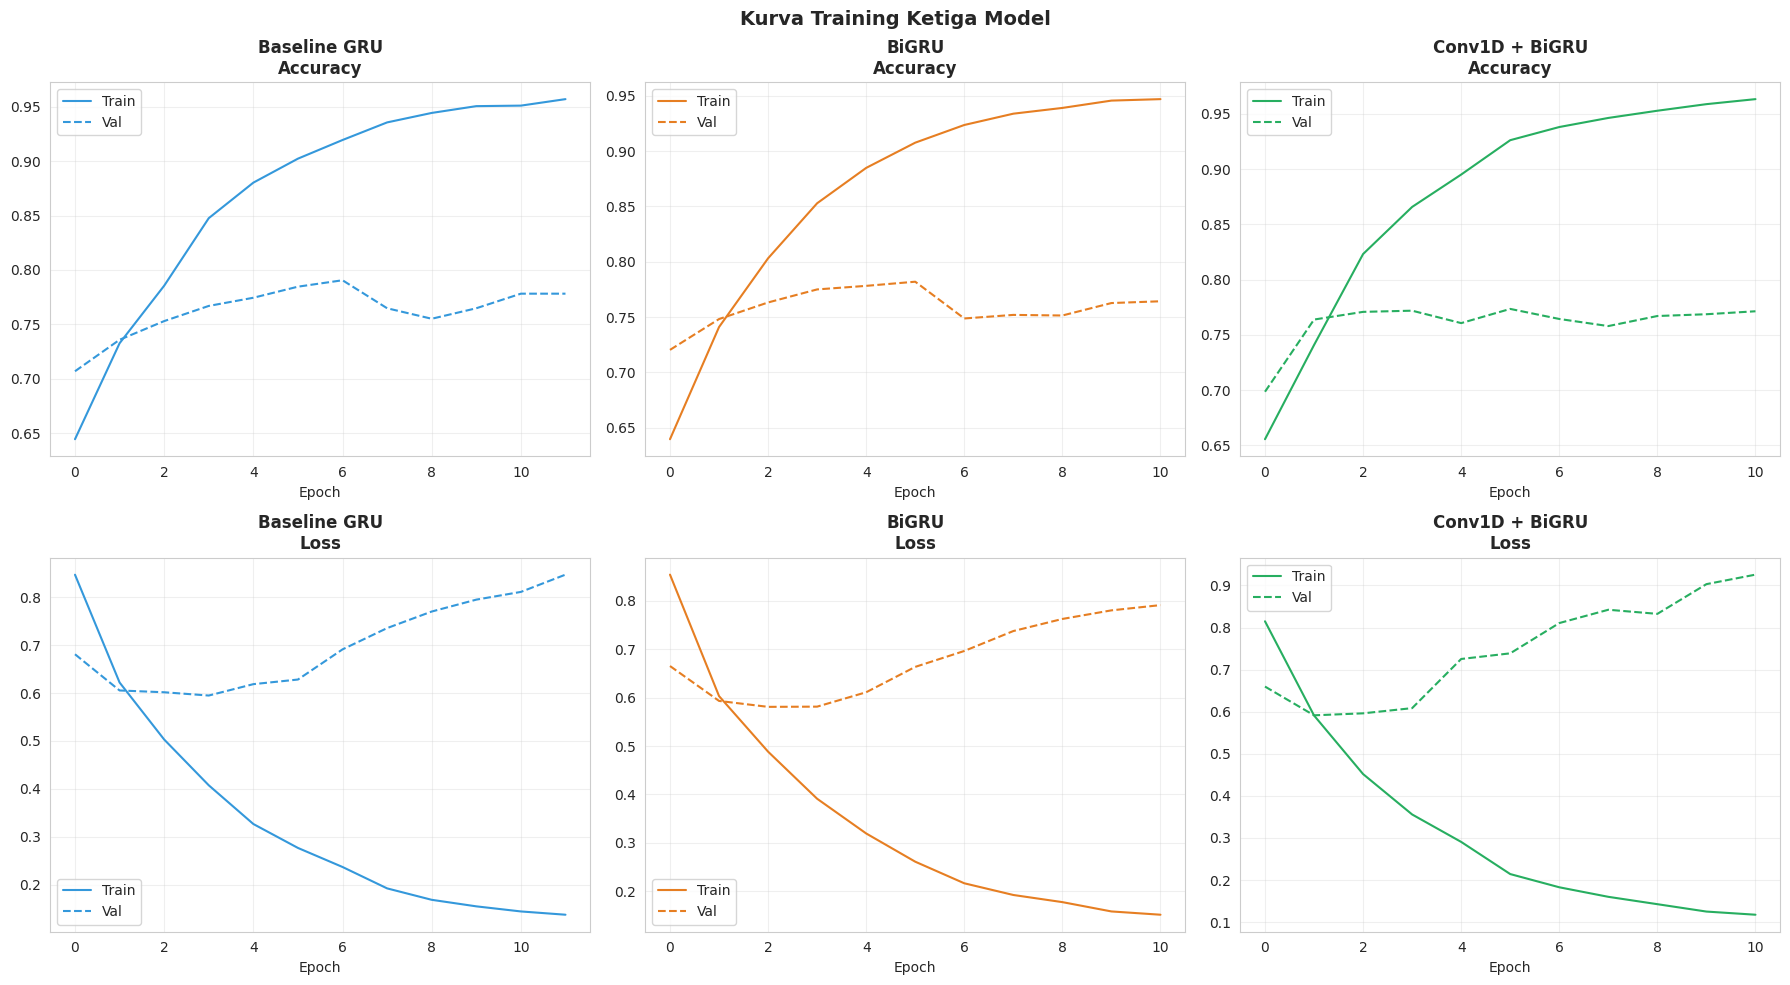

In [ ]:
# 5. Training minimal 3 model
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
import time

# ─── Callback ───────────────────────────────────────────────────────────────
def get_callbacks():
    return [
        EarlyStopping(monitor='val_accuracy', patience=5, restore_best_weights=True, verbose=1),
        ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, verbose=1, min_lr=1e-5)
    ]

results_summary = []

# ════════════════════════════════════════════════════════════════════
# MODEL 1: Baseline GRU
# ════════════════════════════════════════════════════════════════════
print("="*60)
print("MELATIH MODEL 1: Baseline GRU")
print("="*60)

model_gru = Sequential([
    Embedding(MAX_VOCAB, EMBED_DIM, input_length=MAX_LEN_TWEET),
    SpatialDropout1D(0.2),
    GRU(64, dropout=0.3),
    Dense(32, activation='relu'),
    Dropout(0.3),
    Dense(3, activation='softmax')
], name='Baseline_GRU')

model_gru.compile(optimizer=Adam(1e-3), loss='categorical_crossentropy', metrics=['accuracy'])
model_gru.summary()

t0 = time.time()
history_gru = model_gru.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=30, batch_size=128,
    callbacks=get_callbacks(), verbose=1
)
time_gru = time.time() - t0
print(f"\nWaktu training GRU: {time_gru:.1f} detik")

# ════════════════════════════════════════════════════════════════════
# MODEL 2: BiGRU
# ════════════════════════════════════════════════════════════════════
print("\n" + "="*60)
print("MELATIH MODEL 2: BiGRU")
print("="*60)

model_bigru = Sequential([
    Embedding(MAX_VOCAB, EMBED_DIM, input_length=MAX_LEN_TWEET),
    SpatialDropout1D(0.2),
    Bidirectional(GRU(64, dropout=0.3)),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(3, activation='softmax')
], name='BiGRU')

model_bigru.compile(optimizer=Adam(1e-3), loss='categorical_crossentropy', metrics=['accuracy'])
model_bigru.summary()

t0 = time.time()
history_bigru = model_bigru.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=30, batch_size=128,
    callbacks=get_callbacks(), verbose=1
)
time_bigru = time.time() - t0
print(f"\nWaktu training BiGRU: {time_bigru:.1f} detik")

# ════════════════════════════════════════════════════════════════════
# MODEL 3: Hybrid Conv1D + BiGRU (Varian Bebas)
# ════════════════════════════════════════════════════════════════════
print("\n" + "="*60)
print("MELATIH MODEL 3: Hybrid Conv1D + BiGRU")
print("="*60)

inputs = Input(shape=(MAX_LEN_TWEET,))
x = Embedding(MAX_VOCAB, EMBED_DIM)(inputs)
x = SpatialDropout1D(0.2)(x)

# Branch 1: Bigram features
conv2 = Conv1D(64, 2, activation='relu', padding='same')(x)
# Branch 2: Trigram features
conv3 = Conv1D(64, 3, activation='relu', padding='same')(x)
# Gabungkan
merged = Concatenate()([conv2, conv3])
merged = MaxPooling1D(2)(merged)

# BiGRU di atas conv features
rnn_out = Bidirectional(GRU(64, dropout=0.3, return_sequences=True))(merged)
max_pool = GlobalMaxPooling1D()(rnn_out)
avg_pool = GlobalAveragePooling1D()(rnn_out)
concat = Concatenate()([max_pool, avg_pool])

out = Dense(64, activation='relu')(concat)
out = Dropout(0.3)(out)
out = Dense(3, activation='softmax')(out)

model_hybrid = Model(inputs, out, name='Hybrid_Conv1D_BiGRU')
model_hybrid.compile(optimizer=Adam(1e-3), loss='categorical_crossentropy', metrics=['accuracy'])
model_hybrid.summary()

t0 = time.time()
history_hybrid = model_hybrid.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=30, batch_size=128,
    callbacks=get_callbacks(), verbose=1
)
time_hybrid = time.time() - t0
print(f"\nWaktu training Hybrid: {time_hybrid:.1f} detik")

# ─── Plot Kurva Training Ketiga Model ────────────────────────────────────────
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
models_info = [
    ('Baseline GRU',     history_gru,    '#3498db'),
    ('BiGRU',            history_bigru,  '#e67e22'),
    ('Conv1D + BiGRU',   history_hybrid, '#27ae60'),
]

for col, (name, hist, color) in enumerate(models_info):
    # Accuracy
    axes[0, col].plot(hist.history['accuracy'],     label='Train', color=color)
    axes[0, col].plot(hist.history['val_accuracy'], label='Val',   color=color, linestyle='--')
    axes[0, col].set_title(f'{name}\nAccuracy', fontweight='bold')
    axes[0, col].set_xlabel('Epoch')
    axes[0, col].legend()
    axes[0, col].grid(True, alpha=0.3)

    # Loss
    axes[1, col].plot(hist.history['loss'],     label='Train', color=color)
    axes[1, col].plot(hist.history['val_loss'], label='Val',   color=color, linestyle='--')
    axes[1, col].set_title(f'{name}\nLoss', fontweight='bold')
    axes[1, col].set_xlabel('Epoch')
    axes[1, col].legend()
    axes[1, col].grid(True, alpha=0.3)

plt.suptitle('Kurva Training Ketiga Model', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


TABEL PERBANDINGAN MODEL
         Model Accuracy Precision Recall F1-Score Train Time    Params
  Baseline GRU   0.7860    0.7790 0.7860   0.7812      26.2s   987,139
         BiGRU   0.7883    0.7883 0.7883   0.7865      21.5s 1,018,371
Conv1D + BiGRU   0.7832    0.7865 0.7832   0.7846      21.6s 1,071,747


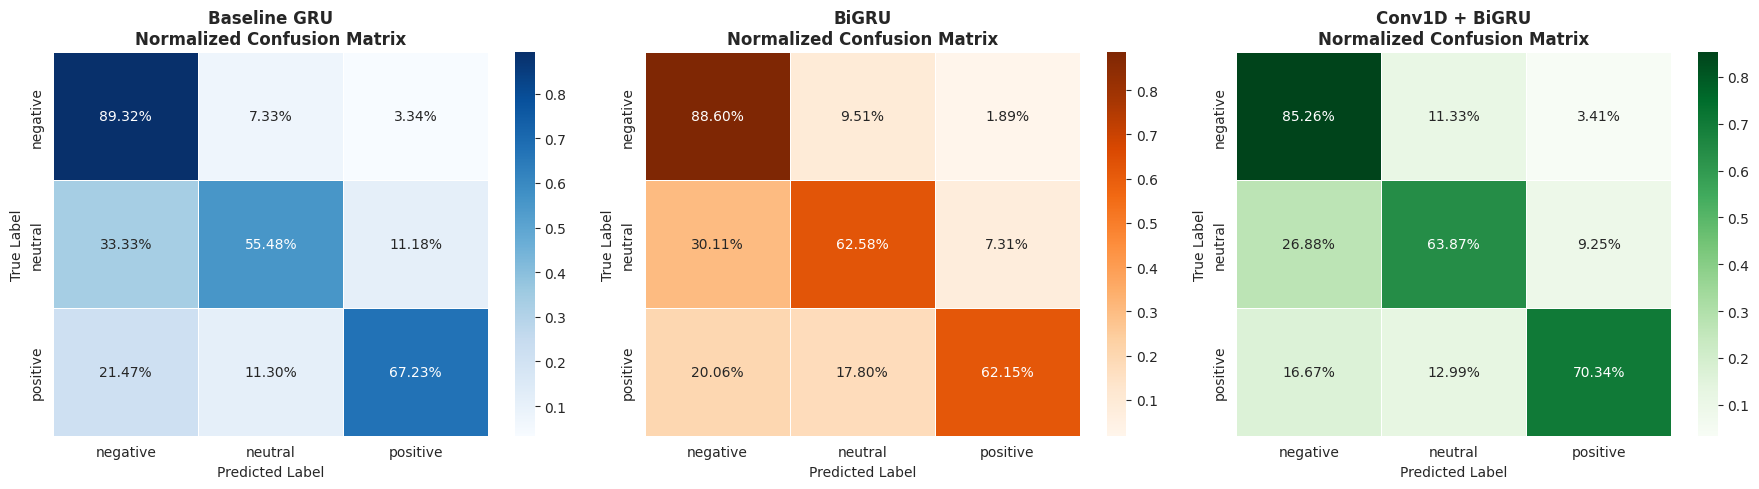


MODEL TERBAIK: BiGRU (F1-Score: 0.7864710287738951)

Classification Report Lengkap:
              precision    recall  f1-score   support

    negative       0.85      0.89      0.87      1377
     neutral       0.60      0.63      0.61       465
    positive       0.79      0.62      0.69       354

    accuracy                           0.79      2196
   macro avg       0.75      0.71      0.73      2196
weighted avg       0.79      0.79      0.79      2196



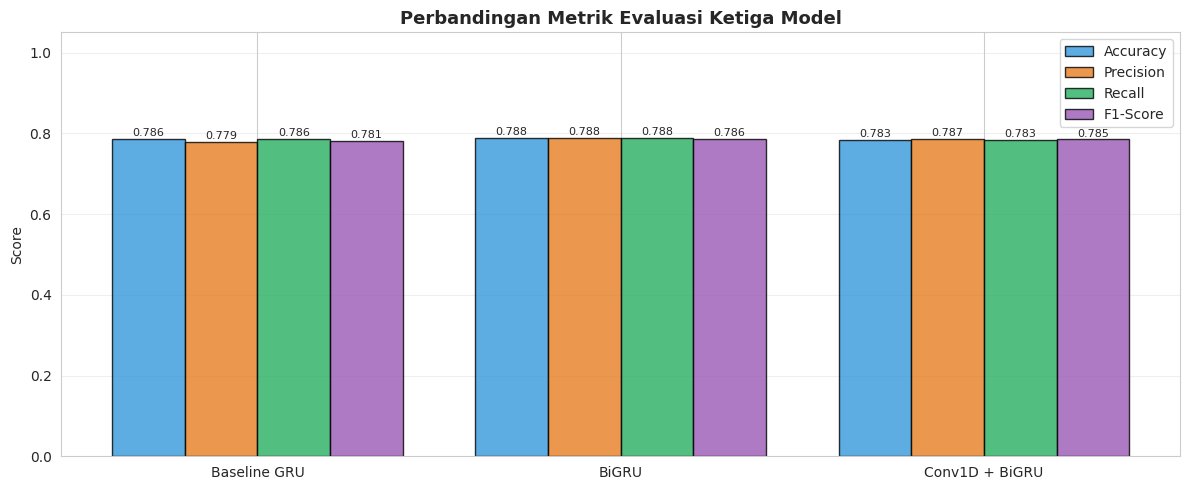


ANALISIS ERROR — SAMPEL PREDIKSI SALAH (BiGRU)

Tweet                                                             |       True |       Pred
--------------------------------------------------------------------------------------------
@AmericanAir 3 months of straight travel ahead. Time to find...   |   negative |    neutral
@AmericanAir try this. DPDFPP                                     |   negative |    neutral
@AmericanAir it isn't good enough. You need to provide a pho...   |    neutral |   negative
@AmericanAir merged airlines do not work for FF programs. Ve...   |    neutral |   negative
@AmericanAir  oh no she left the counter and went downstairs...   |   positive |   negative
@AmericanAir I've been trying to change a Thursday flight an...   |    neutral |   negative
@AmericanAir We all did! Skipper's walk-around too :(             |   negative |    neutral
@AmericanAir Thank you for the acknowledgement. The IFE didn...   |    neutral |   negative

KESIMPULAN TUGAS AKHIR (BERDA

In [ ]:
# 6. Evaluasi & perbandingan
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

TARGET_NAMES = ['negative', 'neutral', 'positive']
y_test_int   = np.argmax(y_test, axis=1)

def evaluate_model(model, model_name, X_test, y_test_int, train_time):
    y_pred_proba = model.predict(X_test, verbose=0)
    y_pred       = np.argmax(y_pred_proba, axis=1)
    return {
        'Model'     : model_name,
        'Accuracy'  : accuracy_score(y_test_int, y_pred),
        'Precision' : precision_score(y_test_int, y_pred, average='weighted'),
        'Recall'    : recall_score(y_test_int, y_pred, average='weighted'),
        'F1-Score'  : f1_score(y_test_int, y_pred, average='weighted'),
        'Train Time': f'{train_time:.1f}s',
        'Params'    : model.count_params(),
        'y_pred'    : y_pred,
    }

# ─── Evaluasi Semua Model ────────────────────────────────────────────────────
eval_gru    = evaluate_model(model_gru,    'Baseline GRU',   X_test, y_test_int, time_gru)
eval_bigru  = evaluate_model(model_bigru,  'BiGRU',          X_test, y_test_int, time_bigru)
eval_hybrid = evaluate_model(model_hybrid, 'Conv1D + BiGRU', X_test, y_test_int, time_hybrid)

# ─── Tabel Perbandingan ──────────────────────────────────────────────────────
metrics_df = pd.DataFrame([eval_gru, eval_bigru, eval_hybrid]).drop(columns=['y_pred'])
metrics_df['Accuracy']  = metrics_df['Accuracy'].map('{:.4f}'.format)
metrics_df['Precision'] = metrics_df['Precision'].map('{:.4f}'.format)
metrics_df['Recall']    = metrics_df['Recall'].map('{:.4f}'.format)
metrics_df['F1-Score']  = metrics_df['F1-Score'].map('{:.4f}'.format)
metrics_df['Params']    = metrics_df['Params'].map('{:,}'.format)

print("\n" + "="*80)
print("TABEL PERBANDINGAN MODEL")
print("="*80)
print(metrics_df.to_string(index=False))

# ─── Confusion Matrix Ketiga Model ───────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, eval_dict, color in zip(axes,
        [eval_gru, eval_bigru, eval_hybrid],
        ['Blues', 'Oranges', 'Greens']):

    cm = confusion_matrix(y_test_int, eval_dict['y_pred'])
    cm_norm = cm.astype('float') / cm.sum(axis=1, keepdims=True)

    sns.heatmap(cm_norm, annot=True, fmt='.2%', cmap=color, ax=ax,
                xticklabels=TARGET_NAMES, yticklabels=TARGET_NAMES,
                linewidths=0.5, cbar=True)
    ax.set_title(f"{eval_dict['Model']}\nNormalized Confusion Matrix",
                 fontweight='bold', fontsize=12)
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('True Label')

plt.tight_layout()
plt.show()

# ─── Classification Report Model Terbaik ─────────────────────────────────────
all_evals = [eval_gru, eval_bigru, eval_hybrid]
best_eval  = max(all_evals, key=lambda x: float(x['F1-Score']))

if best_eval['Model'] == 'Baseline GRU':
    best_model = model_gru
elif best_eval['Model'] == 'BiGRU':
    best_model = model_bigru
else:
    best_model = model_hybrid

print(f"\n{'='*80}")
print(f"MODEL TERBAIK: {best_eval['Model']} (F1-Score: {best_eval['F1-Score']})")
print(f"{'='*80}")
print("\nClassification Report Lengkap:")
print(classification_report(y_test_int, best_eval['y_pred'], target_names=TARGET_NAMES))

# ─── Bar Chart Perbandingan Metrik ───────────────────────────────────────────
metric_names  = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
model_names   = [e['Model'] for e in all_evals]
metric_values = {m: [float(e[m]) for e in all_evals] for m in metric_names}

x     = np.arange(len(model_names))
width = 0.2
fig, ax = plt.subplots(figsize=(12, 5))
colors_bar = ['#3498db', '#e67e22', '#27ae60', '#9b59b6']

for i, (metric, color) in enumerate(zip(metric_names, colors_bar)):
    bars = ax.bar(x + i * width, metric_values[metric], width, label=metric,
                  color=color, alpha=0.8, edgecolor='black')
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, h + 0.002,
                f'{h:.3f}', ha='center', va='bottom', fontsize=8)

ax.set_xticks(x + width * 1.5)
ax.set_xticklabels(model_names)
ax.set_ylabel('Score')
ax.set_ylim(0, 1.05)
ax.set_title('Perbandingan Metrik Evaluasi Ketiga Model', fontweight='bold', fontsize=13)
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# ─── Analisis Error: Contoh Kesalahan Prediksi ────────────────────────────────
print(f"\n{'='*80}")
print(f"ANALISIS ERROR — SAMPEL PREDIKSI SALAH ({best_eval['Model']})")
print(f"{'='*80}")

y_pred_best = best_eval['y_pred']
wrong_idx   = np.where(y_pred_best != y_test_int)[0][:10]

label_names = {0: 'negative', 1: 'neutral', 2: 'positive'}
test_indices = df.index[-len(y_test_int):]  # ambil indeks test di df asli

print(f"\n{'Tweet':<65} | {'True':>10} | {'Pred':>10}")
print('-' * 92)
for wi in wrong_idx[:8]:
    tweet = df.iloc[test_indices[wi]]['text']
    short = tweet[:60] + '...' if len(tweet) > 60 else tweet
    true_l = label_names[y_test_int[wi]]
    pred_l = label_names[y_pred_best[wi]]
    print(f"{short:<65} | {true_l:>10} | {pred_l:>10}")

# Ambil data real dari evaluasi
all_f1       = {e['Model']: float(e['F1-Score']) for e in all_evals}
all_acc      = {e['Model']: float(e['Accuracy']) for e in all_evals}
best_name    = best_eval['Model']
worst_name   = min(all_evals, key=lambda x: float(x['F1-Score']))['Model']

# Hitung distribusi kelas nyata di test set
from collections import Counter
class_dist   = Counter(y_test_int)
total_test   = len(y_test_int)
neg_pct      = class_dist[0] / total_test * 100
neu_pct      = class_dist[1] / total_test * 100
pos_pct      = class_dist[2] / total_test * 100

# Confusion matrix model terbaik untuk insight nyata
cm_best      = confusion_matrix(y_test_int, best_eval['y_pred'])
cm_norm_best = cm_best.astype('float') / cm_best.sum(axis=1, keepdims=True)

# Kelas dengan recall terburuk
per_class_recall = cm_norm_best.diagonal()
worst_class_idx  = per_class_recall.argmin()
best_class_idx   = per_class_recall.argmax()
worst_class_name = TARGET_NAMES[worst_class_idx]
best_class_name  = TARGET_NAMES[best_class_idx]

# Gap F1 antar model
f1_values  = [float(e['F1-Score']) for e in all_evals]
f1_gap     = max(f1_values) - min(f1_values)

# Apakah hybrid lebih baik dari BiGRU?
hybrid_beats_bigru = all_f1['Conv1D + BiGRU'] > all_f1['BiGRU']

print(f"\n{'='*80}")
print("KESIMPULAN TUGAS AKHIR (BERDASARKAN HASIL EKSPERIMEN)")
print(f"{'='*80}")

print(f"""
[1] PERBANDINGAN MODEL]
    {'Model':<20} {'Accuracy':>10} {'F1-Score':>10}""")
for e in sorted(all_evals, key=lambda x: float(x['F1-Score']), reverse=True):
    marker = ' ← TERBAIK' if e['Model'] == best_name else ''
    print(f"    {e['Model']:<20} {float(e['Accuracy'])*100:>9.2f}% {float(e['F1-Score']):>10.4f}{marker}")

print(f"""
    Model terbaik adalah {best_name} dengan F1-Score {all_f1[best_name]:.4f} ({all_f1[best_name]*100:.2f}%).
    Selisih F1 antara model terbaik dan terburuk ({worst_name}): {f1_gap:.4f}.
    {'Arsitektur Hybrid Conv1D+BiGRU terbukti lebih baik dari BiGRU murni,' if hybrid_beats_bigru
     else 'BiGRU murni lebih baik dari Hybrid pada dataset ini,'}
    {'menunjukkan bahwa ekstraksi fitur n-gram lokal via Conv1D memberi kontribusi positif.'
     if hybrid_beats_bigru
     else 'kemungkinan karena tweet yang pendek tidak terlalu diuntungkan oleh Conv1D.'}

[2] TANTANGAN TWITTER vs IMDB]
    - Distribusi kelas test set: negative {neg_pct:.1f}% | neutral {neu_pct:.1f}% | positive {pos_pct:.1f}%
    - Class imbalance nyata menyebabkan model cenderung bias ke kelas 'negative'.
    - Tweet sangat pendek (median ~{int(df['clean_length'].median())} kata setelah cleaning) →
      konteks terbatas dibanding review IMDB yang ratusan kata.
    - Banyak noise Twitter (@mention, URL, slang) memerlukan preprocessing agresif.

[3] INSIGHT DARI CONFUSION MATRIX ({best_name})]
    - Recall per kelas: negative={per_class_recall[0]:.3f} | neutral={per_class_recall[1]:.3f} | positive={per_class_recall[2]:.3f}
    - Kelas '{best_class_name}' memiliki recall TERTINGGI ({per_class_recall[best_class_idx]:.3f}),
      kemungkinan karena mendominasi data latih.
    - Kelas '{worst_class_name}' memiliki recall TERENDAH ({per_class_recall[worst_class_idx]:.3f}),
      sering dikonfusikan dengan kelas lain karena batas semantiknya ambigu.

[4] SARAN PERBAIKAN]
    - Gunakan pre-trained embeddings (GloVe Twitter 100d / FastText) agar representasi
      kata lebih kaya, terutama untuk slang dan kata informal khas Twitter.
    - Terapkan class_weight pada model.fit() untuk menangani imbalance
      (negative {neg_pct:.1f}% sangat mendominasi).
    - Augmentasi data untuk kelas 'neutral' dan 'positive' yang minoritas.
    - Eksplorasi arsitektur Transformer (DistilBERT, IndoBERT untuk bahasa Indonesia)
      yang lebih baik dalam memahami konteks dan sarkasme.
""")

---
## Rangkuman

<table border="1" cellpadding="8" cellspacing="0">
<tr><th>Topik</th><th>Poin Penting</th></tr>
<tr><td><strong>Sequence Model</strong></td><td>Mempertahankan <em>memory</em> dari timestep sebelumnya; cocok untuk teks karena urutan kata penting</td></tr>
<tr><td><strong>GRU</strong></td><td>Gated RNN dengan 2 gate (update, reset); mengatasi vanishing gradient; lebih ringan dari LSTM</td></tr>
<tr><td><strong>BiGRU</strong></td><td>Memproses sequence dari dua arah; memberi konteks penuh untuk setiap timestep</td></tr>
<tr><td><strong>Anatomi Layer</strong></td><td>Setiap layer punya fungsi, shape transformasi, dan parameter spesifik; memahami transformasi shape adalah kunci debugging arsitektur</td></tr>
<tr><td><strong>EDA</strong></td><td>Wajib sebelum modeling — pahami distribusi label, panjang teks, dan pola khas dataset</td></tr>
<tr><td><strong>Preprocessing</strong></td><td>Padding untuk standarisasi panjang; stratified split; cleaning teks khusus untuk dataset noisy</td></tr>
<tr><td><strong>Pooling Layer</strong></td><td>GlobalMaxPool / GlobalAvgPool memanfaatkan seluruh sequence, bukan hanya hidden state terakhir</td></tr>
<tr><td><strong>Hybrid CNN+RNN</strong></td><td>Conv1D menangkap n-gram lokal, BiGRU menangkap dependency jangka panjang</td></tr>
<tr><td><strong>Evaluasi</strong></td><td>Jangan hanya accuracy — lihat precision, recall, F1; confusion matrix untuk analisis error</td></tr>
</table>

---
<center><strong>Selamat Mengerjakan!</strong></center>